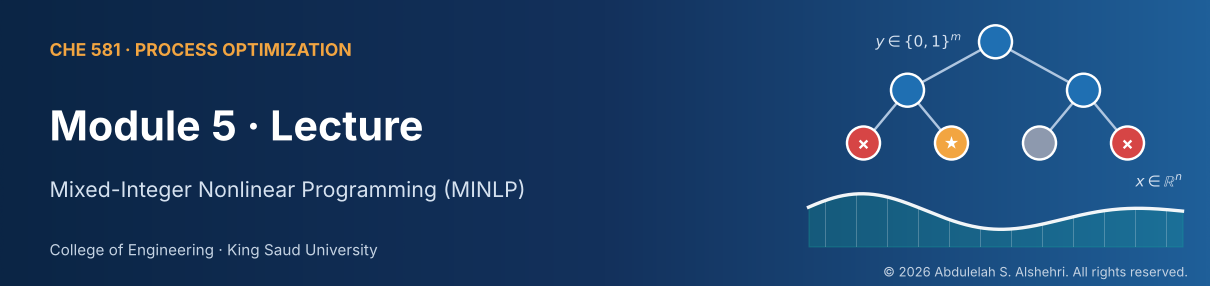

In [ ]:
# ⚙️ Setup: run this cell first (it is hidden in slide mode)
import itertools, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, milp, linprog, LinearConstraint, Bounds, brentq
warnings.filterwarnings("ignore")
try:                                   # sliders work in Colab / Jupyter with ipywidgets
    from ipywidgets import interact, FloatSlider, IntSlider
    HAS_WIDGETS = True
except ImportError:                    # otherwise we simply draw a static plot
    HAS_WIDGETS = False

NAVY, BLUE, TEAL, GOLD, RED, GRAY = "#0B2545", "#1F6FB2", "#13A89E", "#F2A541", "#D64545", "#8D99AE"
plt.rcParams.update({"figure.figsize": (8, 3.4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
print("✅ Setup complete.")

✅ Setup complete.


##  Roadmap & Learning Outcomes

| Part | Slides | Topics |
|---|---|---|
| **A · What is an MINLP?** | 1 – 7 | discrete + nonlinear decisions, standard form, combinatorial explosion, column design, superstructures, logic → binaries |
| **B · Convex MINLP algorithms** | 8 – 15 | bounds, NLP branch & bound, NLP/MILP decomposition, integer cuts, **Outer Approximation**, **GBD**, **ECP**, Pyomo |
| **C · Nonconvex MINLP & global optimization** | 16 – 22 | why nonconvexity hurts, convexification, convex envelopes, **McCormick**, **spatial B&B**, global solvers |
| **D · Fractional objectives** | 23 – 24 | life-cycle optimization per functional unit, MILFP, **Dinkelbach** & reformulation–linearization |

**By the end of this lecture you will be able to:**
1. Recognize a design problem as an **MINLP** and write it in standard form.
2. Translate engineering **logic** (select, exist, imply) into constraints on binary variables.
3. Explain how **relaxations** give lower bounds and **feasible designs** give upper bounds.
4. Run **branch & bound**, **Outer Approximation**, **GBD** and **ECP** by hand on a small problem, and compare them.
5. Spot **nonconvexities**, convexify posynomials, and build **McCormick** / **αBB** relaxations.
6. Describe **spatial branch & bound** and choose a suitable solver.
7. Optimize **cost per functional unit** with Dinkelbach's parametric algorithm.

# Part A
## What is an MINLP?
### *When discrete decisions meet nonlinear physics*

## 1 · Why MINLP?

Chemical engineers make two kinds of decisions **at the same time**:

| 🛠️ Design question | **Discrete** (which / how many / yes-no) | **Continuous** (how much / how big) | Nonlinear because… |
|---|---|---|---|
| Distillation column | number of trays, feed-tray location | reflux ratio, duties, diameter | VLE, enthalpies (MESH) |
| Process synthesis | which reactor, which separator, recycle or not | flows, temperatures, sizes | kinetics, economies of scale |
| Heat-exchanger network | which matches exist | areas, heat loads | $Q = UA\,\Delta T_{lm}$ |
| Supply chain / biorefinery | open a site? which technology? | capacities, shipments | cost per unit, concave capital cost |

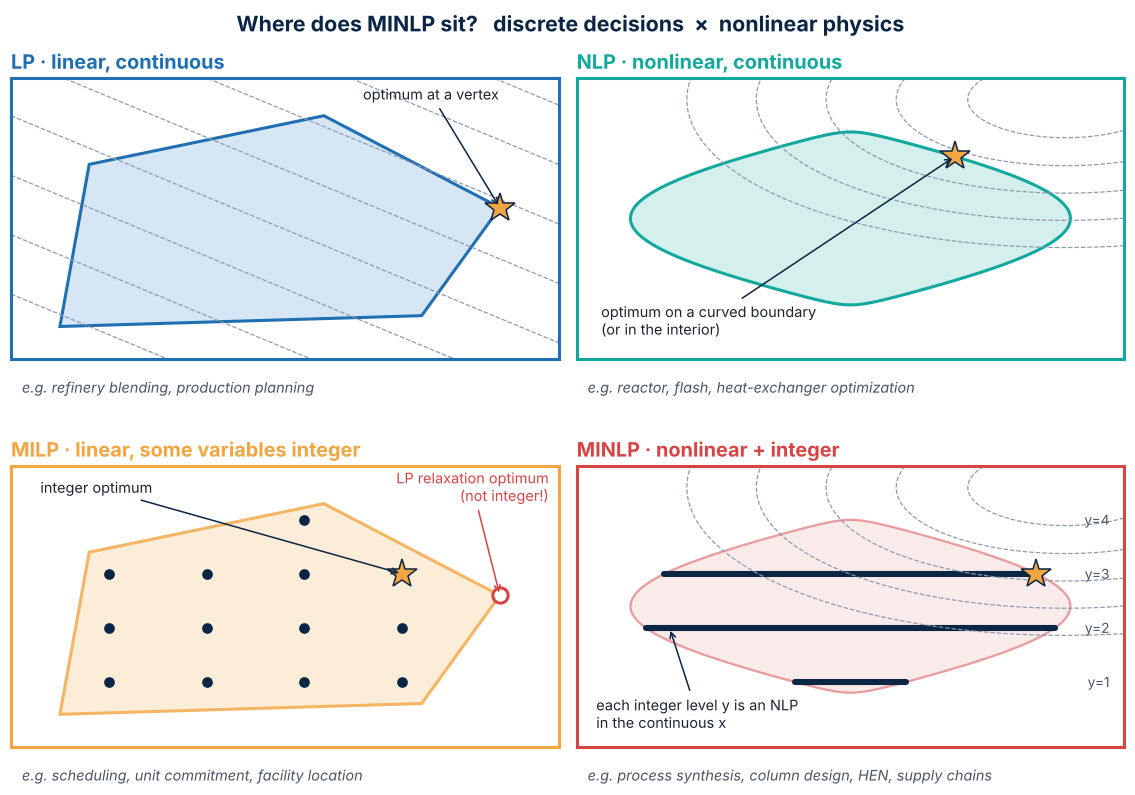

> 🧠 **MINLP = Mixed-Integer (combinatorial choices) + NonLinear (physics & economics).** It inherits the difficulties of **both** MILP and NLP.

## 2 · The general MINLP problem

$$
\begin{aligned}
\min_{x,\,y}\quad & Z = f(x, y) && \text{objective (cost, energy, −profit)}\\
\text{s.t.}\quad & g(x, y) \le 0 && \text{inequality constraints}\\
& h(x, y) = 0 && \text{equality constraints (balances)}\\
& x \in X = \{x \in \mathbb{R}^n : x^L \le x \le x^U,\; Bx \le b\}, && \text{continuous: flows, T, P, sizes}\\
& y \in Y = \{y \in \{0,1\}^m : Ay \le a\} && \text{binary: existence, selection, logic}
\end{aligned}
$$

| Term | Meaning |
|---|---|
| **Convex MINLP** | $f$ and $g$ are **convex** and $h$ is **linear** once $y$ is relaxed to $[0,1]$ → every local optimum of the relaxation is global |
| **Nonconvex MINLP** | anything else (bilinear balances, $x^{0.6}$ cost laws, Arrhenius kinetics, …) → **multiple local optima** |
| Typical structure | $f, g$ **linear in $y$** (e.g. fixed cost $c^\top y$, $F \le U y$) and nonlinear in $x$ |
| Complexity | **NP-hard**: the combinatorial explosion of MILP **plus** the local optima of NLP |

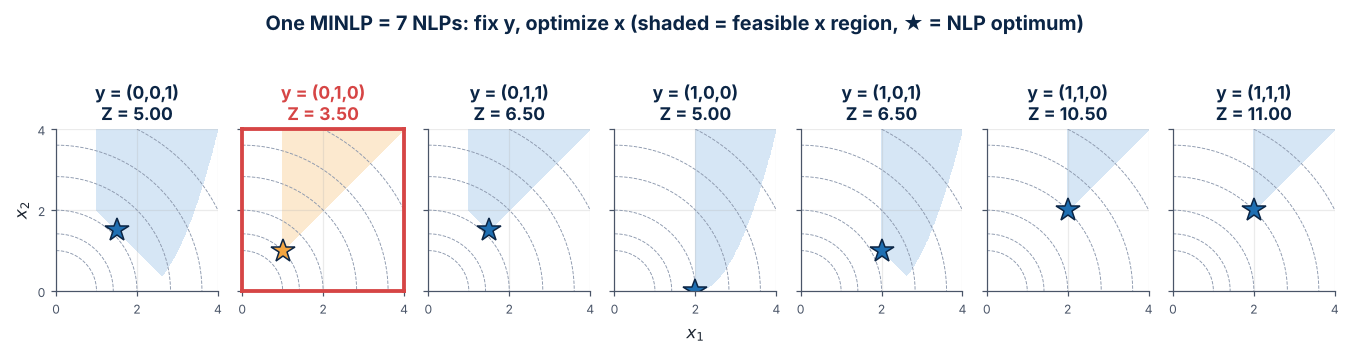

> 🧠 **Fix $y$ ⇒ an NLP in $x$.** A MINLP is a *family* of NLPs, one per feasible $y$. Every algorithm today is a clever way to **avoid** solving all of them.

In [ ]:
# 🔬 One MINLP = a family of NLPs. Fix y, solve the NLP in x, keep the best.
# Duran & Grossmann (1986):  min  y1 + 1.5 y2 + 0.5 y3 + x1² + x2²
def solve_nlp(y):
    y1, y2, y3 = y
    cons = [lambda x: x[1] - (x[0] - 2)**2,           # (x1−2)² − x2 ≤ 0
            lambda x: x[0] - 2*y1,                    # x1 − 2y1 ≥ 0
            lambda x: 4*(1 - y2) - x[0] + x[1],       # x1 − x2 − 4(1−y2) ≤ 0
            lambda x: x[0] - (1 - y1),                # x1 − (1−y1) ≥ 0
            lambda x: x[1] - y2,                      # x2 − y2 ≥ 0
            lambda x: x[0] + x[1] - 3*y3]             # x1 + x2 ≥ 3y3
    r = minimize(lambda x: x[0]**2 + x[1]**2, x0=[1.5, 1.5], bounds=[(0, 4)]*2, method="SLSQP",
                 constraints=[{"type": "ineq", "fun": c} for c in cons])
    feasible = min(c(r.x) for c in cons) > -1e-6
    return (y1 + 1.5*y2 + 0.5*y3 + r.fun, r.x) if feasible else (np.inf, None)

results = []
for y in itertools.product([0, 1], repeat=3):
    if sum(y) < 1: continue                            # logic constraint  y1 + y2 + y3 ≥ 1
    Z, x = solve_nlp(y); results.append((Z, y, x))
    print(f"y = {y}   Z = {Z:6.3f}   x = {np.round(x, 3)}")
Z, y, x = min(results, key=lambda r: r[0])
print(f"\n🏆 best: y = {y}, x = {np.round(x, 3)}, Z = {Z:.3f}   ({len(results)} NLPs solved)")

y = (0, 0, 1)   Z =  5.000   x = [1.5 1.5]
y = (0, 1, 0)   Z =  3.500   x = [1. 1.]
y = (0, 1, 1)   Z =  6.500   x = [1.5 1.5]
y = (1, 0, 0)   Z =  5.000   x = [2. 0.]
y = (1, 0, 1)   Z =  6.500   x = [2. 1.]
y = (1, 1, 0)   Z = 10.500   x = [2. 2.]
y = (1, 1, 1)   Z = 11.000   x = [2. 2.]

🏆 best: y = (0, 1, 0), x = [1. 1.], Z = 3.500   (7 NLPs solved)


## 3 · Why not just enumerate everything?

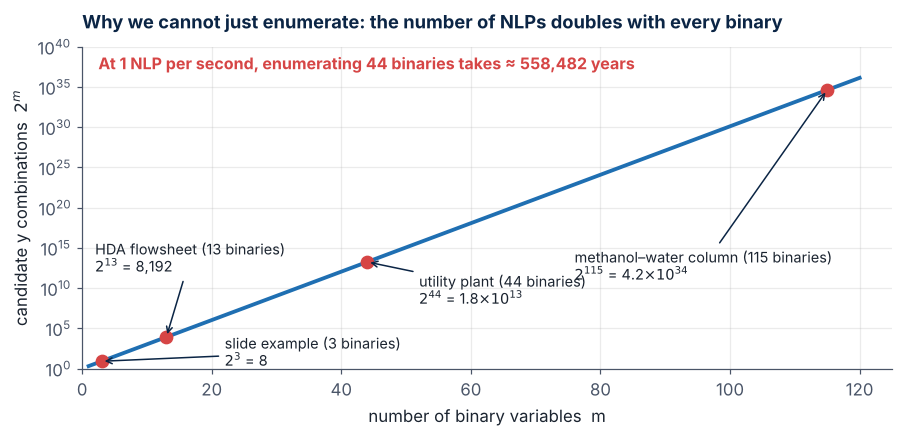

- Every extra binary **doubles** the number of candidate structures.
- Logic constraints help (the 115-binary methanol column has "only" ≈ 700,000 feasible alternatives; the 13-binary HDA superstructure embeds 192 flowsheets), but each alternative is a **large nonconvex NLP**.
- We need algorithms that **prove** optimality while visiting very few $y$'s:

> 🧠 **Key idea of the whole module.** Squeeze the optimum between a **lower bound** (from a *relaxation*: an easier problem whose optimum can only be better) and an **upper bound** (from any *feasible design*). Stop when they meet: $\;LB \le Z^* \le UB$.

bold text## 4 ·  Application: distillation column design

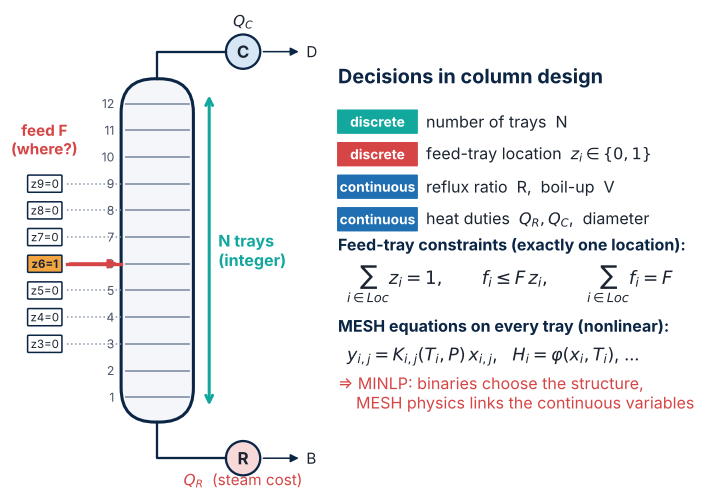

- **Feed-tray location (MINLP):** $\min$ cost s.t. MESH equations, $\sum_{i\in Loc} z_i = 1$, $\;f_i \le F z_i$, $\;\sum_i f_i = F$, $\;z_i\in\{0,1\}$. The optimal feed tray usually has a composition close to the feed.
- **Number of trays:** binaries decide whether each tray **exists**. ⚠️ A non-existing tray has **zero flows**, which makes the MESH equations degenerate: careful formulations (e.g. bypass trays, disjunctions) are needed.
- **Industrial scale** (methanol–water column with 3 feeds, Air Products): **115 binaries, 1,683 continuous variables, 1,919 constraints** → optimum: **53 trays**, feeds on trays 4, 6 and 12.

## 5 · The integer–continuous trade-off: trays vs. reflux

A **shortcut** column model already gives a small MINLP: choose the **number of stages $N$ (integer)** and the **reflux ratio $R$ (continuous)** for a benzene–toluene-like split ($\alpha = 2.5$, $z_F = 0.5$, $x_D = 0.98$, $x_B = 0.02$, $F$ = 100 kmol/h).

- **Fenske** (fewest stages, total reflux): $\;N_{min} = \ln\!\Big[\frac{x_D}{1-x_D}\cdot\frac{1-x_B}{x_B}\Big] \Big/ \ln\alpha = 8.49$
- **Underwood** (least reflux, infinite stages): $\;R_{min} = 1.24$
- **Gilliland** (Molokanov form) links the two: $\;Y = \mathcal{G}(X)$ with $\;Y = \frac{N - N_{min}}{N+1}$, $\;X = \frac{R - R_{min}}{R+1}$
- **Cost:** $\;\text{TAC} = \underbrace{c_{tray}\,N\sqrt{V/100}}_{\text{capital}} + \underbrace{c_E\,V}_{\text{energy}}$ with boil-up $V = (R+1)D$

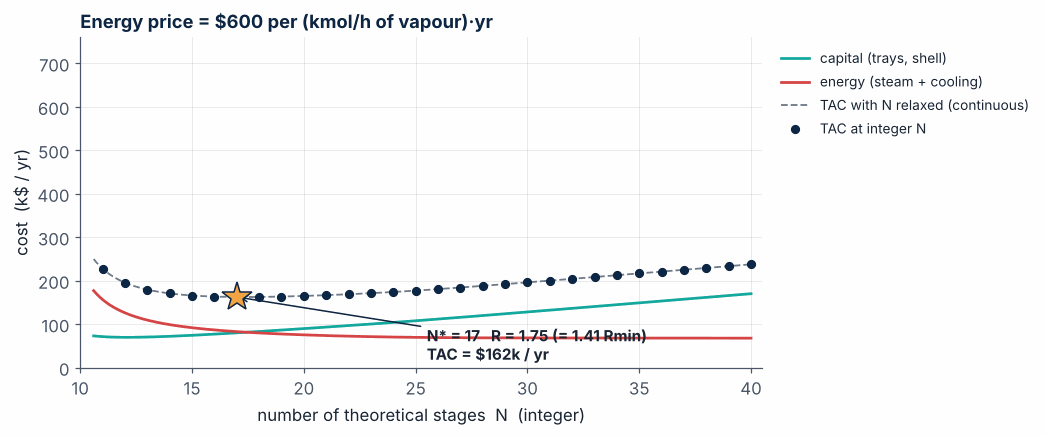

> 🧠 As energy gets **more expensive**, the optimum buys **more trays** to run at a **lower reflux**. A discrete decision reacts to a continuous price.

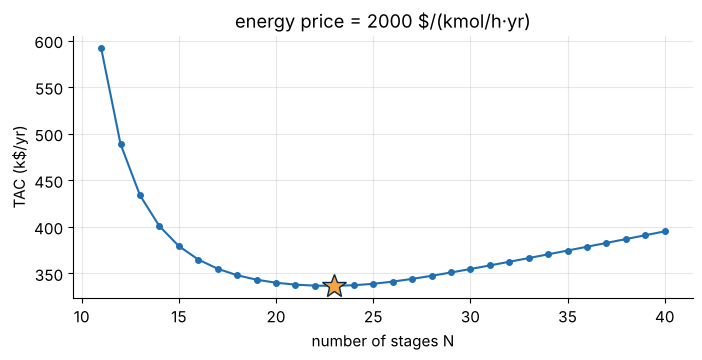

N* = 23,  R* = 1.366 (= 1.10·Rmin),  TAC = $336,662/yr   |   relaxed optimum N = 22.76


In [ ]:
# 🎚️ Interactive: shortcut column design as a 1-integer MINLP (move the energy-price slider)
alpha, F, zF, xD, xB = 2.5, 100.0, 0.5, 0.98, 0.02
Nmin = np.log(xD/(1 - xD) * (1 - xB)/xB) / np.log(alpha)          # Fenske
Rmin = (xD/zF - alpha*(1 - xD)/(1 - zF)) / (alpha - 1)            # Underwood (saturated-liquid feed)
D = F*(zF - xB)/(xD - xB)                                         # distillate flow (kmol/h)

def reflux(N):                                                    # Gilliland correlation (Molokanov form)
    Y = (N - Nmin)/(N + 1)
    X = brentq(lambda X: 1 - np.exp((1 + 54.4*X)/(11 + 117.2*X)*(X - 1)/np.sqrt(X)) - Y, 1e-12, 1 - 1e-12)
    return (X + Rmin)/(1 - X)

def tac(N, c_energy):                                             # total annualized cost ($/yr)
    V = (reflux(N) + 1)*D                                         # vapour boil-up (kmol/h)
    return 4000*N*np.sqrt(V/100) + c_energy*V                     # trays × diameter  +  steam & cooling

def design(c_energy=2000):
    Ns = np.arange(11, 41); cost = np.array([tac(N, c_energy) for N in Ns]); k = int(np.argmin(cost))
    N_relaxed = minimize_scalar(lambda N: tac(N, c_energy), bounds=(10.5, 40), method="bounded").x
    plt.plot(Ns, cost/1e3, "o-", color=BLUE, ms=4); plt.plot(Ns[k], cost[k]/1e3, "*", ms=18, color=GOLD, mec=NAVY)
    plt.xlabel("number of stages N"); plt.ylabel("TAC (k$/yr)")
    plt.title(f"energy price = {c_energy} $/(kmol/h·yr)"); plt.show()
    print(f"N* = {Ns[k]},  R* = {reflux(Ns[k]):.3f} (= {reflux(Ns[k])/Rmin:.2f}·Rmin),  TAC = ${cost[k]:,.0f}/yr"
          f"   |   relaxed optimum N = {N_relaxed:.2f}")

if HAS_WIDGETS:
    interact(design, c_energy=IntSlider(value=2000, min=500, max=5000, step=250))
else:
    design()

## 6 ·  Process synthesis with superstructures

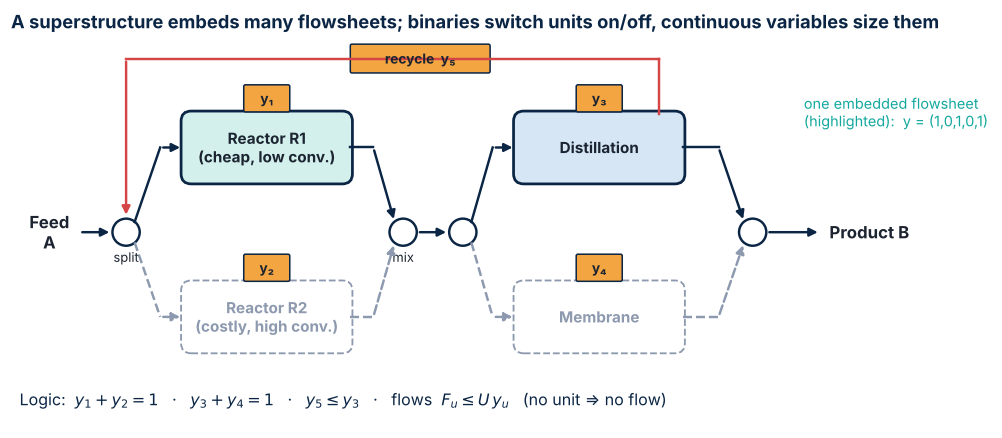

| Industrial example (F. You, CHEME 6800) | Binaries | Continuous | Constraints | Result |
|---|---|---|---|---|
| **HDA process** (toluene → benzene), 192 embedded flowsheets | 13 | 723 | 719 | profit **\$4.06 M/yr** |
| **Utility plant** (turbines, boilers, headers at 45/20/7 bar) | 44 | 1,275 | 1,309 | cost **\$307.27 M/yr** (nonconvex) |
| **Delta III launch vehicle**: type & number of 9 strap-on boosters (5 types) + trajectory | discrete | dynamic | ODEs | max. final mass |
| **Biofuel supply chain** (life-cycle optimization, Illinois) | 244 | 131,351 | 30,826 | Pareto cost vs. emissions |

> 🧠 The superstructure is a **map of all alternatives**. The MINLP's binaries pick the **structure**, its continuous variables pick the **operation and sizes**, and the optimizer explores the map for you.

## 7 · Modeling toolbox: logic → constraints on binaries

| Logic statement | Constraint ($y \in \{0,1\}$) |
|---|---|
| Choose **exactly one** reactor | $y_1 + y_2 + y_3 = 1$ |
| Choose **at most one** separator | $y_4 + y_5 \le 1$ |
| Recycle **only if** distillation is chosen ($y_5 \Rightarrow y_3$) | $y_5 \le y_3$ |
| **No unit ⇒ no flow** | $0 \le F \le F^U y$ |
| **Semicontinuous** flow: off, or between $F^L$ and $F^U$ | $F^L y \le F \le F^U y$ |
| **Either** $g_1(x) \le 0$ **or** $g_2(x) \le 0$ (big-M) | $g_1(x) \le M(1-y)$, $\;g_2(x) \le M y$ |
| Fixed + variable cost | $\text{cost} = c^{fix} y + c^{var} F$ |
| **Product** $w = x\,y$ with $0 \le x \le U$ (Glover) | $w \le U y$, $\;w \le x$, $\;w \ge x - U(1-y)$, $\;w \ge 0$ |
| Powers of binaries | $y^n = y$, so $y^2$, $\sqrt{y}$ are **linear** in disguise |

⚠️ Choose **big-M as small as possible** (use physical bounds). A huge $M$ gives a weak relaxation (poor lower bounds) and numerical trouble.

In [ ]:
# ✅ Check the Glover linearization of w = x·y  (x ∈ [0, U], y ∈ {0,1}) by brute force
U = 10
for y in (0, 1):
    for x in (0.0, 3.7, 10.0):
        lo = max(0, x - U*(1 - y)); hi = min(U*y, x)      # w ≥ x − U(1−y), w ≥ 0, w ≤ U y, w ≤ x
        print(f"y = {y}, x = {x:4.1f}:  feasible w ∈ [{lo:4.1f}, {hi:4.1f}]   → forces w = x·y = {x*y:4.1f}")

y = 0, x =  0.0:  feasible w ∈ [ 0.0,  0.0]   → forces w = x·y =  0.0
y = 0, x =  3.7:  feasible w ∈ [ 0.0,  0.0]   → forces w = x·y =  0.0
y = 0, x = 10.0:  feasible w ∈ [ 0.0,  0.0]   → forces w = x·y =  0.0
y = 1, x =  0.0:  feasible w ∈ [ 0.0,  0.0]   → forces w = x·y =  0.0
y = 1, x =  3.7:  feasible w ∈ [ 3.7,  3.7]   → forces w = x·y =  3.7
y = 1, x = 10.0:  feasible w ∈ [10.0, 10.0]   → forces w = x·y = 10.0


##  Check Your Understanding 1 — Formulating MINLPs

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Classify each problem as LP, NLP, MILP or MINLP: (a) choose the reflux ratio of an existing column to minimize steam use; (b) choose which of 5 heat exchangers to buy **and** their areas; (c) schedule 10 batches on 3 reactors with linear costs.

<details><summary><b> Show answer</b></summary>

(a) **NLP** (continuous, nonlinear VLE). (b) **MINLP** (binary purchase decisions + nonlinear $Q = UA\Delta T_{lm}$). (c) **MILP** (assignment binaries, linear model).

</details>

**Q2.** A compressor may only run between 10 and 50 kmol/h, **and only if it is purchased** ($y$). Write the constraint.

<details><summary><b> Show answer</b></summary>

$10\,y \le F \le 50\,y$. If $y = 0$ then $F = 0$; if $y = 1$ then $10 \le F \le 50$.

</details>

**Q3.** How many NLPs would full enumeration need with **20** unconstrained binaries?

<details><summary><b> Show answer</b></summary>

$2^{20} = $ **1,048,576** NLPs. At 1 s each, that is about 12 days, for a *small* problem.

</details>

**Q4.** **Predict, then run the cell below:** if the energy price doubles from 2,000 to 4,000, does the optimal number of stages go up or down? What happens to $R/R_{min}$?

<details><summary><b> Show answer</b></summary>

$N^*$ goes **up** (23 → 25) and $R/R_{min}$ goes **down** (1.10 → 1.06): with expensive steam it pays to buy more trays and boil up less.

</details>


In [ ]:
for price in (2000, 4000):
    Ns = np.arange(11, 41); cost = [tac(N, price) for N in Ns]; N = Ns[int(np.argmin(cost))]
    print(f"energy price {price}:  N* = {N},  R*/Rmin = {reflux(N)/Rmin:.2f}")

energy price 2000:  N* = 23,  R*/Rmin = 1.10
energy price 4000:  N* = 25,  R*/Rmin = 1.06


# Part B
## Algorithms for Convex MINLP
### *Branch & bound, Outer Approximation, Benders, cutting planes*

## 8 · Convex MINLP, relaxations and bounds

Most convex-MINLP algorithms assume the structure (linear in $y$, convex in $x$):

$$\min_{x,y}\; Z = c^\top y + f(x) \quad \text{s.t.}\quad g(x) + B y \le 0,\quad A y \le a,\quad x \in X,\; y \in \{0,1\}^m$$

Four kinds of **subproblems** appear again and again:

| Subproblem | What is done to $y$ | Type | Gives |
|---|---|---|---|
| **NLP relaxation** | $0 \le y \le 1$ (continuous) | convex NLP | **lower bound** (LB) |
| **NLP-U** (fixed $y^k$) | $y = y^k$ fixed | convex NLP in $x$ | **upper bound** (UB) if feasible |
| **NLP-F** (feasibility) | $y = y^k$ fixed, $\min u$ s.t. $g(x) + By^k \le u$ | convex NLP | a point to cut at if NLP-U is infeasible |
| **MILP master** | $y$ binary, nonlinear functions **linearized** | MILP | **lower bound** + a new $y^{k+1}$ |

- Nonlinear terms in $y$ can often be moved into $x$ (e.g. $y^n = y$; $\;x\,y$ via Glover).
- Equalities $h(x) = 0$ must be **linear** for convexity (a nonlinear equality is never a convex constraint).

> 🧠 **Relax ⇒ lower bound. Restrict / fix ⇒ upper bound.** Every algorithm in Part B is a different strategy to close the gap $UB - LB$.

## 9 · NLP-based Branch & Bound (Gupta & Ravindran, 1985)

Like MILP branch & bound, but each node solves an **NLP relaxation** with some $y_j$ fixed.

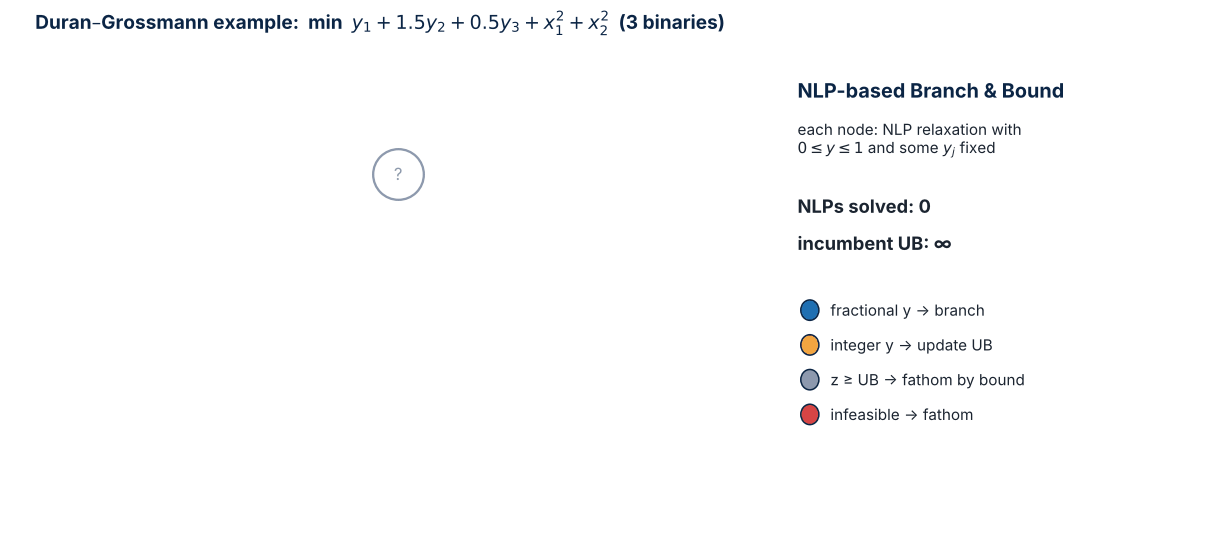

**Fathoming (pruning) rules** at a node with relaxation value $z$:
1. NLP **infeasible** → prune. 2. $z \ge UB$ → prune **by bound**. 3. $y$ **integer** → new incumbent, $UB = z$.

Otherwise **branch** on a fractional $y_j$ (e.g. the most fractional): children $y_j = 0$ and $y_j = 1$.

| ✅ Advantages | ⚠️ Disadvantages |
|---|---|
| tight formulations may need only a few NLPs | potentially **many NLPs**, each nonlinear |
| straightforward, global optimum for convex problems | NLPs at nodes can be slow to warm-start |

In [ ]:
# 🌳 NLP-based branch & bound on the same example (y relaxed to 0 ≤ y ≤ 1 at every node)
def relaxed_nlp(fixed):                                   # fixed = {index j: value of y_j}
    obj  = lambda z: z[2] + 1.5*z[3] + 0.5*z[4] + z[0]**2 + z[1]**2     # z = [x1, x2, y1, y2, y3]
    cons = [lambda z: z[1] - (z[0]-2)**2, lambda z: z[0] - 2*z[2], lambda z: 4*(1-z[3]) - z[0] + z[1],
            lambda z: z[0] - (1 - z[2]),  lambda z: z[1] - z[3],   lambda z: z[0] + z[1] - 3*z[4],
            lambda z: z[2] + z[3] + z[4] - 1]
    bnds = [(0, 4), (0, 4)] + [(fixed.get(j, 0), fixed.get(j, 1)) for j in range(3)]
    r = minimize(obj, [1.5, 1.5, .5, .5, .5], bounds=bnds, method="SLSQP",
                 constraints=[{"type": "ineq", "fun": c} for c in cons])
    return (r.fun, r.x[2:]) if min(c(r.x) for c in cons) > -1e-6 else (np.inf, None)

UB, best, count, stack = np.inf, None, 0, [{}]           # depth-first search: a stack of nodes
while stack:
    node = stack.pop(); z, y = relaxed_nlp(node); count += 1
    label = ", ".join(f"y{j+1}={v}" for j, v in node.items()) or "root"
    if z >= UB - 1e-9:
        print(f"{label:12}  z = {z:6.3f}  → fathom (bound or infeasible)"); continue
    frac = np.abs(y - np.round(y))
    if frac.max() < 1e-4:
        UB, best = z, np.round(y); print(f"{label:12}  z = {z:6.3f}  → integer: new UB"); continue
    j = int(np.argmax(frac)); print(f"{label:12}  z = {z:6.3f}  y = {np.round(y, 2)} → branch on y{j+1}")
    stack += [{**node, j: 1}, {**node, j: 0}]
print(f"\n🏆 Z* = {UB:.3f} at y = {best.astype(int)}   using {count} NLPs (enumeration needs 7)")

root          z =  2.532  y = [0.38 0.   0.62] → branch on y3
y3=0          z =  3.049  y = [0.59 0.41 0.  ] → branch on y1
y3=0, y1=0    z =  3.500  → integer: new UB
y3=0, y1=1    z =  5.000  → fathom (bound or infeasible)
y3=1          z =  5.000  → fathom (bound or infeasible)

🏆 Z* = 3.500 at y = [0 1 0]   using 5 NLPs (enumeration needs 7)


## 10 · Decomposition: NLP subproblems ⇄ MILP master

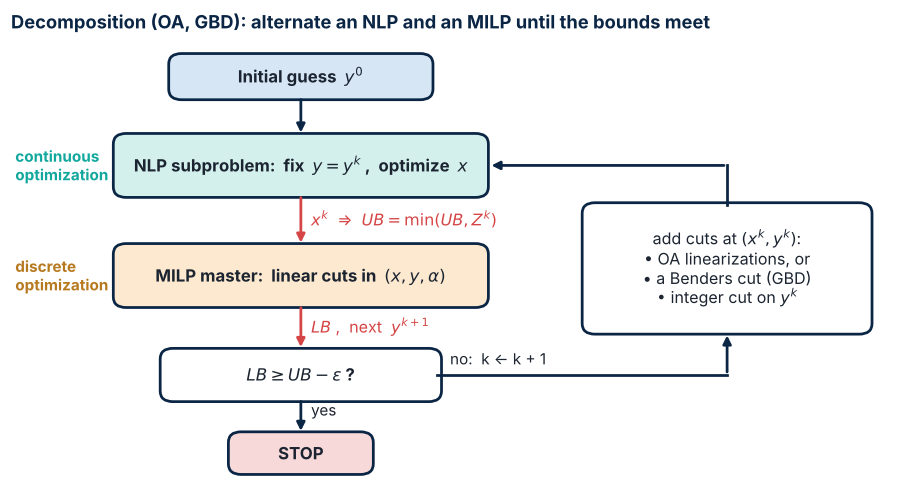

- **NLP-U at fixed $y^k$:** $\;\min_x\; c^\top y^k + f(x)\;$ s.t. $\;g(x) + By^k \le 0,\; x\in X$ → valid **upper bound**.
- **NLP-F** (if NLP-U is infeasible): $\;\min_{x,u}\; u\;$ s.t. $\;g(x) + By^k \le u$. If $u > 0$, $y^k$ is infeasible; linearize at its solution.
- **MILP master:** a **linear** outer description of the MINLP, built from the points visited so far → valid **lower bound**.

## 10b · Integer cuts: never visit the same $y$ twice

To exclude the single binary point $y^k$, split the indices into $B = \{j : y_j^k = 1\}$ and $N = \{j : y_j^k = 0\}$:

$$\boxed{\;\sum_{j\in B} y_j \;-\; \sum_{j\in N} y_j \;\le\; |B| - 1\;}$$

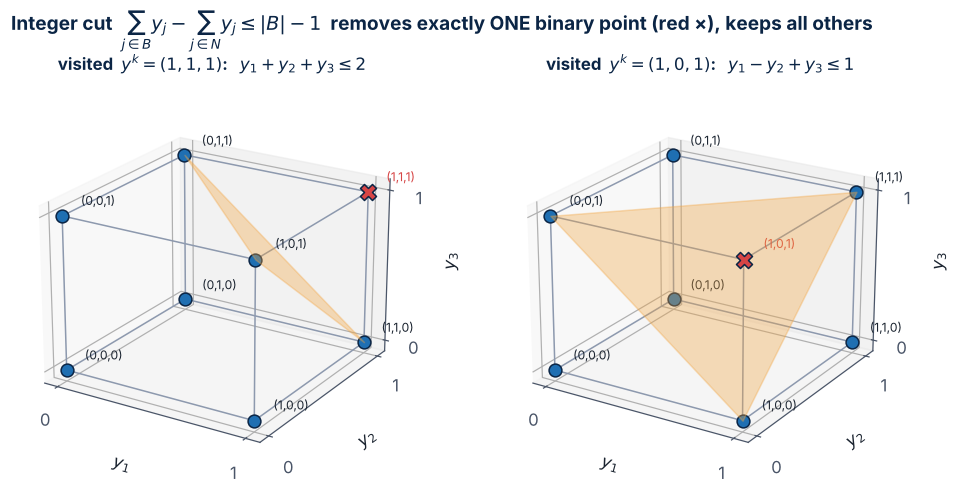

🛠️ Example: $y^k = (1,0,1,1)$ → $B = \{1,3,4\}$, $N = \{2\}$ → $\;y_1 - y_2 + y_3 + y_4 \le 2$.

## 11 · Outer Approximation, OA (Duran & Grossmann, 1986)

For **convex** $f$ and $g$, the tangent planes at any point $x^k$ are global under-estimators:

$$f(x) \ge f(x^k) + \nabla f(x^k)^\top (x - x^k), \qquad g(x) \ge g(x^k) + \nabla g(x^k)^\top (x - x^k)$$

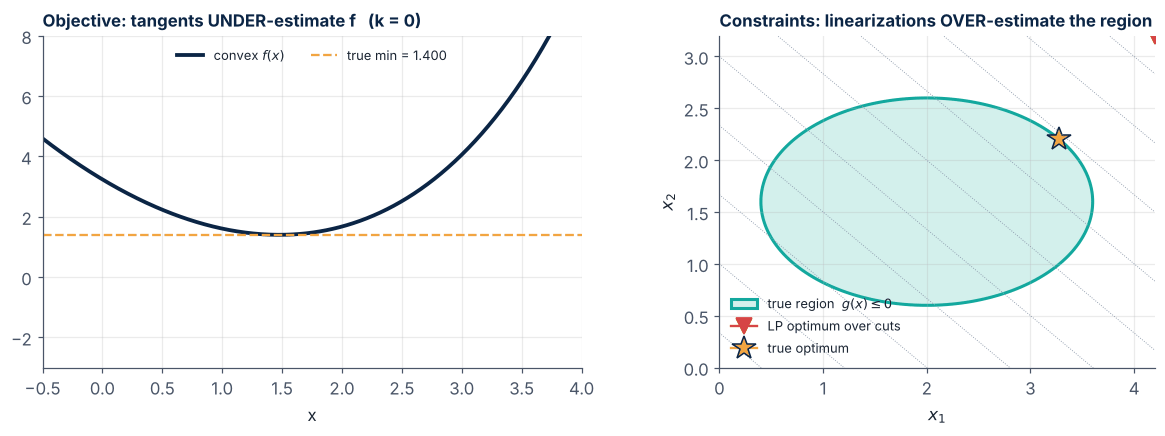

**M-OA master** (an MILP), accumulated over all visited points $k = 1, \dots, K$:

$$
\begin{aligned}
\min\; & \alpha \\
\text{s.t.}\; & \alpha \ge c^\top y + f(x^k) + \nabla f(x^k)^\top (x - x^k) \\
& g(x^k) + \nabla g(x^k)^\top (x - x^k) + By \le 0 \qquad k = 1,\dots,K\\
& Ay \le a,\; x\in X,\; y \in \{0,1\}^m
\end{aligned}
$$

- Lower bounds are **non-decreasing**; for a convex MINLP OA converges finitely to the **global** optimum.
- If $f$ and $g$ are **linear**, the master *is* the original MILP → OA converges in **one** iteration.
- In practice OA linearizes **all** constraints at $x^k$; inactive ones just give loose cuts. The cuts always **contain** the true feasible region (they over-estimate it), so no feasible design is ever cut off.

## 12 · 🛠️ OA worked example, step by step

$$\min\; f = y_1 + y_2 + x_1^2 + x_2^2 \quad\text{s.t.}\quad (x_1-2)^2 - x_2 \le 0,\;\; x_1 - 2y_1 \ge 0,\;\; x_1 - x_2 - 3(1-y_1) \ge 0,$$
$$x_1 + y_1 - 1 \ge 0,\;\; x_2 - y_2 \ge 0,\;\; x_1 + x_2 \ge 3y_1,\;\; y_1 + y_2 \ge 1,\;\; 0 \le x \le 4,\;\; y \in \{0,1\}^2$$

- **Step 1a · NLP at $y = (1,1)$:** $\;\min\, 2 + x_1^2 + x_2^2$ → $x = (2, 1)$ → **UB = 7**
- **Step 1b · MILP master** with cuts at $x^* = (2,1)$: $\;\alpha \ge y_1 + y_2 + 5 + 4(x_1-2) + 2(x_2-1)$, $\;-x_2 \le 0$, linear constraints, integer cut $y_1 + y_2 \le 1$ → $y = (1,0)$, $x = (2,1)$ → **LB = 6**
- **Step 2a · NLP at $y = (1,0)$:** $\;\min\, 1 + x_1^2 + x_2^2$ → $x = (2, 1)$ → **UB = 6 = LB** ✅ optimal after only 2 NLPs and 1 MILP

The linearizations at $x^* = (2,1)$: $\;f = x_1^2 + x_2^2$ has $\nabla f = (4, 2)$ so $f \approx 5 + 4(x_1-2) + 2(x_2-1)$; $\;g = (x_1-2)^2 - x_2$ has $\nabla g = (0,-1)$ so $g \approx -1 - (x_2 - 1) = -x_2$.

In [ ]:
# 🔬 Step 1b by hand: build the OA master MILP explicitly.   variables z = [x1, x2, y1, y2, alpha]
rows = [([ 4,  2,  1,  1, -1],  5),     # alpha ≥ y1 + y2 + 5 + 4(x1−2) + 2(x2−1)
        ([ 0, -1,  0,  0,  0],  0),     # OA cut of (x1−2)² − x2 ≤ 0 at x* = (2,1):  −x2 ≤ 0
        ([-1,  0,  2,  0,  0],  0),     # x1 − 2y1 ≥ 0
        ([-1,  1, -3,  0,  0], -3),     # x1 − x2 − 3(1−y1) ≥ 0
        ([-1,  0, -1,  0,  0], -1),     # x1 + y1 − 1 ≥ 0
        ([ 0, -1,  0,  1,  0],  0),     # x2 − y2 ≥ 0
        ([-1, -1,  3,  0,  0],  0),     # x1 + x2 ≥ 3y1
        ([ 0,  0, -1, -1,  0], -1),     # y1 + y2 ≥ 1
        ([ 0,  0,  1,  1,  0],  1)]     # integer cut that removes y = (1,1)
A = np.array([r for r, _ in rows], float); b = np.array([rhs for _, rhs in rows], float)
res = milp(c=[0, 0, 0, 0, 1], constraints=LinearConstraint(A, -np.inf, b), integrality=[0, 0, 1, 1, 0],
           bounds=Bounds([0, 0, 0, 0, -100], [4, 4, 1, 1, 100]))
x1, x2, y1, y2, alpha = res.x
print(f"master:  y = ({y1:.0f}, {y2:.0f}),  x = ({x1:.2f}, {x2:.2f}),  LB = alpha = {alpha:.3f}")
print(f"NLP at that y gives  UB = {y1 + y2 + x1**2 + x2**2:.3f}   →  LB = UB  ⇒  optimal ✅")

master:  y = (1, 0),  x = (2.00, 1.00),  LB = alpha = 6.000
NLP at that y gives  UB = 6.000   →  LB = UB  ⇒  optimal ✅


## 13 · Generalized Benders Decomposition, GBD (Geoffrion, 1972)

Take the OA cuts at $(x^k, y^k)$ and **eliminate $x$** using the KKT multipliers $\mu^k \ge 0$ of $g(x) + By \le 0$ from NLP-U:

$$\text{Benders (optimality) cut:}\qquad \alpha \;\ge\; c^\top y + f(x^k) + (\mu^k)^\top\big[g(x^k) + B y\big]$$
$$\text{Feasibility cut (NLP-U infeasible):}\qquad (\lambda^k)^\top\big[g(x^k) + B y\big] \le 0$$

**Where does it come from?** KKT of NLP-U: $\nabla f(x^k) + (\mu^k)^\top \nabla g(x^k) = 0$. Multiply by $(x - x^k)$ and use convexity of $g$ on the OA cut for $g$:
$\;\nabla f(x^k)^\top(x - x^k) = -(\mu^k)^\top \nabla g(x^k)(x-x^k) \ge (\mu^k)^\top[g(x^k) + By]$, which turns the OA objective cut into the Benders cut (a *surrogate* of the OA cuts).

| | **OA** | **GBD** |
|---|---|---|
| Master variables | $x$ **and** $y$ | $y$ only (+ $\alpha$) |
| Cuts per iteration | one per constraint (+ objective) | **one** aggregated cut |
| Lower bounds | **stronger**: $z^k_{OA} \ge z^k_{GBD}$ | weaker |
| Iterations | fewer | more (but smaller masters) |

## 14 · Extended Cutting Plane (Westerlund & Pettersson, 1995) & comparison

**ECP = no NLPs at all.** 1) Solve the M-OA master MILP → $(x^k, y^k)$. 2) If $\max_j g_j(x^k, y^k) \le \varepsilon$ → stop. 3) Otherwise add the linearization of the **most violated** constraint and repeat.

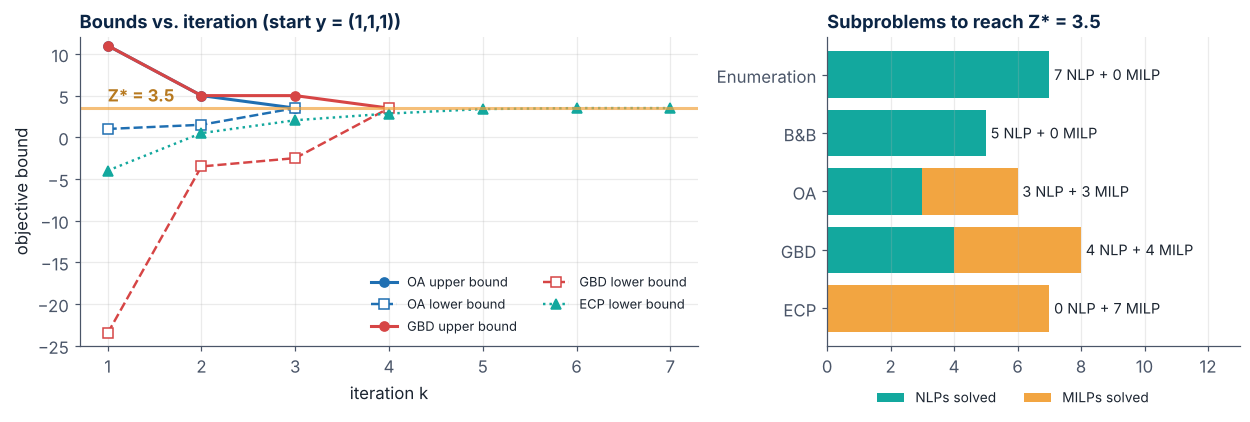

| Method | Solves | Strength | Weakness | Codes |
|---|---|---|---|---|
| **B&B** | NLP per node | simple; good with tight relaxations | many NLPs | SBB, Bonmin (B-BB), Knitro |
| **OA** | NLP + MILP | strong bounds, few iterations | big MILP masters | DICOPT, AOA, Bonmin (B-OA), MindtPy |
| **GBD** | NLP + MILP (in $y$) | small masters | weak bounds, many iterations | MINOPT, GAMS/LogMIP; easy to code (Tutorial 5) |
| **ECP** | MILPs only | cheap when NLPs are expensive | slow convergence | α-ECP, MindtPy (ECP) |
| **LP/NLP B&B** (Quesada & Grossmann, 1992) | one MILP tree + NLPs at integer nodes | "single-tree" OA | needs MILP-solver callbacks | Bonmin (B-Hyb), FilMINT, MindtPy |

> 🧠 On the 3-binary example: **B&B 5 NLPs · OA 3 NLP + 3 MILP · GBD 4 NLP + 4 MILP · ECP 7 MILPs** — exactly the trade-offs in the table.

## 15 · Solving MINLPs in Python with Pyomo

| Pyomo call | Algorithm | Notes |
|---|---|---|
| `SolverFactory("mindtpy").solve(m, strategy="OA")` | Outer Approximation | also `"ECP"`, `"GOA"`, `"FP"`; needs an MILP + an NLP solver |
| `SolverFactory("bonmin")` | B&B / OA / hybrid (convex) | COIN-OR, open source |
| `SolverFactory("couenne")` | spatial B&B (global) | COIN-OR, open source |
| `SolverFactory("scip")`, `("baron")`, `("gams")` | global / commercial | BARON needs a license; GAMS gives DICOPT, SBB, … |

**Practical tips:** give **every variable bounds**, keep big-M's small, scale variables to $O(1)$, start from a feasible $y^0$, and **always set the optimality gap explicitly** (defaults differ across solvers and versions).

In [ ]:
# 🐍 The 3-binary example in Pyomo (runs only if Pyomo + solvers are installed; Tutorial 5 shows how)
try:
    try:
        import idaes                     # optional: puts ipopt / bonmin / couenne / cbc on the PATH
    except ImportError:
        pass
    import logging; logging.getLogger("pyomo").setLevel(logging.ERROR)      # hide Pyomo's info/warning chatter
    import pyomo.environ as pyo
    m = pyo.ConcreteModel()
    m.x1, m.x2 = pyo.Var(bounds=(0, 4)), pyo.Var(bounds=(0, 4))
    m.y = pyo.Var([1, 2, 3], domain=pyo.Binary)
    m.obj = pyo.Objective(expr=m.y[1] + 1.5*m.y[2] + 0.5*m.y[3] + m.x1**2 + m.x2**2)
    m.c = pyo.ConstraintList()
    for e in [(m.x1 - 2)**2 - m.x2 <= 0, m.x1 - 2*m.y[1] >= 0, m.x1 - m.x2 - 4*(1 - m.y[2]) <= 0,
              m.x1 - (1 - m.y[1]) >= 0, m.x2 - m.y[2] >= 0, m.x1 + m.x2 >= 3*m.y[3], m.y[1] + m.y[2] + m.y[3] >= 1]:
        m.c.add(e)
    pyo.SolverFactory("mindtpy").solve(m, strategy="OA", mip_solver="appsi_highs", nlp_solver="ipopt")
    print("MindtPy (OA):  Z* =", round(pyo.value(m.obj), 4), "  y =", [round(pyo.value(m.y[j])) for j in (1, 2, 3)],
          "  x =", (round(pyo.value(m.x1), 3), round(pyo.value(m.x2), 3)))
except Exception as err:
    print("Pyomo or its solvers are not available here →", type(err).__name__)
    print("In Colab:  !pip install pyomo highspy idaes-pse  and then  !idaes get-extensions")

MindtPy (OA):  Z* = 3.5   y = [0, 1, 0]   x = (1.0, 1.0)


##  Check Your Understanding 2 — Convex MINLP algorithms

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Which subproblems give **upper** bounds and which give **lower** bounds?

<details><summary><b> Show answer</b></summary>

**Upper:** NLP-U at a fixed $y^k$ (any feasible design). **Lower:** the NLP relaxation ($0 \le y \le 1$) and the MILP master (OA, GBD, ECP), because they **relax** the problem.

</details>

**Q2.** Write the integer cut that removes $y^k = (0, 1, 1, 0, 1)$.

<details><summary><b> Show answer</b></summary>

$B = \{2,3,5\}$, $N = \{1,4\}$: $\;y_2 + y_3 + y_5 - y_1 - y_4 \le 2$.

</details>

**Q3.** Why does OA usually need **fewer** iterations than GBD?

<details><summary><b> Show answer</b></summary>

A Benders cut is a **linear combination** (surrogate) of the OA cuts at the same point, so the OA master is tighter: $z_{OA}^k \ge z_{GBD}^k$. Stronger lower bounds close the gap sooner.

</details>

**Q4.** Why can't OA *guarantee* the global optimum when $f$ or $g$ is nonconvex?

<details><summary><b> Show answer</b></summary>

Tangents of a nonconvex function are **not** under-estimators: the master may **cut off** the global optimum, and the NLP subproblems may stop at **local** optima. (Part C.)

</details>

**Q5.** **Predict, then run:** for $\min y_1 - y_2 + x_1^2 + (x_2-3)^2$ s.t. $2(x_1-1)^2 + (x_2-2)^2 - 3y_2 \le 3$, $x_1 + x_2 \ge 3y_1$, $x_1 - 2y_1 \ge y_2$, $x \ge 0$, which candidates $[x_1, x_2, y_1, y_2]$ are optimal: $[0,3,0,0]$, $[1,0,0,1]$, $[1,3,0,1]$, $[0.5,0,0,0]$?

<details><summary><b> Show answer</b></summary>

$[0,3,0,0]$ and $[1,3,0,1]$ both give $Z = 0$: **alternative optima**. $[1,0,0,1]$ is feasible but $Z = 9$. $[0.5,0,0,0]$ is **infeasible** ($2(0.25) + 4 = 4.5 > 3$); it was only a master (linearized) solution.

</details>

In [ ]:
f = lambda x1, x2, y1, y2: y1 - y2 + x1**2 + (x2 - 3)**2
g = lambda x1, x2, y1, y2: [2*(x1 - 1)**2 + (x2 - 2)**2 - 3*y2 - 3, 3*y1 - x1 - x2, 2*y1 + y2 - x1]   # all ≤ 0
for p in ([0, 3, 0, 0], [1, 0, 0, 1], [1, 3, 0, 1], [0.5, 0, 0, 0]):
    ok = max(g(*p)) <= 1e-9 and min(p[:2]) >= 0
    print(f"{p}:  Z = {f(*p):5.2f}   {'feasible' if ok else 'INFEASIBLE'}")

[0, 3, 0, 0]:  Z =  0.00   feasible
[1, 0, 0, 1]:  Z =  9.00   feasible
[1, 3, 0, 1]:  Z =  0.00   feasible
[0.5, 0, 0, 0]:  Z =  9.25   INFEASIBLE


# Part C
## Nonconvex MINLP & Global Optimization
### *Convexify when you can, relax and branch when you can't*

## 16 · What nonconvexity breaks

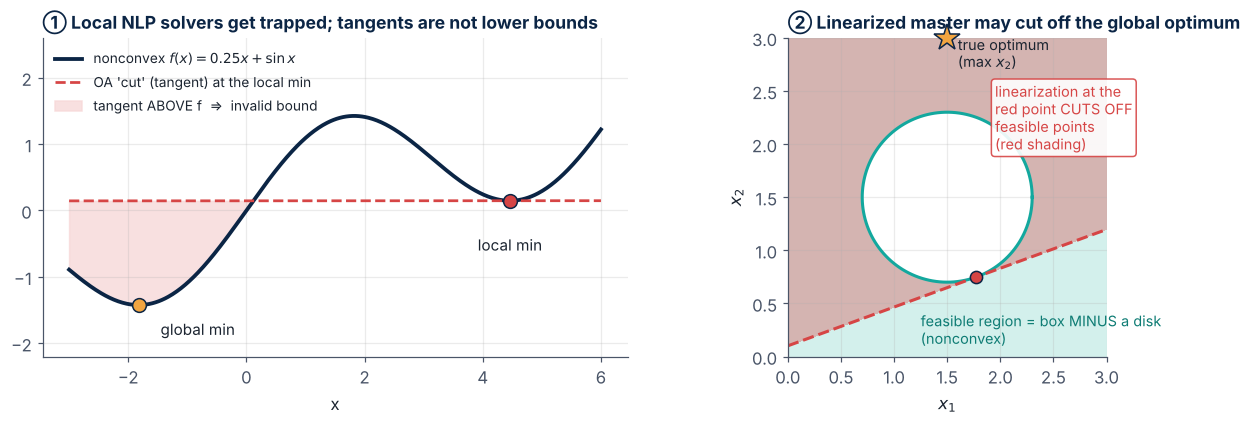

- **NLP subproblems** may return **local** optima → the upper bounds are fine (feasible) but maybe poor.
- **Linearizations are no longer valid** → the MILP master can **cut off the global optimum**, so its "lower bound" is not a bound at all.
- 🛠️ Where it comes from in CHE: bilinear mixing/pooling balances ($F\,x$), $C = a\,V^{0.6}$ capital costs, $UA\Delta T_{lm}$, Arrhenius kinetics, VLE.

| Strategy | How | Guarantee |
|---|---|---|
| **Heuristic** | OA with slacks/penalties on linearizations (DICOPT's augmented penalty), multistart NLPs, stop when the NLP stops improving | good solutions, **no** proof |
| **Rigorous** (global) | replace nonconvex terms by **convex envelopes / underestimators** and use **spatial B&B** | global optimum within $\varepsilon$ |

## 17 · Convexification: posynomials & the exponential transformation

A **posynomial** is $f(x) = \sum_i c_i \prod_j x_j^{\alpha_{ij}}$ with $c_i \ge 0$ and $x_j > 0$ (exponents may be any real numbers). It is usually **nonconvex**, but with $x_j = e^{u_j}$:

$$f(u) = \sum_i c_i\, e^{\sum_j \alpha_{ij} u_j} \qquad \text{(a sum of exponentials of linear functions → convex)}$$

$$\text{Example 1:}\quad \frac{x_1}{x_2} + \sqrt{x_1} \le 1 \;\;\xrightarrow{\;x = e^{u}\;}\;\; e^{u_1 - u_2} + e^{0.5u_1} \le 1 \quad(\textbf{convex})$$
$$\text{Example 2:}\quad \frac{x_1}{x_2} \le x_1^{0.7} \;\;\xrightarrow{\;x = e^{u}\;}\;\; u_1 - u_2 \le 0.7\,u_1 \quad(\textbf{linear!})$$

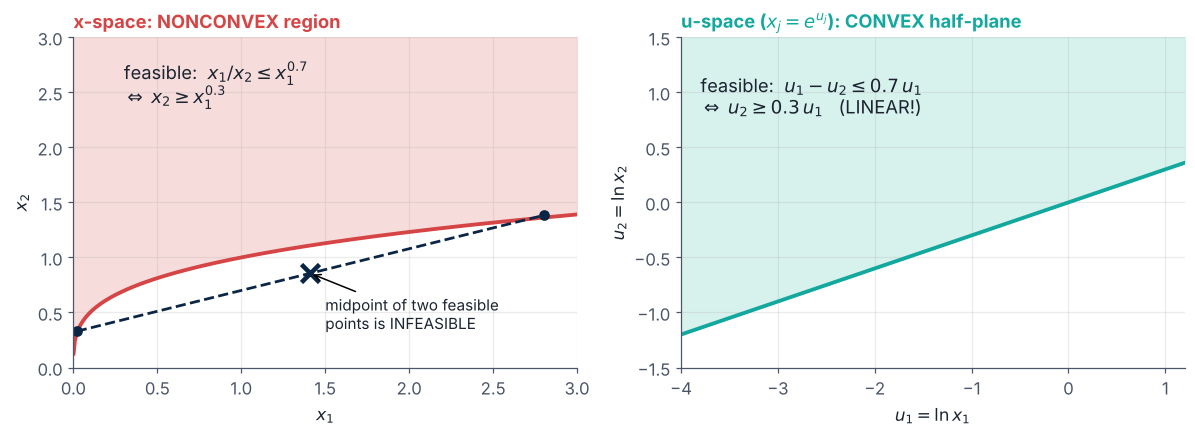

> 🧠 If **all** nonconvexities are posynomials, the exponential transformation turns the MINLP into a **convex** MINLP (geometric programming), and Part B applies with a global guarantee.

In [ ]:
# 🔬 Numerical convexity test: sample the Hessian of Example 1 before and after the transformation
def hessian(fun, z, h=1e-4):
    n = len(z); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            e_i, e_j = np.eye(n)[i]*h, np.eye(n)[j]*h
            H[i, j] = (fun(z+e_i+e_j) - fun(z+e_i-e_j) - fun(z-e_i+e_j) + fun(z-e_i-e_j)) / (4*h*h)
    return H

f_x = lambda x: x[0]/x[1] + np.sqrt(x[0])                 # original, x > 0
f_u = lambda u: np.exp(u[0] - u[1]) + np.exp(0.5*u[0])    # transformed, x = e^u
pts = np.random.default_rng(5).uniform(0.2, 3.0, size=(500, 2))
neg_x = np.mean([np.linalg.eigvalsh(hessian(f_x, p)).min() < -1e-6 for p in pts])
neg_u = np.mean([np.linalg.eigvalsh(hessian(f_u, np.log(p))).min() < -1e-6 for p in pts])
print(f"fraction of sample points with a negative Hessian eigenvalue:  x-space {neg_x:.0%}   u-space {neg_u:.0%}")

fraction of sample points with a negative Hessian eigenvalue:  x-space 100%   u-space 0%


## 18 · Convex relaxations: hulls, underestimators, envelopes

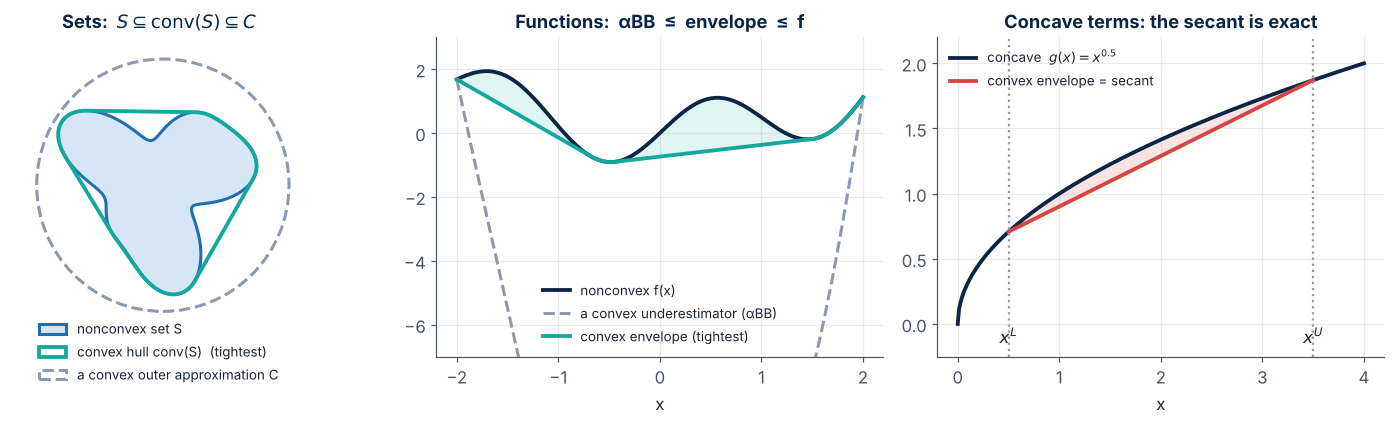

| Concept | Definition | Tightest? |
|---|---|---|
| **Convex outer approximation** $C$ of a set $S$ | $C$ convex and $S \subseteq C$ | no |
| **Convex hull** $\text{conv}(S)$ | the smallest convex set containing $S$ | ✅ |
| **Convex underestimator** $g$ of $f$ on $S$ | $g$ convex and $g(x) \le f(x)$ for all $x \in S$ | no |
| **Convex envelope** $\breve f$ | the largest convex underestimator: $\breve f \ge h$ for every convex underestimator $h$ | ✅ |

- **Concave** term $g(x)$ on $[x^L, x^U]$ (e.g. $x^{0.6}$ capital cost): its convex envelope is the **secant**
$\;\hat g(x) = g(x^L) + \dfrac{g(x^U) - g(x^L)}{x^U - x^L}\,(x - x^L)$.
- **General** twice-differentiable $f$ (αBB, Androulakis, Maranas & Floudas, 1995): $\;L(x) = f(x) + \alpha\,(x^L - x)(x^U - x)$ is convex if $\alpha \ge \max\big(0, -\tfrac12 \min f''\big)$.

## 19 · McCormick envelopes for bilinear terms (McCormick, 1976)

For $w = xy$ with $x^L \le x \le x^U$, $\;y^L \le y \le y^U$:

$$
\begin{aligned}
w &\ge x^L y + x\, y^L - x^L y^L, & \qquad w &\le x^U y + x\, y^L - x^U y^L,\\
w &\ge x^U y + x\, y^U - x^U y^U, & \qquad w &\le x^L y + x\, y^U - x^L y^U.
\end{aligned}
$$

**Derivation (1 line):** $(x - x^L)(y - y^L) \ge 0 \;\Rightarrow\; xy \ge x^L y + x y^L - x^L y^L$. The other three come from the other sign-definite products.

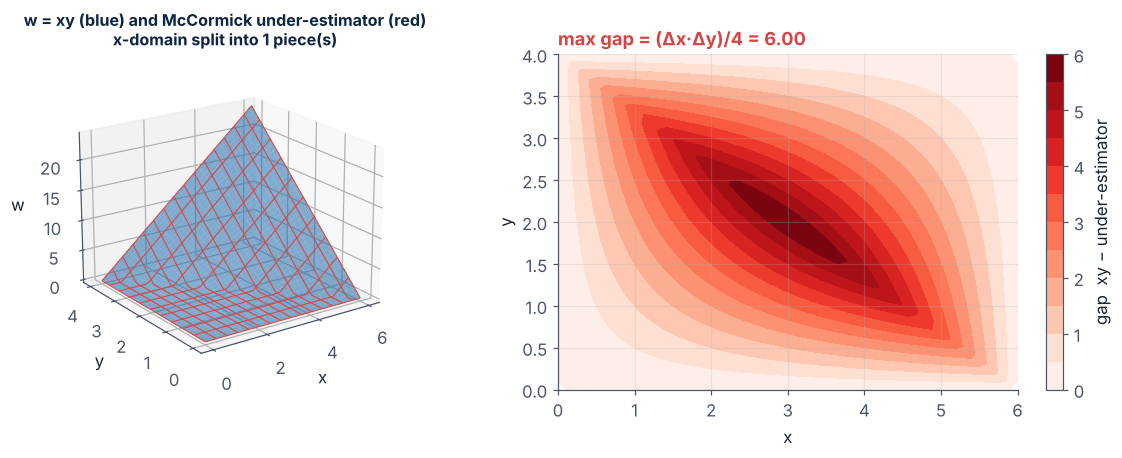

- The envelopes are **exact on the box boundary** (e.g. at $x = x^L$: $w = x^L y$).
- The worst gap is $\tfrac14(x^U - x^L)(y^U - y^L)$ at the box center → **branching on $x$ or $y$ shrinks it**. That is why spatial B&B works.

## 20 · 🛠️ Example: McCormick relaxation of $xy \le 4$

$$\min\; f = -x - y \quad \text{s.t.}\quad xy \le 4,\quad 0 \le x \le 6,\quad 0 \le y \le 4$$

Replace $u = xy$ and add the four McCormick inequalities → an **LP**. With $x^U = 6, y^U = 4$, the cut $u \ge 6y + 4x - 24$ combined with $u \le 4$ gives $\mathbf{4x + 6y \le 28}$: exactly the chord joining $(1,4)$ and $(6, \tfrac23)$ on the hyperbola.

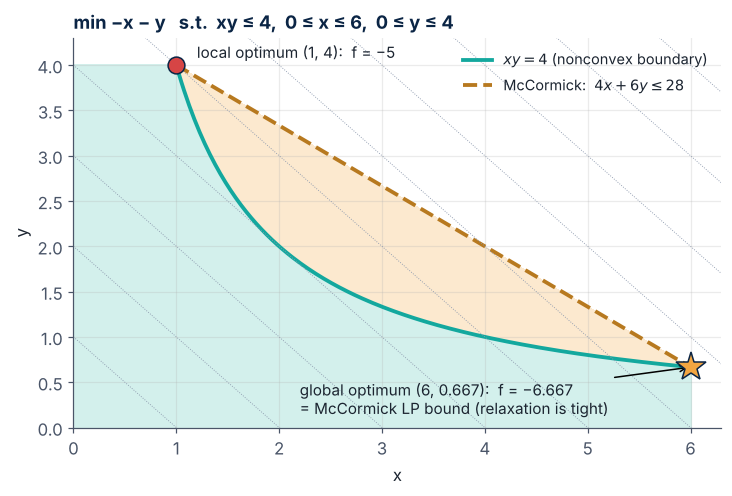

> 🧠 Here the relaxation is **tight** ($LB = -6.667$ = global optimum) in a single LP, while a local NLP solver can stop at $(1,4)$ with $f = -5$, or even at the KKT point $(2,2)$.

In [ ]:
# 🔬 McCormick LP relaxation vs. a local NLP solver started from different points.   z = [x, y, u]
xL, xU, yL, yU = 0, 6, 0, 4
A_ub = [[yL, xL, -1], [yU, xU, -1],          #  u ≥ xL·y + x·yL − xL·yL ,  u ≥ xU·y + x·yU − xU·yU
        [-yL, -xU, 1], [-yU, -xL, 1],        #  u ≤ xU·y + x·yL − xU·yL ,  u ≤ xL·y + x·yU − xL·yU
        [0, 0, 1]]                           #  u ≤ 4   (the relaxed  xy ≤ 4)
b_ub = [xL*yL, xU*yU, -xU*yL, -xL*yU, 4]
lp = linprog([-1, -1, 0], A_ub=A_ub, b_ub=b_ub, bounds=[(xL, xU), (yL, yU), (None, None)], method="highs")
print(f"McCormick LP:   x = {lp.x[0]:.3f}, y = {lp.x[1]:.3f}   lower bound = {lp.fun:.3f}")
for start in [(0.5, 3.5), (2, 2), (5, 0.5)]:
    r = minimize(lambda z: -z[0] - z[1], start, method="SLSQP", bounds=[(0, 6), (0, 4)],
                 constraints=[{"type": "ineq", "fun": lambda z: 4 - z[0]*z[1]}])
    print(f"local NLP from {start}:  x = {r.x[0]:.3f}, y = {r.x[1]:.3f}   f = {r.fun:.3f}")

McCormick LP:   x = 6.000, y = 0.667   lower bound = -6.667
local NLP from (0.5, 3.5):  x = 1.000, y = 4.000   f = -5.000
local NLP from (2, 2):  x = 2.000, y = 2.000   f = -4.000
local NLP from (5, 0.5):  x = 6.000, y = 0.667   f = -6.667


## 21 · Spatial Branch & Bound

| | **B&B for MILP / convex MINLP** | **Spatial B&B for nonconvex MINLP** |
|---|---|---|
| Relaxation | drop integrality → LP / convex NLP | **convex envelopes** of nonconvex terms (+ drop integrality) |
| Branching | on integer variables only | on integer **and continuous** variables (split their range) |
| Complexity | NP-hard, at most $2^n$ leaves | NP-hard, much harder in practice |

**Algorithm** (for a tolerance $\varepsilon$):
1. **Initialize:** region list $= \{S\}$, $UB = +\infty$.
2. **Choose** a region $S_j$ (e.g. the one with the lowest bound).
3. **Lower bound:** solve the convex relaxation on $S_j$ → $l$. If $l \ge UB - \varepsilon$: **prune** $S_j$.
4. **Upper bound:** solve the original problem **locally** on $S_j$ → $u$ (any feasible point counts). If $u < UB$: update $UB$.
5. **Prune** every region whose $l \ge UB - \varepsilon$.
6. If $u - l \le \varepsilon$: $S_j$ is solved. Otherwise **branch** (bisect the variable with the largest relaxation gap) and go to 2.

*(Optional) bound tightening shrinks $[x^L, x^U]$ at each node → tighter envelopes, fewer nodes.*

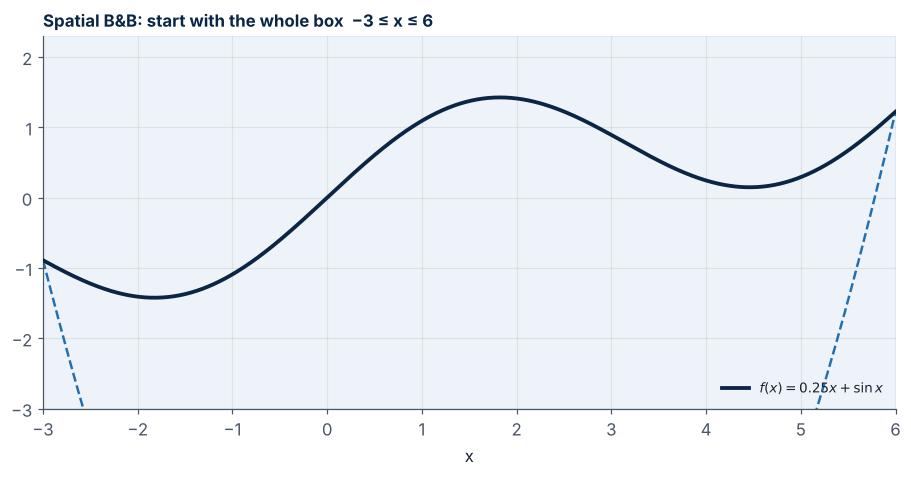

In [ ]:
# 🔬 Spatial B&B in 20 lines:  min 0.25x + sin x  on [−3, 6] with the αBB underestimator (α = 0.5)
f = lambda x: 0.25*x + np.sin(x)
def lower(a, b):                      # convex underestimator L(x) = f(x) + α(a − x)(b − x), minimized exactly
    r = minimize_scalar(lambda x: f(x) + 0.5*(a - x)*(b - x), bounds=(a, b), method="bounded")
    return r.fun, r.x
def upper(a, b, x0):                  # a local solve of the true (nonconvex) problem
    r = minimize(lambda x: f(x[0]), [x0], bounds=[(a, b)]); return r.fun, r.x[0]

UB, xbest, regions, eps, k = np.inf, None, [(-3.0, 6.0)], 1e-3, 0
while regions:
    regions.sort(key=lambda R: lower(*R)[0]); a, b = regions.pop(0); k += 1
    l, xl = lower(a, b)
    if l > UB - eps: continue                                     # prune by bound
    u, xu = upper(a, b, xl)
    if u < UB: UB, xbest = u, xu
    print(f"node {k:2d}: [{a:6.3f}, {b:6.3f}]   l = {l:7.4f}   u = {u:7.4f}   UB = {UB:7.4f}")
    if u - l > eps: regions += [(a, (a + b)/2), ((a + b)/2, b)]   # branch (bisection)
    regions = [R for R in regions if lower(*R)[0] <= UB - eps]   # prune the rest
print(f"\n global minimum certified: x* = {xbest:.3f}, f* = {UB:.4f}")

node  1: [-3.000,  6.000]   l = -9.0345   u = -1.4241   UB = -1.4241
node  2: [-3.000,  1.500]   l = -3.6688   u = -1.4241   UB = -1.4241
node  3: [ 1.500,  6.000]   l = -2.2635   u =  0.1467   UB = -1.4241
node  4: [-3.000, -0.750]   l = -2.0563   u = -1.4241   UB = -1.4241
node  5: [-1.875, -0.750]   l = -1.5176   u = -1.4241   UB = -1.4241
node  6: [-3.000, -1.875]   l = -1.4913   u = -1.4228   UB = -1.4241
node  7: [-1.875, -1.312]   l = -1.4506   u = -1.4241   UB = -1.4241
node  8: [-2.438, -1.875]   l = -1.4367   u = -1.4228   UB = -1.4241
node  9: [-1.875, -1.594]   l = -1.4320   u = -1.4241   UB = -1.4241
node 10: [-1.875, -1.734]   l = -1.4265   u = -1.4241   UB = -1.4241

🏆 global minimum certified: x* = -1.823, f* = -1.4241


## 22 · Global solvers & how to choose

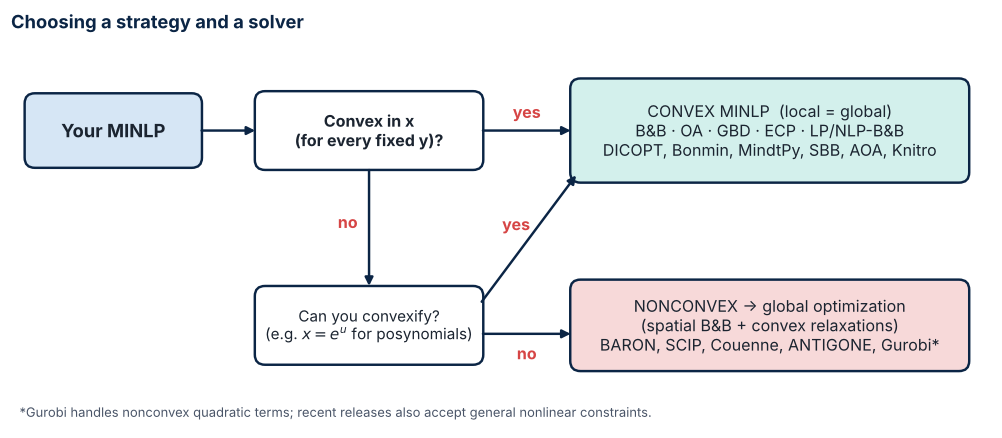

| Global solver | Core ideas | Access |
|---|---|---|
| **BARON** (Tawarmalani & Sahinidis, 2005) | branch-and-reduce: polyhedral relaxations + range reduction | commercial (GAMS, AIMMS, Pyomo, MATLAB) |
| **SCIP** | constraint-integer programming, spatial B&B | open source |
| **Couenne** (Belotti et al., 2009) | spatial B&B, reformulation, bound tightening | COIN-OR, open source |
| **ANTIGONE**, **αBB** (Floudas group) | αBB / special-structure relaxations | via GAMS / research codes |

> 🧠 **Global ≠ magic.** Global solvers need **tight variable bounds** and **good formulations**. A smaller box means tighter envelopes and an exponentially smaller tree.

##  Check Your Understanding 3 — Nonconvexity & global optimization

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Convexify: $\min Z = 3x_1^7 x_3 + 2x_2^2x_3^2 + 5/x_2 + 2y_1^{0.5} + 3y_2$ s.t. $x_1x_3 \le 4x_2^{0.3}$, $\;4x_1^2 - 2y_2^2 \le 3$, $\;x > 0$, $\;y \in \{0,1\}^2$.

<details><summary><b> Show answer</b></summary>

For binaries $y_1^{0.5} = y_1$ and $y_2^2 = y_2$. With $x_j = e^{u_j}$:
$\min Z = 3e^{7u_1 + u_3} + 2e^{2u_2 + 2u_3} + 5e^{-u_2} + 2y_1 + 3y_2$
s.t. $u_1 + u_3 \le \ln 4 + 0.3u_2$ (**linear**), $\;4e^{2u_1} - 2y_2 \le 3$ (**convex**). → a **convex MINLP**.

</details>

**Q2.** Write the McCormick envelopes of $w = xy$ for $x \in [1, 3]$, $y \in [2, 5]$. What is the largest gap between $xy$ and the underestimator?

<details><summary><b> Show answer</b></summary>

$w \ge y + 2x - 2$, $\;w \ge 3y + 5x - 15$, $\;w \le 3y + 2x - 6$, $\;w \le y + 5x - 5$.
Max gap $= \tfrac14 (3-1)(5-2) = $ **1.5**, at the center $(2, 3.5)$. Check it in the cell below.

</details>

**Q3.** In spatial B&B, a region has lower bound $l = -1.53$ and the incumbent is $UB = -1.42$. Can we prune it? And if $l = 0.115$?

<details><summary><b> Show answer</b></summary>

$l = -1.53 < UB$: **no**, it may contain a better point → bound or branch. $l = 0.115 > UB$: **yes**, prune: no point in it can beat the incumbent.

</details>

**Q4.** Why does halving the $x$-range of a bilinear term help?

<details><summary><b> Show answer</b></summary>

The McCormick gap is $\tfrac14\Delta x\,\Delta y$, so halving $\Delta x$ **halves the gap** → tighter lower bounds → more regions can be pruned.

</details>

In [ ]:
X, Y = np.meshgrid(np.linspace(1, 3, 201), np.linspace(2, 5, 201))
under = np.maximum(Y + 2*X - 2, 3*Y + 5*X - 15)
gap = X*Y - under; i = np.unravel_index(gap.argmax(), gap.shape)
print(f"max gap = {gap.max():.3f} at x = {X[i]:.2f}, y = {Y[i]:.2f}    (theory: 1.5 at (2, 3.5))")

max gap = 1.500 at x = 2.00, y = 3.50    (theory: 1.5 at (2, 3.5))


# Part D
## Fractional Objectives
### *Optimizing per functional unit: cost per gallon, emissions per kWh*

## 23 · Life-cycle optimization & functional units

**Life-cycle optimization (LCO)** = life-cycle assessment (ISO 14040/14044) + multi-objective optimization. Results are compared **per functional unit** (e.g. one gasoline-equivalent gallon, GEG):

$$\min\; \text{unit cost} = \frac{\text{total economic cost}}{\text{quantity of functional unit}}, \qquad \min\; \text{unit impact} = \frac{\text{total environmental impact}}{\text{quantity of functional unit}}$$
$$\text{s.t.}\quad A + Bx + Cy = 0 \quad(\text{mass, cash, capacity, technology choice}),\qquad x \in \mathbb{R}^n,\; y \in \{0,1\}^m$$

- Minimizing **total** cost and minimizing **cost per unit** can give **very different** designs (economies of scale!).
- The **ε-constraint** method traces the Pareto front: minimize unit cost s.t. unit impact $\le \varepsilon$, for a range of $\varepsilon$.

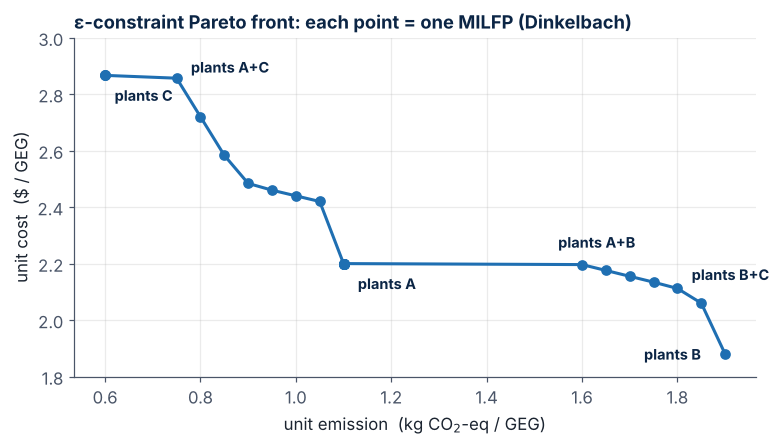

*Illustrative 3-technology biorefinery (A, B, C) with a biomass limit; every point is one mixed-integer **linear fractional** program.*

## 24 · MILFP: parametric (Dinkelbach) & reformulation–linearization

$$\min_{x,y}\; \frac{N(x,y)}{D(x,y)} = \frac{A_0 + A_1 x + A_2 y}{B_0 + B_1 x + B_2 y} \quad \text{s.t.}\quad D > 0,\;\; C_0 + C_1x + C_2y = 0,\;\; y \in \{0,1\}^m$$

**Parametric algorithm** (Dinkelbach, 1967; Zhong & You, 2014): $\;F(q) = \min_{x,y}\, N(x,y) - q\,D(x,y)\;$ (an **MILP** for fixed $q$).
- $F(q)$ is **concave, continuous, strictly decreasing** with a **unique root**: $(x^*, y^*)$ is optimal **iff** $F(q^*) = 0$.
- Newton's method on $F(q) = 0$: $\;q_{k+1} = N(x^k, y^k)/D(x^k, y^k)$ → **superlinear** convergence; still converges if each MILP is solved to any relative gap $< 100\%$.

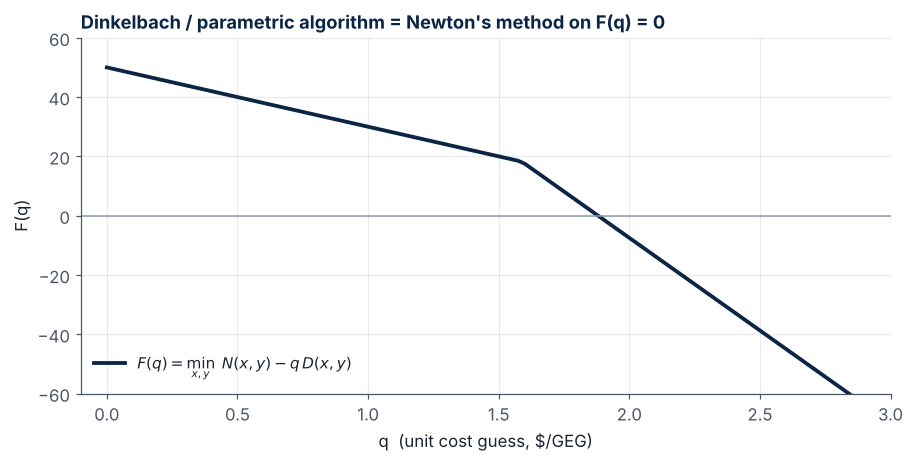

**Reformulation–linearization** (Yue, Guillén-Gosálbez & You, 2013) → **one** equivalent MILP:
1. **Charnes–Cooper (1962):** $g = 1/D$, $z = g\,x$ → objective $A_0 g + A_1 z + A_2\, g\,y$ with $B_0 g + B_1 z + B_2\, g\,y = 1$.
2. **Glover (1975):** $w = g\,y$ (continuous × binary) → $0 \le w \le M y$, $\;w \le g$, $\;w \ge g - M(1-y)$.

In [ ]:
# 🔬 Dinkelbach on a 3-technology biorefinery:  min (fixed + variable cost) / (fuel produced)   [$ / GEG]
Fix = np.array([12., 30., 8.])        # fixed cost of plants A, B, C   (M$/yr)
var = np.array([1.9, 1.4, 2.6])        # variable cost                  ($/GEG)
cap = np.array([40., 80., 30.])        # capacity                       (M GEG/yr)
bio = np.array([.012, .016, .020])     # biomass use                    (Mt per M GEG)
# z = [x_A, x_B, x_C, y_A, y_B, y_C]  (x in million GEG/yr, y = build plant?)
A = np.vstack([np.r_[np.eye(3)[i], -cap[i]*np.eye(3)[i]] for i in range(3)] +       # x_i ≤ cap_i·y_i
              [np.r_[bio, 0, 0, 0], np.r_[-1, -1, -1, 0, 0, 0]])                   # biomass ≤ 1 Mt, demand ≥ 20
b = np.r_[0, 0, 0, 1.0, -20]
Nc, Dc = np.r_[var, Fix], np.r_[1, 1, 1, 0, 0, 0]                                   # N = cost, D = production
solve = lambda c: milp(c, constraints=LinearConstraint(A, -np.inf, b), integrality=[0, 0, 0, 1, 1, 1],
                       bounds=Bounds(0, np.r_[cap, 1, 1, 1])).x
q = 0.0
for k in range(1, 10):
    z = solve(Nc - q*Dc); Fq = Nc @ z - q*(Dc @ z)
    print(f"iter {k}: q = {q:.4f}   F(q) = {Fq:9.4f}   plants = {np.round(z[3:]).astype(int)}")
    if abs(Fq) < 1e-8: break
    q = (Nc @ z)/(Dc @ z)
zt = solve(Nc)                                                                      # minimize TOTAL cost instead
for name, sol in [("min unit cost ", z), ("min total cost", zt)]:
    print(f"{name}: {(Nc @ sol)/(Dc @ sol):.3f} $/GEG,  plants (A,B,C) = {np.round(sol[3:]).astype(int)},"
          f"  output = {sol[:3].sum():.1f} M GEG/yr,  total cost = {Nc @ sol:.1f} M$/yr")

iter 1: q = 0.0000   F(q) =   50.0000   plants = [1 0 0]
iter 2: q = 2.5000   F(q) =  -38.7500   plants = [0 1 0]
iter 3: q = 1.8800   F(q) =    0.0000   plants = [0 1 0]
min unit cost : 1.880 $/GEG,  plants (A,B,C) = [0 1 0],  output = 62.5 M GEG/yr,  total cost = 117.5 M$/yr
min total cost: 2.500 $/GEG,  plants (A,B,C) = [1 0 0],  output = 20.0 M GEG/yr,  total cost = 50.0 M$/yr


##  Check Your Understanding 4 — Fractional objectives

*Try each question yourself first, then click to reveal the answer.*

**Q1.** Why did *min total cost* and *min cost per GEG* choose different plants in the cell above?

<details><summary><b> Show answer</b></summary>

Total cost is smallest when we produce the **minimum** demand with the cheapest small plant (A: 20 M GEG at \$2.50/GEG). Unit cost rewards **economies of scale**: the large plant B spreads its fixed cost over 62.5 M GEG → **\$1.88/GEG**.

</details>

**Q2.** At iteration $k$ of Dinkelbach's method, $F(q_k) < 0$. What does that tell you about $q_k$?

<details><summary><b> Show answer</b></summary>

There is a design with $N - q_k D < 0$, i.e. $N/D < q_k$: the guess $q_k$ is **too high** (not yet optimal). Because $F$ is decreasing, $F(q_k) > 0$ means $q_k < q^*$ and $F(q_k) < 0$ means $q_k > q^*$.

</details>

**Q3.** Linearize $w = g\,y$ with $0 \le g \le M$ and $y \in \{0,1\}$.

<details><summary><b> Show answer</b></summary>

$0 \le w \le M y$, $\;w \le g$, $\;w \ge g - M(1 - y)$. If $y = 0$ → $w = 0$; if $y = 1$ → $w = g$.

</details>

**Q4.** Why is it fine for the parametric algorithm to solve each MILP only *approximately*?

<details><summary><b> Show answer</b></summary>

Any feasible solution with $F < 0$ still gives a better ratio $q_{k+1} = N/D < q_k$ (an **inexact Newton** step); convergence holds as long as each MILP gap is below 100%, trading more iterations for cheaper ones.

</details>

## 25 · Summary & what's next

| Idea | Remember |
|---|---|
| MINLP | binaries choose **structure**, continuous variables choose **operation**; NP-hard |
| Logic → constraints | exactly-one, implications $y_5 \le y_3$, $F \le F^U y$, Glover for $x\,y$, small big-M |
| Bounds | **relaxation ⇒ LB**, **feasible design ⇒ UB**; stop when $UB - LB \le \varepsilon$ |
| Branch & bound | NLP relaxation per node; prune by infeasibility, bound, integrality |
| OA | NLP at $y^k$ + MILP master of **tangents**; strong bounds, few iterations |
| GBD | one **Benders cut** from KKT multipliers; small masters, weaker bounds |
| ECP | MILPs only; linearize the most violated constraint; slow but NLP-free |
| Nonconvexity | local optima + invalid cuts → **convexify** ($x = e^u$) or **relax & branch** |
| Relaxations | convex hull/envelope; secant for concave; **McCormick** for $xy$; **αBB** in general |
| Spatial B&B | branch on **continuous** variables to tighten envelopes; global within $\varepsilon$ |
| Fractional objectives | **Dinkelbach** $F(q) = \min N - qD$ (Newton) or Charnes–Cooper + Glover → one MILP |

**Next:**  **Tutorial 5** (implement B&B, OA, GBD, ECP, McCormick, spatial B&B and Dinkelbach in Python, then use Pyomo) · 📝 **Quiz 5** · 🧩 **Assignment 5**

**Further reading:** Biegler, Grossmann & Westerberg, *Systematic Methods of Chemical Process Design* (1997) · Grossmann, "Review of nonlinear mixed-integer and disjunctive programming techniques", *Optim. Eng.* 3 (2002) 227–252 · Belotti et al., "Mixed-integer nonlinear optimization", *Acta Numerica* 22 (2013) · Kronqvist et al., "A review and comparison of solvers for convex MINLP", *Optim. Eng.* 20 (2019) · Lecture material adapted and expanded from F. You, *CHEME 6800 Computational Optimization*, Cornell University.

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>

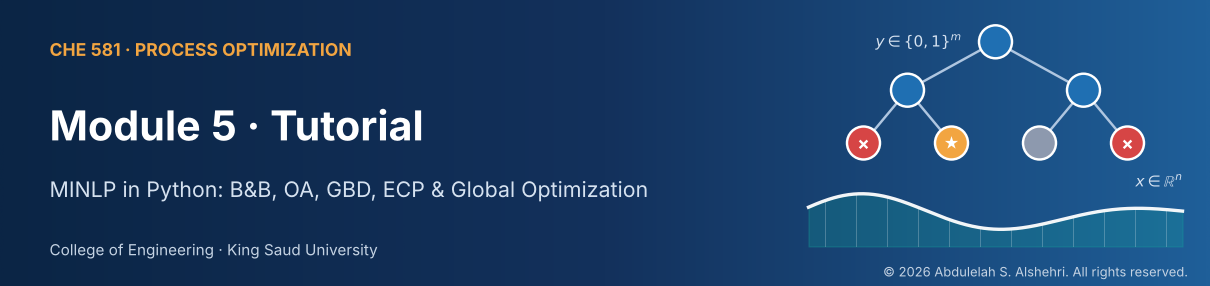

#  Tutorial 5 · Mixed-Integer Nonlinear Programming in Python

In the lecture we *watched* the algorithms. Today you **build them**. By the end of this notebook you will have written, from scratch and in plain `numpy` + `scipy`:

| Part | You will build | Key idea |
|---|---|---|
| **1** | a shortcut **column-design MINLP** (stages $N$ × reflux $R$) | integer–continuous trade-offs, relaxation & rounding |
| **2** | a small **convex-MINLP toolbox** (problem class, NLP subproblems, enumeration) | one MINLP = a family of NLPs |
| **3** | **NLP-based branch & bound** with a tree plot | relax → bound → prune |
| **4** | **Outer Approximation** with an MILP master (`scipy.optimize.milp`) | tangent cuts, integer cuts |
| **5** | **Generalized Benders Decomposition** (KKT multipliers by NNLS) | aggregated cuts, weaker bounds |
| **6** | the **Extended Cutting Plane** method | MILPs only |
| **7** | a **10-unit capacity-planning** benchmark | how the methods scale |
| **8** | the same models in **Pyomo** (MindtPy, Bonmin, Couenne) + **reactor selection** | industrial tools |
| **9** | **global optimization**: convexification, **McCormick**, **spatial B&B** (αBB and the **Haverly pooling** problem) | nonconvexity |
| **10** | **fractional objectives**: Dinkelbach & Charnes–Cooper–Glover, ε-constraint Pareto front | cost per functional unit |

**How to use it.** Run the cells **top to bottom** (`Runtime → Run all` in Colab takes about 1–2 minutes; Part 8 needs the optional install). 🧩 marks an **exercise**; try it in the empty cell, then open the hidden solution. ⚠️ marks a common pitfall, 🧠 a key insight.

## Part 0 · Setup

In [ ]:
# ⚙️ Imports and plotting style (run this first)
import numpy as np, itertools, time, warnings
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar, milp, linprog, LinearConstraint, Bounds, brentq, nnls
warnings.filterwarnings("ignore")
NAVY, BLUE, TEAL, GOLD, RED, GRAY = "#0B2545", "#1F6FB2", "#13A89E", "#F2A541", "#D64545", "#8D99AE"
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
print("✅ Setup complete.")

✅ Setup complete.


In [ ]:
# 📦 OPTIONAL — only needed for Part 8 (Pyomo + open-source MINLP solvers). Takes ~2 minutes in Colab.
INSTALL_SOLVERS = False          # ← set to True and run this cell once
if INSTALL_SOLVERS:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyomo", "highspy", "idaes-pse"], check=True)
    subprocess.run(["idaes", "get-extensions"], check=True)      # downloads ipopt, bonmin, couenne, cbc
    print("✅ Solvers installed. Continue with the next cells.")

## Part 1 · Warm-up: a column-design MINLP you can *see*

We design a binary distillation column (a benzene–toluene-like split: $\alpha = 2.5$, $z_F = 0.5$, $x_D = 0.98$, $x_B = 0.02$, $F = 100$ kmol/h). There are two decisions:

- the **number of theoretical stages $N$**: an **integer**;
- the **reflux ratio $R$**: **continuous**, but linked to $N$ by the Gilliland correlation.

$$
\min_{N \in \mathbb{Z},\,R}\;\; \text{TAC} = \underbrace{c_{tray}\,N\,\sqrt{V/100}}_{\text{column: height × diameter}} + \underbrace{c_E\,V}_{\text{steam + cooling}}
\quad\text{s.t.}\quad V = (R+1)D,\qquad \frac{N - N_{min}}{N+1} = \mathcal{G}\!\left(\frac{R - R_{min}}{R+1}\right)
$$

with Fenske's $N_{min}$, Underwood's $R_{min}$, and Molokanov's form of Gilliland's correlation $\mathcal{G}$. Given $N$, the reflux is fixed, so this MINLP has **one** integer variable and we can enumerate it, which makes it a perfect place to see *relaxation* and *rounding*.

In [ ]:
def shortcut(alpha=2.5, zF=0.5, xD=0.98, xB=0.02, F=100.0):
    """Fenske N_min, Underwood R_min (saturated-liquid feed, binary) and the distillate flow D."""
    Nmin = np.log(xD/(1 - xD) * (1 - xB)/xB) / np.log(alpha)
    Rmin = (xD/zF - alpha*(1 - xD)/(1 - zF)) / (alpha - 1)
    D = F*(zF - xB)/(xD - xB)
    return {"Nmin": Nmin, "Rmin": Rmin, "D": D}

def molokanov(X):
    """Gilliland correlation in Molokanov's form:  Y = (N − Nmin)/(N + 1)  as a function of  X = (R − Rmin)/(R + 1)."""
    return 1 - np.exp((1 + 54.4*X)/(11 + 117.2*X) * (X - 1)/np.sqrt(X))

def reflux_for_N(N, sc):
    """The (continuous) reflux ratio needed by a column with N stages: solve molokanov(X) = Y for X."""
    Y = (N - sc["Nmin"])/(N + 1)
    if Y <= 0:
        return np.inf                                   # fewer stages than N_min: impossible
    X = brentq(lambda X: molokanov(X) - Y, 1e-12, 1 - 1e-12)
    return (X + sc["Rmin"])/(1 - X)

def column_cost(N, sc, c_tray=4000.0, c_energy=2000.0):
    """Total annualized cost ($/yr) = column (∝ N·diameter, diameter ∝ √V) + energy (∝ boil-up V)."""
    R = reflux_for_N(N, sc); V = (R + 1)*sc["D"]
    capital, energy = c_tray*N*np.sqrt(V/100), c_energy*V
    return {"TAC": capital + energy, "capital": capital, "energy": energy, "R": R, "V": V}

N_min = 8.49 stages,  R_min = 1.240,  D = 50.0 kmol/h
integer optimum : N* = 23,  R* = 1.366 (= 1.10 R_min),  TAC = $336,662/yr
relaxed optimum : N  = 22.76,  TAC = $336,637/yr   ← a LOWER BOUND on the integer optimum
   rounding to N = 22:  TAC = $336,883/yr
   rounding to N = 23:  TAC = $336,662/yr


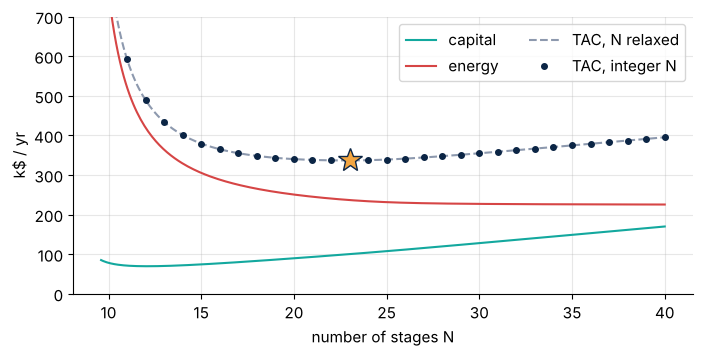

In [ ]:
# 🔍 Enumerate N, solve the continuous relaxation, and try rounding
sc = shortcut()
print(f"N_min = {sc['Nmin']:.2f} stages,  R_min = {sc['Rmin']:.3f},  D = {sc['D']:.1f} kmol/h")
Ns = np.arange(int(np.ceil(sc["Nmin"])) + 1, 41)
table = [column_cost(N, sc) for N in Ns]
k = int(np.argmin([t["TAC"] for t in table])); N_star = Ns[k]
relax = minimize_scalar(lambda N: column_cost(N, sc)["TAC"], bounds=(Ns[0] - 0.5, 40), method="bounded")
print(f"integer optimum : N* = {N_star},  R* = {table[k]['R']:.3f} (= {table[k]['R']/sc['Rmin']:.2f} R_min),  TAC = ${table[k]['TAC']:,.0f}/yr")
print(f"relaxed optimum : N  = {relax.x:.2f},  TAC = ${relax.fun:,.0f}/yr   ← a LOWER BOUND on the integer optimum")
for Nr in (int(np.floor(relax.x)), int(np.ceil(relax.x))):
    print(f"   rounding to N = {Nr}:  TAC = ${column_cost(Nr, sc)['TAC']:,.0f}/yr")

Nc = np.linspace(Ns[0] - 0.4, 40, 300); cc = [column_cost(N, sc) for N in Nc]
plt.plot(Nc, [c["capital"]/1e3 for c in cc], color=TEAL, label="capital")
plt.plot(Nc, [c["energy"]/1e3 for c in cc], color=RED, label="energy")
plt.plot(Nc, [c["TAC"]/1e3 for c in cc], "--", color=GRAY, label="TAC, N relaxed")
plt.plot(Ns, [t["TAC"]/1e3 for t in table], "o", color=NAVY, ms=4, label="TAC, integer N")
plt.plot(N_star, table[k]["TAC"]/1e3, "*", ms=18, color=GOLD, mec=NAVY)
plt.ylim(0, 700); plt.xlabel("number of stages N"); plt.ylabel("k$ / yr"); plt.legend(ncol=2); plt.show()

🧠 **What just happened?**
- Relaxing $N$ to a continuous variable gives TAC = \$336,637/yr, a **lower bound**: no integer column can be cheaper.
- Rounding the relaxed $N = 22.76$ up to 23 happens to be optimal here, because the TAC curve is flat and smooth near the optimum. ⚠️ In general, **rounding can be suboptimal or even infeasible** (think of $y_1 + y_2 = 1$ with a relaxed solution $y = (0.5, 0.5)$). That is why we need branch & bound.

Now let us see how the *discrete* decision reacts to a *continuous* parameter, the energy price:

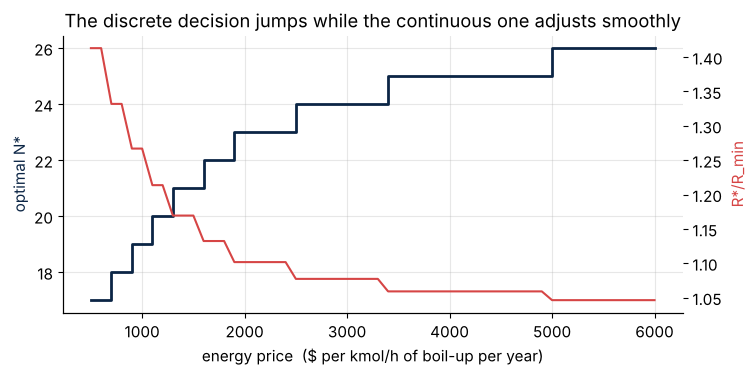

In [ ]:
prices = np.arange(500, 6001, 100)
Nopt, Rratio = [], []
for p in prices:
    costs = [column_cost(N, sc, c_energy=p)["TAC"] for N in Ns]
    Nb = Ns[int(np.argmin(costs))]; Nopt.append(Nb); Rratio.append(reflux_for_N(Nb, sc)/sc["Rmin"])
fig, ax = plt.subplots(); ax.step(prices, Nopt, where="post", color=NAVY, lw=2)
ax.set_xlabel("energy price  ($ per kmol/h of boil-up per year)"); ax.set_ylabel("optimal N*", color=NAVY)
ax2 = ax.twinx(); ax2.plot(prices, Rratio, color=RED); ax2.set_ylabel("R*/R_min", color=RED); ax2.grid(False)
plt.title("The discrete decision jumps while the continuous one adjusts smoothly"); plt.show()

### 🧩 Exercise 1 — a harder separation

Repeat the design for **$\alpha = 1.8$** (e.g. a close-boiling isomer pair). Compute $N_{min}$, $R_{min}$, the optimal $N^*$ and $R^*/R_{min}$. *Hint:* `shortcut(alpha=1.8)` and enumerate $N$ up to 80.

<details><summary><b>👉 Show solution</b></summary>

```python
sc2 = shortcut(alpha=1.8)
Ns2 = np.arange(int(np.ceil(sc2["Nmin"])) + 1, 81)
costs = [column_cost(N, sc2)["TAC"] for N in Ns2]; N2 = Ns2[int(np.argmin(costs))]
print(sc2, N2, reflux_for_N(N2, sc2) / sc2["Rmin"], min(costs))
```
$N_{min} = 13.24$, $R_{min} = 2.36$, $N^* = 33$, $R^* = 2.63 = 1.11\,R_{min}$, TAC ≈ \$540,500/yr. A harder split needs **more stages and more reflux**, and costs ~60% more.

</details>

In [ ]:
# ✍️ Your answer to Exercise 1

## Part 2 · A small convex-MINLP toolbox

All algorithms in Parts 3–7 work on the **standard convex form** used by Duran & Grossmann (1986):

$$\min_{x,\,y}\; c^\top y + f(x) \quad\text{s.t.}\quad g(x) + B\,y \le 0,\qquad A\,y \le a,\qquad x^L \le x \le x^U,\qquad y \in \{0,1\}^m$$

- $f$ and every $g_j$ are **convex** in $x$, and $y$ enters **linearly** (through $c$ and $B$).
- **Every** constraint that contains $x$ goes into $g(x) + By \le 0$, including the linear ones (e.g. $x_1 - 2y_1 \ge 0$ becomes $g = -x_1$ with $B = [2, 0, 0]$).
- Constraints on $y$ only go into $Ay \le a$.

We store a problem in a small `dataclass`:

In [ ]:
from dataclasses import dataclass, field
from typing import Callable
import itertools, time
import numpy as np
from scipy.optimize import minimize, milp, LinearConstraint, Bounds, nnls


@dataclass
class ConvexMINLP:
    """min c^T y + f(x)   s.t.   g(x) + B y <= 0,   A y <= a,   xL <= x <= xU,   y in {0,1}^m"""
    name: str
    c: np.ndarray                 # (m,)   cost of the binaries
    f: Callable                   # f(x)        convex objective in x
    grad_f: Callable              # ∇f(x)
    g: Callable                   # g(x) -> (p,) every constraint that involves x
    jac_g: Callable               # ∂g/∂x -> (p, n)
    B: np.ndarray                 # (p, m) how y enters each constraint
    xL: np.ndarray
    xU: np.ndarray
    A: np.ndarray = None          # (q, m) pure-integer constraints  A y <= a
    a: np.ndarray = None
    x0: np.ndarray = None         # starting point for the NLPs

    def __post_init__(self):
        self.c, self.B = np.asarray(self.c, float), np.asarray(self.B, float)
        self.xL, self.xU = np.asarray(self.xL, float), np.asarray(self.xU, float)
        self.n, self.m = len(self.xL), len(self.c)
        self.A = np.zeros((0, self.m)) if self.A is None else np.asarray(self.A, float)
        self.a = np.zeros(0) if self.a is None else np.asarray(self.a, float)
        self.x0 = 0.5 * (self.xL + self.xU) if self.x0 is None else np.asarray(self.x0, float)

    def objective(self, x, y):
        return float(self.c @ y + self.f(x))

    def max_violation(self, x, y):
        v = np.max(self.g(x) + self.B @ y, initial=0.0)
        if len(self.a):
            v = max(v, np.max(self.A @ y - self.a, initial=0.0))
        return max(v, 0.0)

### Three test problems from the lecture

| Problem | Binaries | Known optimum |
|---|---|---|
| `duran_grossmann()` | 3 | $Z^* = 3.5$ at $y = (0,1,0)$, $x = (1,1)$ |
| `oa_example_1()` (lecture slide 12) | 2 | $Z^* = 6$ at $y = (1,0)$, $x = (2,1)$ |
| `oa_example_2()` (lecture Check 2, Q5) | 2 | $Z^* = 0$ (two alternative optima) |

In [ ]:
def duran_grossmann():
    """min y1 + 1.5y2 + 0.5y3 + x1² + x2²  (Duran & Grossmann, 1986).  Optimum Z* = 3.5 at y = (0,1,0), x = (1,1)."""
    g = lambda x: np.array([(x[0] - 2)**2 - x[1],    #  (x1−2)² − x2 ≤ 0
                            -x[0],                   #  x1 − 2y1 ≥ 0          →  −x1 + 2y1 ≤ 0
                            x[0] - x[1] - 4,         #  x1 − x2 − 4(1−y2) ≤ 0 →  x1 − x2 − 4 + 4y2 ≤ 0
                            -x[0] + 1,               #  x1 − (1−y1) ≥ 0       →  −x1 + 1 − y1 ≤ 0
                            -x[1],                   #  x2 − y2 ≥ 0           →  −x2 + y2 ≤ 0
                            -x[0] - x[1]])           #  x1 + x2 ≥ 3y3         →  −x1 − x2 + 3y3 ≤ 0
    J = lambda x: np.array([[2*(x[0] - 2), -1], [-1, 0], [1, -1], [-1, 0], [0, -1], [-1, -1]], float)
    B = [[0, 0, 0], [2, 0, 0], [0, 4, 0], [-1, 0, 0], [0, 1, 0], [0, 0, 3]]
    return ConvexMINLP("Duran–Grossmann (3 binaries)", c=[1, 1.5, 0.5],
                       f=lambda x: x[0]**2 + x[1]**2, grad_f=lambda x: 2*np.asarray(x),
                       g=g, jac_g=J, B=B, xL=[0, 0], xU=[4, 4], A=[[-1, -1, -1]], a=[-1], x0=[1.5, 1.5])


def oa_example_1():
    """Lecture slide 12: min y1 + y2 + x1² + x2². Optimum 6 at y = (1,0), x = (2,1)."""
    g = lambda x: np.array([(x[0] - 2)**2 - x[1], -x[0], -x[0] + x[1] + 3, -x[0] + 1, -x[1], -x[0] - x[1]])
    J = lambda x: np.array([[2*(x[0] - 2), -1], [-1, 0], [-1, 1], [-1, 0], [0, -1], [-1, -1]], float)
    B = [[0, 0], [2, 0], [-3, 0], [-1, 0], [0, 1], [3, 0]]
    return ConvexMINLP("OA example 1", c=[1, 1], f=lambda x: x[0]**2 + x[1]**2, grad_f=lambda x: 2*np.asarray(x),
                       g=g, jac_g=J, B=B, xL=[0, 0], xU=[4, 4], A=[[-1, -1]], a=[-1], x0=[2, 1])


def oa_example_2():
    """Lecture Check 2, Q5: min y1 − y2 + x1² + (x2−3)². Optimum 0 (two alternative optima)."""
    g = lambda x: np.array([2*(x[0] - 1)**2 + (x[1] - 2)**2 - 3, -x[0] - x[1], -x[0]])
    J = lambda x: np.array([[4*(x[0] - 1), 2*(x[1] - 2)], [-1, -1], [-1, 0]], float)
    B = [[0, -3], [3, 0], [2, 1]]
    return ConvexMINLP("OA example 2", c=[1, -1], f=lambda x: x[0]**2 + (x[1] - 3)**2,
                       grad_f=lambda x: np.array([2*x[0], 2*(x[1] - 3)]), g=g, jac_g=J, B=B,
                       xL=[0, 0], xU=[10, 10], x0=[1, 2])

### The NLP subproblems

- **NLP-U** (`solve_nlp_fixed_y`): fix $y = y^k$ and minimize over $x$ → an **upper bound** if feasible.
- **NLP-F** (`solve_feasibility_nlp`): $\min u$ s.t. $g(x) + By^k \le u$. If $u^* > 0$, the binary point $y^k$ is **infeasible**.

⚠️ **A lesson learned the hard way.** A local NLP solver can *fail* on a perfectly feasible problem (SLSQP, for instance, reports "inequality constraints incompatible" in some degenerate cases). If we then call the problem "infeasible", branch & bound would prune good nodes and return a **wrong** answer. So `robust_convex_nlp` (i) tries several starts, (ii) accepts only *successful* and *feasible* solves, and (iii) certifies infeasibility with a convex phase-1 problem before giving up.

In [ ]:
def _slsqp(fun, jac, cons, bounds, starts, feas):
    """Solve a convex NLP with SLSQP from several starts; keep the best *successful* and *feasible* answer."""
    best = None
    for z0 in starts:
        r = minimize(fun, z0, jac=jac, constraints=cons, bounds=bounds, method="SLSQP",
                     options={"ftol": 1e-12, "maxiter": 1000})
        if r.success and feas(r.x) and (best is None or r.fun < best.fun - 1e-12):
            best = r
    return best


def _min_violation(viol, bounds, z0):
    """Phase-1 problem  min u  s.t.  viol(z) <= u.   Returns (z, u*);  u* > 0  ⇔  infeasible."""
    r = minimize(lambda z: z[-1], np.r_[z0, np.max(viol(z0)) + 1.0], jac=lambda z: np.r_[np.zeros(len(z0)), 1.0],
                 constraints=[{"type": "ineq", "fun": lambda z: z[-1] - viol(z[:-1])}],
                 bounds=list(bounds) + [(None, None)], method="SLSQP", options={"ftol": 1e-12, "maxiter": 1000})
    return r.x[:-1], r.x[-1]


def robust_convex_nlp(fun, jac, cons, bounds, starts, viol, tol=1e-6):
    """SLSQP multistart → if that fails, a phase-1 feasibility check → re-solve from the feasible point
    (with trust-constr as the last resort).  Returns None only if the problem is really infeasible."""
    feas = lambda z: np.max(viol(z)) <= tol
    r = _slsqp(fun, jac, cons, bounds, starts, feas)
    if r is not None:
        return r
    z_feas, u = _min_violation(viol, bounds, starts[0])
    if u > tol:
        return None                                   # certified infeasible (convex phase-1 problem)
    r = _slsqp(fun, jac, cons, bounds, [z_feas], feas)
    if r is None:
        r = minimize(fun, z_feas, jac=jac, constraints=cons, bounds=bounds, method="trust-constr")
    return r


def solve_nlp_fixed_y(P, y):
    """NLP-U:  fix y, optimize x.  Returns dict(feasible, x, obj)."""
    y = np.asarray(y, float)
    viol = lambda x: P.g(x) + P.B @ y
    cons = [{"type": "ineq", "fun": lambda x: -viol(x), "jac": lambda x: -P.jac_g(x)}]
    starts = [P.x0, P.xL + 0.3*(P.xU - P.xL), P.xU]
    r = robust_convex_nlp(P.f, P.grad_f, cons, list(zip(P.xL, P.xU)), starts, viol)
    if r is None:
        return {"feasible": False, "x": None, "obj": np.inf}
    return {"feasible": True, "x": r.x, "obj": P.objective(r.x, y)}


def solve_feasibility_nlp(P, y):
    """NLP-F:  min u  s.t.  g(x) + B y <= u.   u* > 0  ⇒  this y is infeasible."""
    y = np.asarray(y, float)
    return _min_violation(lambda x: P.g(x) + P.B @ y, list(zip(P.xL, P.xU)), P.x0)

### Brute force first: one NLP per binary combination

Always the right *first* step on a small problem: it gives the answer that every smarter algorithm must reproduce.

In [ ]:
def enumerate_all(P, verbose=True):
    """Brute force: one NLP for every y that satisfies A y <= a."""
    rows = []
    for yy in itertools.product([0, 1], repeat=P.m):
        y = np.array(yy, float)
        if len(P.a) and np.any(P.A @ y > P.a + 1e-9):
            continue
        s = solve_nlp_fixed_y(P, y)
        rows.append((yy, s["obj"], s["x"]))
        if verbose:
            print(f"y = {yy}:  " + (f"Z = {s['obj']:8.4f}   x = {np.round(s['x'], 3)}" if s["feasible"] else "NLP infeasible"))
    best = min(rows, key=lambda r: r[1])
    return best, rows

P = duran_grossmann()
best, rows = enumerate_all(P)
print(f"\n🏆 best: y = {best[0]},  Z = {best[1]:.4f}   ({len(rows)} NLPs)")

y = (0, 0, 1):  Z =   5.0000   x = [1.5 1.5]
y = (0, 1, 0):  Z =   3.5000   x = [1. 1.]
y = (0, 1, 1):  Z =   6.5000   x = [1.5 1.5]
y = (1, 0, 0):  Z =   5.0000   x = [2. 0.]
y = (1, 0, 1):  Z =   6.5000   x = [2. 1.]
y = (1, 1, 0):  Z =  10.5000   x = [2. 2.]
y = (1, 1, 1):  Z =  11.0000   x = [2. 2.]

🏆 best: y = (0, 1, 0),  Z = 3.5000   (7 NLPs)


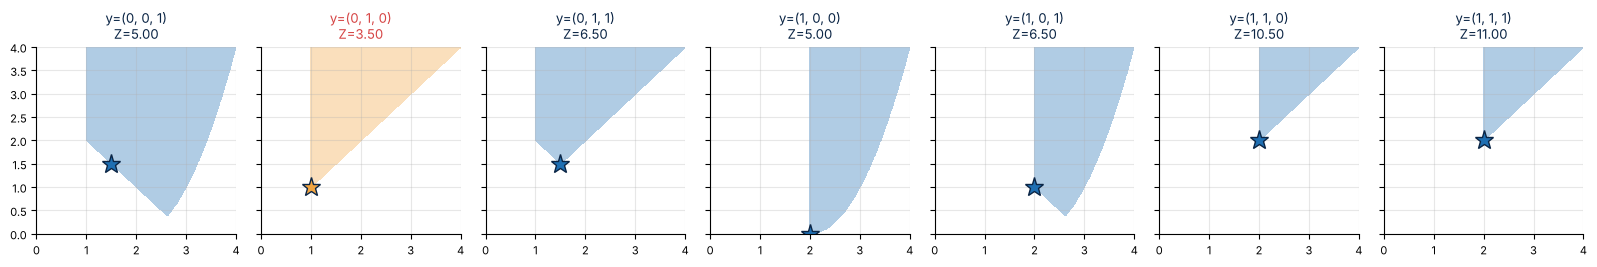

In [ ]:
# 🎨 The feasible x-region changes with y: one NLP per panel
def plot_family(P, best=None):
    """Feasible x-region and NLP optimum for every y (2 continuous variables only)."""
    X1, X2 = np.meshgrid(np.linspace(P.xL[0], P.xU[0], 200), np.linspace(P.xL[1], P.xU[1], 200))
    combos = [yy for yy in itertools.product([0, 1], repeat=P.m)
              if not len(P.a) or np.all(P.A @ np.array(yy) <= P.a + 1e-9)]
    fig, axs = plt.subplots(1, len(combos), figsize=(2.3*len(combos), 2.8), sharey=True)
    for ax, yy in zip(np.atleast_1d(axs), combos):
        y = np.array(yy, float)
        G = np.array([np.max(P.g(np.array([a, b])) + P.B @ y) for a, b in zip(X1.ravel(), X2.ravel())]).reshape(X1.shape)
        ax.contourf(X1, X2, (G <= 0).astype(float), levels=[0.5, 1.5], colors=[GOLD if yy == best else BLUE], alpha=0.35)
        s = solve_nlp_fixed_y(P, y)
        if s["feasible"]:
            ax.plot(*s["x"], "*", ms=14, color=GOLD if yy == best else BLUE, mec=NAVY)
        ax.set_title(f"y={yy}\nZ={s['obj']:.2f}", fontsize=9.5, color=RED if yy == best else NAVY)
        ax.set_xlim(P.xL[0], P.xU[0]); ax.set_ylim(P.xL[1], P.xU[1]); ax.tick_params(labelsize=8)
    plt.tight_layout(); plt.show()

plot_family(P, best=best[0])

## Part 3 · NLP-based branch & bound

At every node we solve the **NLP relaxation**: binaries already branched on are **fixed**, the others are relaxed to $0 \le y_j \le 1$. Because the problem is convex, the relaxation value is a valid **lower bound** for every integer solution below that node.

**Implementation detail.** Fixed binaries are *substituted out* of the NLP instead of being given equal lower and upper bounds (this is more robust and makes the NLP smaller).

In [ ]:
def nlp_relaxation(P, yL, yU):
    """Continuous relaxation over (x, y_free): y_j fixed where yL_j = yU_j, 0 <= y_j <= 1 elsewhere.
    Fixed binaries are substituted out (SLSQP misbehaves when a variable's lower and upper bounds coincide)."""
    yL, yU = np.asarray(yL, float), np.asarray(yU, float)
    free = np.where(yU > yL)[0]; n, k = P.n, len(free)
    def ys(z):
        y = yL.copy(); y[free] = z[n:]; return y
    def viol(z):
        v = P.g(z[:n]) + P.B @ ys(z)
        return np.r_[v, P.A @ ys(z) - P.a] if len(P.a) else v
    fun = lambda z: P.c @ ys(z) + P.f(z[:n])
    jac = lambda z: np.r_[P.grad_f(z[:n]), P.c[free]]
    def jac_v(z):
        Jv = np.c_[P.jac_g(z[:n]), P.B[:, free]]
        return np.vstack([Jv, np.c_[np.zeros((len(P.a), n)), P.A[:, free]]]) if len(P.a) else Jv
    cons = [{"type": "ineq", "fun": lambda z: -viol(z), "jac": lambda z: -jac_v(z)}]
    bounds = list(zip(P.xL, P.xU)) + [(0, 1)]*k
    starts = [np.r_[P.x0, np.full(k, 0.5)], np.r_[P.xU, np.ones(k)], np.r_[0.5*(P.xL + P.xU), np.ones(k)]]
    r = robust_convex_nlp(fun, jac, cons, bounds, starts, viol)
    if r is None:
        return None
    return {"x": r.x[:n], "y": ys(r.x), "obj": float(r.fun)}

root = nlp_relaxation(P, np.zeros(3), np.ones(3))
print(f"root relaxation: z = {root['obj']:.4f},  y = {np.round(root['y'], 3)},  x = {np.round(root['x'], 3)}")

root relaxation: z = 2.5323,  y = [0.377 0.    0.623],  x = [1.154 0.716]


The **algorithm**: pick an open node → solve its relaxation → **prune** if infeasible, or if $z \ge UB$ (bound), or **update the incumbent** if $y$ is integer → otherwise **branch** on the most fractional $y_j$.

- `rule="depth"`: depth-first (a stack): finds integer solutions quickly, uses little memory.
- `rule="best"`: best-first (lowest parent bound): tends to solve fewer nodes, needs more memory.

In [ ]:
def branch_and_bound(P, rule="depth", verbose=True, int_tol=1e-5):
    """NLP-based branch & bound.  rule = 'depth' (stack) or 'best' (lowest parent bound first)."""
    UB, best, n_nlp = np.inf, None, 0
    open_nodes = [dict(id=0, parent=None, yL=np.zeros(P.m), yU=np.ones(P.m), depth=0, label="root", pbound=-np.inf)]
    tree, next_id = [], 1
    while open_nodes:
        if rule == "depth":
            node = open_nodes.pop()
        else:
            k = int(np.argmin([nd["pbound"] for nd in open_nodes])); node = open_nodes.pop(k)
        if node["pbound"] >= UB - 1e-9:                      # parent bound already too weak: skip without solving
            tree.append({**node, "status": "bound", "obj": node["pbound"], "order": None}); continue
        rel = nlp_relaxation(P, node["yL"], node["yU"]); n_nlp += 1
        rec = {**node, "order": n_nlp}
        if rel is None:
            rec.update(status="infeasible", obj=np.inf)
        elif rel["obj"] >= UB - 1e-9:
            rec.update(status="bound", obj=rel["obj"])
        else:
            frac = np.abs(rel["y"] - np.round(rel["y"]))
            rec.update(obj=rel["obj"], y=rel["y"])
            if frac.max() <= int_tol:
                rec["status"] = "integer"; UB, best = rel["obj"], (rel["x"], np.round(rel["y"]))
            else:
                j = int(np.argmax(frac)); rec.update(status="branch", var=j)
                for val in (1, 0):                         # push y_j = 1 first so that y_j = 0 is explored first
                    yL, yU = node["yL"].copy(), node["yU"].copy(); yL[j] = yU[j] = val
                    open_nodes.append(dict(id=next_id, parent=node["id"], yL=yL, yU=yU, depth=node["depth"] + 1,
                                           label=f"y{j+1}={val}", pbound=rel["obj"])); next_id += 1
        tree.append(rec)
        if verbose:
            msg = {"infeasible": "infeasible → prune", "bound": f"z ≥ UB → prune",
                   "integer": f"integer → new UB = {UB:.4f}", "branch": f"branch on y{rec.get('var', 0)+1}"}[rec["status"]]
            zs = "   inf" if not np.isfinite(rec["obj"]) else f"{rec['obj']:8.4f}"
            print(f"NLP {n_nlp:3d} | node {node['id']:3d} {node['label']:>7s} (depth {node['depth']}) | z = {zs} | {msg}")
    return {"x": best[0], "y": best[1], "obj": UB, "tree": tree, "n_nlp": n_nlp}

In [ ]:
bb = branch_and_bound(P, rule="depth")
print(f"\n🏆 Z* = {bb['obj']:.4f} at y = {bb['y'].astype(int)} using {bb['n_nlp']} NLPs")

NLP   1 | node   0    root (depth 0) | z =   2.5323 | branch on y3
NLP   2 | node   2    y3=0 (depth 1) | z =   3.0491 | branch on y1
NLP   3 | node   4    y1=0 (depth 2) | z =   3.5000 | integer → new UB = 3.5000
NLP   4 | node   3    y1=1 (depth 2) | z =   5.0000 | z ≥ UB → prune
NLP   5 | node   1    y3=1 (depth 1) | z =   5.0000 | z ≥ UB → prune

🏆 Z* = 3.5000 at y = [0 1 0] using 5 NLPs


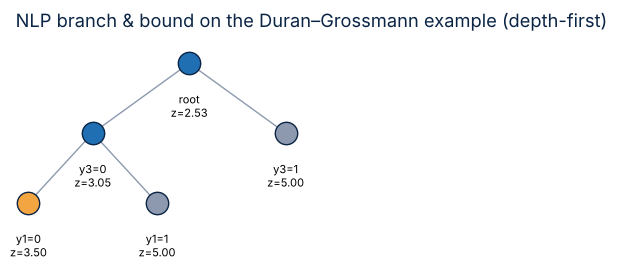

In [ ]:
# 🎨 Draw the tree
def draw_tree(tree, annotate=True, title="Branch & bound tree"):
    """Draw a B&B tree: blue = branched, gold = integer (incumbent), gray = pruned by bound, red = infeasible."""
    kids = {}
    for nd in tree:
        kids.setdefault(nd["parent"], []).append(nd)
    pos, leaf = {}, [0]
    def place(nd):
        ch = sorted(kids.get(nd["id"], []), key=lambda c: c["label"])
        if not ch:
            pos[nd["id"]] = (leaf[0], -nd["depth"]); leaf[0] += 1
        else:
            for c in ch: place(c)
            pos[nd["id"]] = (np.mean([pos[c["id"]][0] for c in ch]), -nd["depth"])
    place(kids[None][0])
    col = {"branch": BLUE, "integer": GOLD, "bound": GRAY, "infeasible": RED}
    fig, ax = plt.subplots(figsize=(min(14, 2 + 0.55*leaf[0]), 1.1 + 0.9*max(-p[1] for p in pos.values())))
    for nd in tree:
        if nd["parent"] is not None:
            ax.plot(*zip(pos[nd["parent"]], pos[nd["id"]]), color=GRAY, lw=1, zorder=1)
    for nd in tree:
        x, y = pos[nd["id"]]
        ax.scatter(x, y, s=260 if annotate else 60, color=col[nd["status"]], edgecolors=NAVY, zorder=2)
        if annotate:
            z = "inf" if not np.isfinite(nd["obj"]) else f"{nd['obj']:.2f}"
            ax.annotate(f"{nd['label']}\nz={z}", (x, y), (x, y - 0.42), ha="center", va="top", fontsize=8)
    ax.set_axis_off(); ax.set_title(title, loc="left", color=NAVY)
    ax.set_ylim(min(p[1] for p in pos.values()) - 0.8, 0.4); plt.show()

draw_tree(bb["tree"], title="NLP branch & bound on the Duran–Grossmann example (depth-first)")

### 🧩 Exercise 3 — node selection

Run `branch_and_bound(P, rule="best")` on the same problem. Does best-first need fewer NLPs here? Why might it matter more on bigger problems (Part 7)?

<details><summary><b>👉 Show solution</b></summary>

```python
for rule in ["depth", "best"]:
    print(rule, branch_and_bound(P, rule=rule, verbose=False)["n_nlp"])
```
Both need **5 NLPs** on this tiny tree. On the 10-unit problem in Part 7, best-first solves noticeably fewer NLPs than depth-first because it always expands the most promising bound, so more nodes are pruned before being solved.

</details>

In [ ]:
# ✍️ Your answer to Exercise 3

## Part 4 · Outer Approximation (Duran & Grossmann, 1986)

OA alternates two problems:

1. **NLP-U at $y^k$** → $x^k$ and an **upper bound**.
2. **MILP master**: every convex function is replaced by its tangent planes at all visited points:
$$\alpha \ge c^\top y + f(x^k) + \nabla f(x^k)^\top (x - x^k), \qquad g(x^k) + \nabla g(x^k)\,(x - x^k) + By \le 0$$
plus an **integer cut** removing $y^k$. Its optimum $\alpha$ is a **lower bound**, and its $y$ is the next guess.

**Coding trick.** Every cut is stored as a pair `(row, rhs)` meaning `row · z <= rhs` with $z = [x,\; y,\; \alpha]$. The master is then a single call to `scipy.optimize.milp` (HiGHS).

In [ ]:
def oa_cuts(P, xk):
    """Linearizations at xk as rows over z = [x, y, alpha]  (every row means  row·z <= rhs)."""
    fk, gfk = P.f(xk), P.grad_f(xk)
    obj_cut = (np.r_[gfk, P.c, -1.0], gfk @ xk - fk)     # alpha >= c'y + f(xk) + ∇f(xk)'(x − xk)
    gk, Jk = P.g(xk), P.jac_g(xk)
    con_cuts = [(np.r_[Jk[j], P.B[j], 0.0], Jk[j] @ xk - gk[j]) for j in range(len(gk))]   # g(xk)+∇g(xk)(x−xk)+By <= 0
    return obj_cut, con_cuts


def integer_cut(yk):
    """sum_{j in B} y_j − sum_{j in N} y_j <= |B| − 1  (removes exactly the point yk)."""
    yk = np.round(yk).astype(int)
    return np.where(yk == 1, 1.0, -1.0), float(yk.sum() - 1)


def solve_master(P, cuts, int_cuts, with_x=True):
    """MILP master:  min alpha  s.t. all cuts.  Variables z = [x (if with_x), y, alpha]."""
    nx = P.n if with_x else 0
    nv = nx + P.m + 1
    rows, rhs = [r for r, _ in cuts], [b for _, b in cuts]
    for ry, b in int_cuts + list(zip(P.A, P.a)):           # integer cuts and A y <= a act on the y-block only
        z = np.zeros(nv); z[nx:nx + P.m] = ry; rows.append(z); rhs.append(b)
    cost = np.zeros(nv); cost[-1] = 1.0
    lb = np.r_[P.xL if with_x else [], np.zeros(P.m), -1e7]
    ub = np.r_[P.xU if with_x else [], np.ones(P.m), 1e7]
    res = milp(cost, constraints=[LinearConstraint(np.array(rows), -np.inf, np.array(rhs))],
               integrality=np.r_[np.zeros(nx), np.ones(P.m), 0], bounds=Bounds(lb, ub))
    if res.status != 0:                                     # master infeasible: every y has been excluded
        return None
    z = res.x
    return {"x": z[:nx] if with_x else None, "y": np.round(z[nx:nx + P.m]) + 0.0, "alpha": z[-1]}   # +0.0 turns −0 into 0


def outer_approximation(P, y0, max_iter=50, eps=1e-6, verbose=True):
    UB, best, hist = np.inf, None, []
    obj_cuts, con_cuts, int_cuts = [], [], []
    y, n_nlp, n_milp = np.asarray(y0, float), 0, 0
    for k in range(1, max_iter + 1):
        sub = solve_nlp_fixed_y(P, y); n_nlp += 1                # 1) NLP subproblem at y^k
        if sub["feasible"]:
            xk = sub["x"]
            if sub["obj"] < UB:
                UB, best = sub["obj"], (xk, y.copy())
        else:
            xk, _ = solve_feasibility_nlp(P, y); n_nlp += 1      #    infeasible → linearize at the NLP-F point
        o, cc = oa_cuts(P, xk)                                   # 2) add OA cuts (+ integer cut)
        if sub["feasible"]:
            obj_cuts.append(o)
        con_cuts += cc
        int_cuts.append(integer_cut(y))
        ms = solve_master(P, obj_cuts + con_cuts, int_cuts); n_milp += 1   # 3) MILP master → LB, next y
        LB = np.inf if ms is None else ms["alpha"]
        LB_show = LB if LB > -1e6 else -np.inf                   # alpha unbounded before the first objective cut
        hist.append(dict(k=k, y=y.copy(), NLP=sub["obj"], UB=UB, LB=min(LB_show, UB)))
        if verbose:
            nxt = "" if ms is None else f"  → next y = {ms['y'].astype(int)}"
            print(f"iter {k:2d}: y = {y.astype(int)}  NLP = {sub['obj'] + 1e-12:9.4f}  UB = {UB + 1e-12:9.4f}  master LB = {LB_show:9.4f}{nxt}")
        if ms is None or LB >= UB - eps:                         # 4) bounds meet → stop
            break
        y = ms["y"]
    return {"x": best[0], "y": best[1], "obj": UB, "hist": hist, "n_nlp": n_nlp, "n_milp": n_milp}

### ✅ Check against the lecture (OA example 1, slide 12)

Expected: **iteration 1**: NLP at $y = (1,1)$ → UB = 7, master → LB = 6, next $y = (1,0)$; **iteration 2**: NLP → UB = 6 = LB → stop.

In [ ]:
oa1 = outer_approximation(oa_example_1(), y0=[1, 1])
print(f"\n🏆 Z* = {oa1['obj']:.4f} at y = {oa1['y'].astype(int)}, x = {np.round(oa1['x'], 3)}")

iter  1: y = [1 1]  NLP =    7.0000  UB =    7.0000  master LB =    6.0000  → next y = [1 0]
iter  2: y = [1 0]  NLP =    6.0000  UB =    6.0000  master LB =   14.0000  → next y = [0 1]

🏆 Z* = 6.0000 at y = [1 0], x = [2. 1.]


**Infeasible starting points.** For `oa_example_2` the guess $y = (1,1)$ is infeasible. OA then solves **NLP-F**, linearizes at its solution (no objective cut yet, so the first master is unbounded below: LB $= -\infty$) and moves on. Compare with the start $y = (0,0)$ used in the original slides:

In [ ]:
for y0 in ([0, 0], [1, 1]):
    print(f"--- start y0 = {y0}")
    r = outer_approximation(oa_example_2(), y0=y0)
    print(f"🏆 Z* = {r['obj'] + 1e-12:.4f} at y = {r['y'].astype(int)}, x = {np.round(r['x'], 3)}   ({r['n_nlp']} NLPs, {r['n_milp']} MILPs)\n")

--- start y0 = [0, 0]
iter  1: y = [0 0]  NLP =    0.0000  UB =    0.0000  master LB =   -1.0000  → next y = [0 1]
iter  2: y = [0 1]  NLP =    0.0000  UB =    0.0000  master LB =    4.0000  → next y = [1 0]
🏆 Z* = 0.0000 at y = [0 1], x = [1. 3.]   (2 NLPs, 2 MILPs)

--- start y0 = [1, 1]


iter  1: y = [1 1]  NLP =       inf  UB =       inf  master LB =      -inf  → next y = [0 0]
iter  2: y = [0 0]  NLP =    0.0000  UB =    0.0000  master LB =   -1.0000  → next y = [0 1]
iter  3: y = [0 1]  NLP =    0.0000  UB =    0.0000  master LB =    4.0000  → next y = [1 0]
🏆 Z* = 0.0000 at y = [0 1], x = [1. 3.]   (4 NLPs, 3 MILPs)



iter  1: y = [1 1 1]  NLP =   11.0000  UB =   11.0000  master LB =    1.0000  → next y = [1 0 0]
iter  2: y = [1 0 0]  NLP =    5.0000  UB =    5.0000  master LB =    1.5000  → next y = [0 1 0]
iter  3: y = [0 1 0]  NLP =    3.5000  UB =    3.5000  master LB =    4.5000  → next y = [0 0 1]


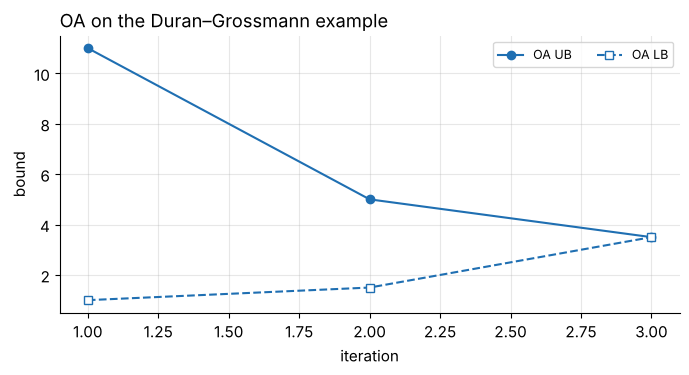

In [ ]:
# The 3-binary example, and a plot of the bounds
def plot_bounds(results, title="Upper and lower bounds"):
    fig, ax = plt.subplots()
    for (name, res), c in zip(results.items(), [BLUE, RED, TEAL, GOLD]):
        k = [h["k"] for h in res["hist"]]
        if "UB" in res["hist"][0]:
            ax.plot(k, [h["UB"] for h in res["hist"]], "-o", color=c, label=f"{name} UB")
        ax.plot(k, [h["LB"] for h in res["hist"]], "--s", mfc="white", color=c, label=f"{name} LB")
    ax.set_xlabel("iteration"); ax.set_ylabel("bound"); ax.legend(ncol=2, fontsize=9); ax.set_title(title, loc="left")
    plt.show()

oa = outer_approximation(P, y0=[1, 1, 1])
plot_bounds({"OA": oa}, title="OA on the Duran–Grossmann example")

### 🧩 Exercise 4 — does the starting point matter?

Run OA on `duran_grossmann()` from **all 7 feasible** starting points $y^0$. How many iterations does each need? Is the final answer always $Z^* = 3.5$?

<details><summary><b>👉 Show solution</b></summary>

```python
for y0 in itertools.product([0, 1], repeat=3):
    if sum(y0) == 0: continue
    r = outer_approximation(P, np.array(y0, float), verbose=False)
    print(y0, len(r["hist"]), "iterations,  Z* =", round(r["obj"], 4))
```
Every start reaches **$Z^* = 3.5$** (global, because the problem is convex). Starting at $(0,1,0)$ or $(1,0,1)$ needs **2** iterations; all other starts need **3**.

</details>

In [ ]:
# ✍️ Your answer to Exercise 4

## Part 5 · Generalized Benders Decomposition (Geoffrion, 1972)

GBD keeps **one** cut per iteration and only the $y$ variables in the master:

$$\text{optimality cut:}\;\; \alpha \ge c^\top y + f(x^k) + (\mu^k)^\top\big[g(x^k) + By\big], \qquad \text{feasibility cut:}\;\; (\lambda^k)^\top\big[g(x^k) + By\big] \le 0$$

We need the **KKT multipliers** $\mu^k \ge 0$. SLSQP does not return them, so we **recover** them from stationarity at the solution: only active constraints (and active bounds) can have $\mu_j > 0$, and

$$\nabla f(x^k) + \sum_{j\,\in\,\text{active}} \mu_j \nabla g_j(x^k) - \lambda^L + \lambda^U = 0, \qquad \mu, \lambda \ge 0$$

is a small **non-negative least-squares** problem (`scipy.optimize.nnls`).

In [ ]:
def kkt_multipliers(P, x, y, feasibility=False):
    """Recover μ >= 0 for g(x)+By <= 0 at an NLP solution from stationarity, by non-negative least squares:
         ∇f(x) + Σ_j μ_j ∇g_j(x) − λ_L + λ_U = 0    (active constraints / active bounds only)
       For NLP-F the conditions are  Σ_j λ_j ∇g_j = 0  and  Σ_j λ_j = 1."""
    gv = P.g(x) + P.B @ y
    act = np.where(gv >= gv.max() - 1e-5)[0] if feasibility else np.where(gv >= -1e-5)[0]
    lo, hi = np.where(x <= P.xL + 1e-7)[0], np.where(x >= P.xU - 1e-7)[0]
    J, I = P.jac_g(x), np.eye(P.n)
    M = np.array([J[j] for j in act] + [-I[i] for i in lo] + [I[i] for i in hi]).reshape(-1, P.n).T
    rhs = np.zeros(P.n) if feasibility else -P.grad_f(x)
    if feasibility:
        M = np.vstack([M, np.r_[np.ones(len(act)), np.zeros(len(lo) + len(hi))]]); rhs = np.r_[rhs, 1.0]
    w = nnls(M, rhs)[0] if M.shape[1] else np.zeros(0)
    mu = np.zeros(len(gv)); mu[act] = w[:len(act)]
    return mu


def generalized_benders(P, y0, max_iter=100, eps=1e-6, verbose=True):
    UB, best, hist, cuts, int_cuts = np.inf, None, [], [], []
    y, n_nlp, n_milp = np.asarray(y0, float), 0, 0
    for k in range(1, max_iter + 1):
        sub = solve_nlp_fixed_y(P, y); n_nlp += 1
        if sub["feasible"]:
            xk = sub["x"]; mu = kkt_multipliers(P, xk, y)
            if sub["obj"] < UB:
                UB, best = sub["obj"], (xk, y.copy())
            # optimality cut  alpha >= c'y + f(xk) + μ'(g(xk) + B y)   →   (c + B'μ)'y − alpha <= −f(xk) − μ'g(xk)
            cuts.append((np.r_[P.c + P.B.T @ mu, -1.0], -P.f(xk) - mu @ P.g(xk)))
        else:
            xk, _ = solve_feasibility_nlp(P, y); n_nlp += 1
            lam = kkt_multipliers(P, xk, y, feasibility=True)
            # feasibility cut  λ'(g(xk) + B y) <= 0
            cuts.append((np.r_[P.B.T @ lam, 0.0], -lam @ P.g(xk)))
        int_cuts.append(integer_cut(y))
        ms = solve_master(P, cuts, int_cuts, with_x=False); n_milp += 1
        LB = np.inf if ms is None else ms["alpha"]
        LB_show = LB if LB > -1e6 else -np.inf
        hist.append(dict(k=k, y=y.copy(), NLP=sub["obj"], UB=UB, LB=min(LB_show, UB)))
        if verbose:
            nxt = "" if ms is None else f"  → next y = {ms['y'].astype(int)}"
            print(f"iter {k:2d}: y = {y.astype(int)}  NLP = {sub['obj'] + 1e-12:9.4f}  UB = {UB + 1e-12:9.4f}  master LB = {LB_show:9.4f}{nxt}")
        if ms is None or LB >= UB - eps:
            break
        y = ms["y"]
    return {"x": best[0], "y": best[1], "obj": UB, "hist": hist, "n_nlp": n_nlp, "n_milp": n_milp}

In [ ]:
# The multipliers at the first NLP of the 3-binary example (y = (1,1,1), x = (2,2))
s = solve_nlp_fixed_y(P, [1, 1, 1])
mu = kkt_multipliers(P, s["x"], np.ones(3))
print("x =", np.round(s["x"], 4), "  active constraints:", np.where(P.g(s["x"]) + P.B @ np.ones(3) > -1e-5)[0] + 1)
print("μ =", np.round(mu, 4))
print("stationarity residual ‖∇f + Jᵀμ‖ =", np.linalg.norm(P.grad_f(s["x"]) + P.jac_g(s["x"]).T @ mu).round(8))

x = [2. 2.]   active constraints: [2 3]
μ = [0. 8. 4. 0. 0. 0.]
stationarity residual ‖∇f + Jᵀμ‖ = 0.0


iter  1: y = [1 1 1]  NLP =   11.0000  UB =   11.0000  master LB =  -23.5000  → next y = [0 0 1]
iter  2: y = [0 0 1]  NLP =    5.0000  UB =    5.0000  master LB =   -3.5000  → next y = [1 0 0]
iter  3: y = [1 0 0]  NLP =    5.0000  UB =    5.0000  master LB =   -2.5000  → next y = [0 1 0]
iter  4: y = [0 1 0]  NLP =    3.5000  UB =    3.5000  master LB =    6.0000  → next y = [1 0 1]


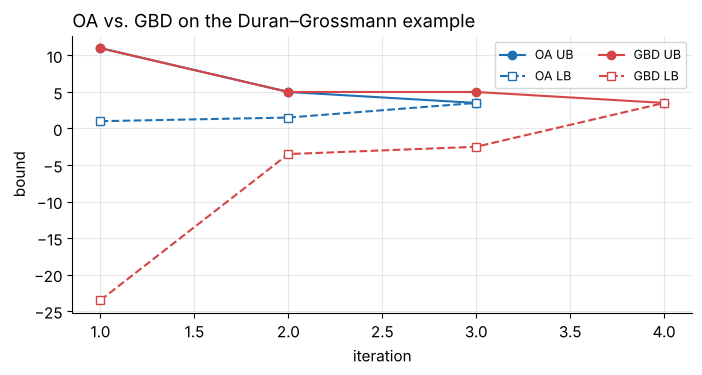


iteration   OA lower bound   GBD lower bound
        1           1.0000          -23.5000
        2           1.5000           -3.5000
        3           3.5000           -2.5000
        4              nan            3.5000


In [ ]:
gbd = generalized_benders(P, y0=[1, 1, 1])
plot_bounds({"OA": oa, "GBD": gbd}, title="OA vs. GBD on the Duran–Grossmann example")
print("\niteration   OA lower bound   GBD lower bound")
for k in range(max(len(oa["hist"]), len(gbd["hist"]))):
    lo = oa["hist"][k]["LB"] if k < len(oa["hist"]) else float("nan")
    lg = gbd["hist"][k]["LB"] if k < len(gbd["hist"]) else float("nan")
    print(f"{k+1:9d}   {lo:14.4f}   {lg:15.4f}")

🧠 **Observation.** The GBD lower bounds are much **weaker** ($-23.5$ vs. $1.0$ at iteration 1): a Benders cut is a *weighted sum* of the OA cuts at the same point, so it can never be tighter. GBD pays with extra iterations, but each master has only $m$ binaries + 1 variable.

## Part 6 · Extended Cutting Plane (Westerlund & Pettersson, 1995)

ECP never solves an NLP. It solves the OA master, linearizes the objective and the **most violated** constraint at the master's point, and repeats until the master's point is feasible.

In [ ]:
def extended_cutting_plane(P, x0, y0, max_iter=200, eps=1e-6, verbose=True):
    """ECP: only MILPs.  Linearize f at every iterate and the MOST violated constraint."""
    x, y = np.asarray(x0, float), np.asarray(y0, float)
    obj_cuts, con_cuts, hist = [], [], []
    for k in range(1, max_iter + 1):
        o, cc = oa_cuts(P, x)
        obj_cuts.append(o)
        viol = P.g(x) + P.B @ y
        j = int(np.argmax(viol))
        if viol[j] > eps:
            con_cuts.append(cc[j])
        ms = solve_master(P, obj_cuts + con_cuts, [])
        x, y, LB = ms["x"], ms["y"], ms["alpha"]
        v = P.max_violation(x, y)
        hist.append(dict(k=k, LB=LB, viol=v, y=y.copy()))
        if verbose and (k <= 10 or k % 10 == 0):
            print(f"iter {k:3d}: LB = {LB:9.4f}   y = {y.astype(int)}   max violation = {v:.2e}")
        if v <= eps and LB >= P.objective(x, y) - 1e-4 * max(1, abs(LB)):
            if verbose:
                print(f"iter {k:3d}: LB = {LB:9.4f}   y = {y.astype(int)}   max violation = {v:.2e}   ✓ converged")
            break
    return {"x": x, "y": y, "obj": P.objective(x, y), "hist": hist, "n_milp": k}

ecp = extended_cutting_plane(P, P.x0, [1, 1, 1])
print(f"\n🏆 Z* = {ecp['obj']:.4f} at y = {ecp['y'].astype(int)} with {ecp['n_milp']} MILPs and NO NLPs")

iter   1: LB =   -4.0000   y = [0 0 1]   max violation = 4.00e+00
iter   2: LB =    0.5000   y = [0 0 1]   max violation = 2.00e+00


iter   3: LB =    2.0455   y = [0 1 0]   max violation = 5.97e-01


iter   4: LB =    2.8442   y = [0 1 0]   max violation = 6.46e-01
iter   5: LB =    3.3898   y = [0 1 0]   max violation = 4.51e-02
iter   6: LB =    3.4993   y = [0 1 0]   max violation = 2.21e-04
iter   7: LB =    3.5000   y = [0 1 0]   max violation = 5.44e-09
iter   7: LB =    3.5000   y = [0 1 0]   max violation = 5.44e-09   ✓ converged

🏆 Z* = 3.5000 at y = [0 1 0] with 7 MILPs and NO NLPs


In [ ]:
ecp2 = extended_cutting_plane(oa_example_2(), [1, 2], [0, 0])
print(f"\nOA example 2: {ecp2['n_milp']} MILPs (OA needed 2 NLPs + 2 MILPs)")

iter   1: LB =  -17.0000   y = [0 1]   max violation = 6.00e+01
iter   2: LB =   -8.8750   y = [0 1]   max violation = 1.15e+01
iter   3: LB =   -4.6835   y = [0 1]   max violation = 1.00e+00
iter   4: LB =   -1.3847   y = [0 1]   max violation = 0.00e+00
iter   5: LB =   -1.1924   y = [0 0]   max violation = 0.00e+00
iter   6: LB =   -0.3399   y = [0 0]   max violation = 4.86e-01
iter   7: LB =   -0.1924   y = [0 1]   max violation = 0.00e+00
iter   8: LB =   -0.0884   y = [0 0]   max violation = 0.00e+00
iter   9: LB =   -0.0777   y = [0 1]   max violation = 0.00e+00
iter  10: LB =   -0.0203   y = [0 1]   max violation = 0.00e+00


iter  19: LB =   -0.0001   y = [0 1]   max violation = 0.00e+00   ✓ converged

OA example 2: 19 MILPs (OA needed 2 NLPs + 2 MILPs)


⚠️ **ECP converges slowly** when the optimum lies on a curved boundary: each new tangent shaves off only a sliver. It shines when NLPs are **expensive** (e.g. large flowsheets) and MILPs are cheap.

## Part 7 · Scaling up: a 10-unit capacity-planning MINLP

Choose which of 10 process units to install and how much each one produces:

$$
\begin{aligned}
\min\;& \textstyle\sum_i c_i\,y_i + \sum_i \big(b_i x_i + a_i x_i^2\big) && \text{fixed + convex operating cost}\\
\text{s.t.}\;& x_i \le U_i\,y_i && \text{no unit ⇒ no production}\\
& \textstyle\sum_i x_i \ge 100 && \text{demand}\\
& \textstyle\sum_i e_i\,x_i^{1.5} \le E_{max} && \text{convex emission cap}
\end{aligned}
$$

$2^{10} = 1024$ binary combinations: still small enough to enumerate (≈ 20 s) so we can **verify** the smart algorithms.

In [ ]:
def capacity_planning(m=10, seed=581, demand=100.0, E_max=60.0):
    """Choose which of m process units to install (binary y_i) and how much each produces (x_i):
         min  Σ c_i y_i + Σ (b_i x_i + a_i x_i²)           fixed cost + convex operating cost
         s.t. x_i <= U_i y_i                                no unit → no production
              Σ x_i >= demand                               meet the demand
              Σ e_i x_i^1.5 <= E_max                        convex emission cap"""
    rng = np.random.default_rng(seed)
    U = np.round(rng.uniform(15, 45, m)); cfix = np.round(rng.uniform(20, 60, m))
    a = np.round(rng.uniform(0.01, 0.05, m), 3); b = np.round(rng.uniform(1, 3, m), 2); e = np.round(rng.uniform(0.05, 0.25, m), 3)
    g = lambda x: np.r_[x, demand - x.sum(), e @ np.maximum(x, 0)**1.5 - E_max]
    J = lambda x: np.vstack([np.eye(m), -np.ones(m), 1.5*e*np.sqrt(np.maximum(x, 0))])
    B = np.vstack([-np.diag(U), np.zeros(m), np.zeros(m)])
    return ConvexMINLP(f"capacity planning ({m} units)", c=cfix, f=lambda x: float(b @ x + a @ x**2),
                       grad_f=lambda x: b + 2*a*x, g=g, jac_g=J, B=B, xL=np.zeros(m), xU=U, x0=U/2)

Pc = capacity_planning()
print(Pc.name, "→", Pc.n, "continuous,", Pc.m, "binary variables,", len(Pc.B), "constraints in g(x) + By <= 0")

capacity planning (10 units) → 10 continuous, 10 binary variables, 12 constraints in g(x) + By <= 0


method                   Z*  units installed           NLPs  MILPs  time (s)
Enumeration         346.175  [1, 5, 8, 9]              1024      0     17.38
B&B depth-first     346.175  [1, 5, 8, 9]                93      0      8.24
B&B best-first      346.175  [1, 5, 8, 9]                51      0      4.99
OA                  346.175  [1, 5, 8, 9]                30     23      2.91
GBD                 346.175  [1, 5, 8, 9]                47     33      2.33
ECP                 346.176  [1, 5, 8, 9]                 0     43      5.37


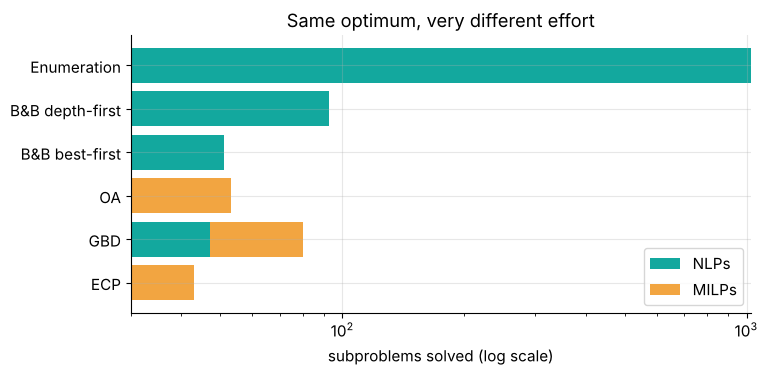

In [ ]:
# ⏱️ Race all methods on the same problem (≈ 30–60 s in total)
results = {}
t0 = time.time(); best_c, rows_c = enumerate_all(Pc, verbose=False)
results["Enumeration"] = dict(obj=best_c[1], y=np.array(best_c[0]), nlp=len(rows_c), milp=0, t=time.time() - t0)
for name, run in [("B&B depth-first", lambda: branch_and_bound(Pc, "depth", verbose=False)),
                  ("B&B best-first",  lambda: branch_and_bound(Pc, "best", verbose=False)),
                  ("OA",              lambda: outer_approximation(Pc, np.ones(10), verbose=False)),
                  ("GBD",             lambda: generalized_benders(Pc, np.ones(10), verbose=False)),
                  ("ECP",             lambda: extended_cutting_plane(Pc, Pc.x0, np.ones(10), verbose=False))]:
    t0 = time.time(); r = run()
    results[name] = dict(obj=r["obj"], y=r["y"], nlp=r.get("n_nlp", 0), milp=r.get("n_milp", 0), t=time.time() - t0, raw=r)

print(f"{'method':16s} {'Z*':>10s}  {'units installed':24s} {'NLPs':>5s} {'MILPs':>6s} {'time (s)':>9s}")
for name, r in results.items():
    units = [int(i) + 1 for i in np.where(np.round(r["y"]) == 1)[0]]
    print(f"{name:16s} {r['obj']:10.3f}  {str(units):24s} {r['nlp']:5d} {r['milp']:6d} {r['t']:9.2f}")

names = list(results)
plt.barh(names, [results[n]["nlp"] for n in names], color=TEAL, label="NLPs")
plt.barh(names, [results[n]["milp"] for n in names], left=[results[n]["nlp"] for n in names], color=GOLD, label="MILPs")
plt.xscale("log"); plt.gca().invert_yaxis(); plt.xlabel("subproblems solved (log scale)"); plt.legend()
plt.title("Same optimum, very different effort"); plt.show()

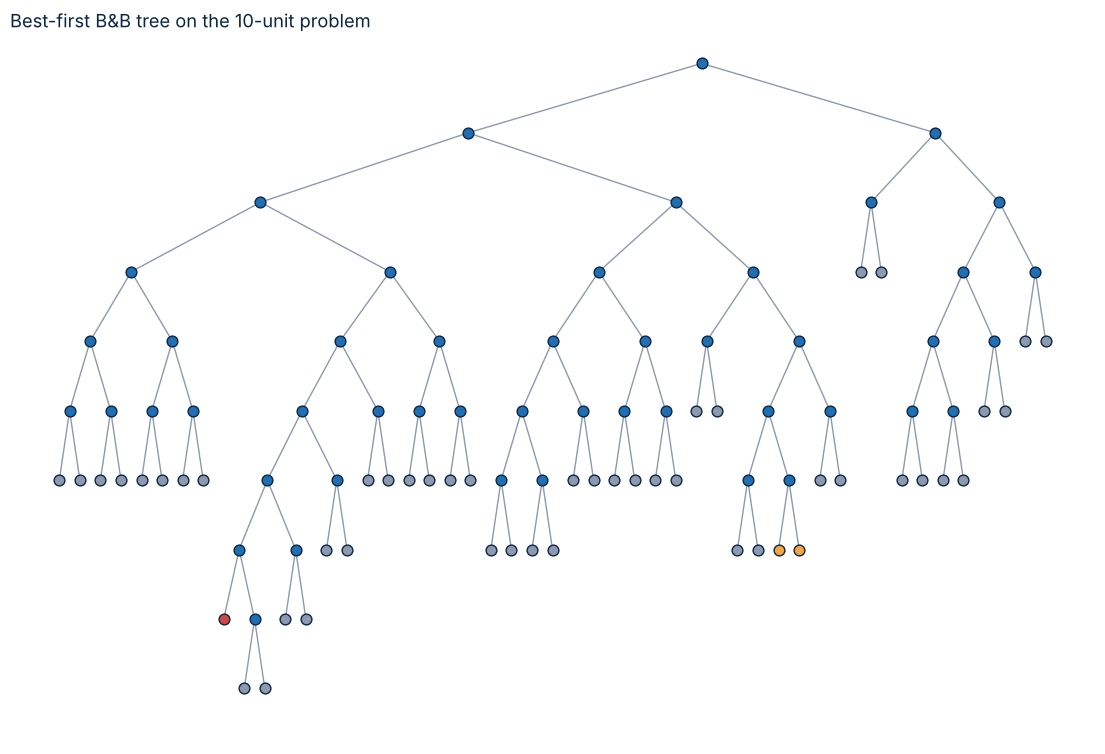

In [ ]:
draw_tree(results["B&B best-first"]["raw"]["tree"], annotate=False, title="Best-first B&B tree on the 10-unit problem")

🧠 **Take-aways.** All methods agree on the optimum (they must: the problem is convex). Enumeration needs ~1000 NLPs, B&B a few dozen, OA a few dozen NLP + MILP pairs with very strong bounds, GBD more (weaker cuts), and ECP only MILPs. On industrial problems with expensive NLPs, these differences decide whether a problem is solvable at all.

### 🧩 Exercise 7 — a stricter emission cap

Tighten the cap to `E_max = 45`. Which units are installed now, and how much does the plan cost? Explain the change.

<details><summary><b>👉 Show solution</b></summary>

```python
Pc45 = capacity_planning(E_max=45.0)
r = outer_approximation(Pc45, np.ones(10), verbose=False)
print(r["obj"], [i + 1 for i in np.where(r["y"] == 1)[0]], np.round(r["x"], 1))
```
Cost rises from **346.18 to 355.41**, and the installed set changes from units **{1, 5, 8, 9}** to **{5, 6, 8, 9}**: unit 1 (emission factor 0.164) is swapped for the cleaner unit 6 (0.099), even though unit 6 has a higher operating cost. A tighter environmental constraint changes the **structure**, not just the flows.

</details>

In [ ]:
# ✍️ Your answer to Exercise 7

## Part 8 · Real tools: Pyomo with MindtPy, Bonmin and Couenne

Writing algorithms teaches *how* they work; in practice you write the **model** and let a solver do the rest. [Pyomo](https://www.pyomo.org) is an open-source algebraic modeling language in Python.

| Solver | What it is |
|---|---|
| `mindtpy` | Pyomo's decomposition toolbox: OA, ECP, global OA, feasibility pump (needs an MILP and an NLP solver) |
| `bonmin` | COIN-OR: NLP-B&B, OA and hybrid algorithms for **convex** MINLP |
| `couenne` | COIN-OR: **global** spatial B&B for nonconvex MINLP |
| `ipopt` | interior-point **local** NLP solver |

If the cell below shows "—", set `INSTALL_SOLVERS = True` in Part 0 and run it once (Colab), or install the solvers on your machine.

In [ ]:
import logging
logging.getLogger("pyomo").setLevel(logging.ERROR)
try:
    import idaes                      # (if installed) adds ipopt, bonmin, couenne, cbc to the PATH
except ImportError:
    pass
try:
    import pyomo.environ as pyo
    HAS_PYOMO = True
except ImportError:
    HAS_PYOMO = False

def available(name):
    try:
        return HAS_PYOMO and bool(pyo.SolverFactory(name).available(exception_flag=False))
    except Exception:
        return False

print("Pyomo installed:", HAS_PYOMO)
for s in ["ipopt", "appsi_highs", "cbc", "bonmin", "couenne", "scip", "baron"]:
    print(f"   {s:12s} {'✅' if available(s) else '—'}")

Pyomo installed: True
   ipopt        ✅
   appsi_highs  ✅
   cbc          ✅
   bonmin       ✅
   couenne      ✅
   scip         —
   baron        —


In [ ]:
def build_dg():
    m = pyo.ConcreteModel()
    m.x1, m.x2 = pyo.Var(bounds=(0, 4)), pyo.Var(bounds=(0, 4))
    m.y = pyo.Var([1, 2, 3], domain=pyo.Binary)
    m.obj = pyo.Objective(expr=m.y[1] + 1.5*m.y[2] + 0.5*m.y[3] + m.x1**2 + m.x2**2)
    m.c1 = pyo.Constraint(expr=(m.x1 - 2)**2 - m.x2 <= 0)
    m.c2 = pyo.Constraint(expr=m.x1 - 2*m.y[1] >= 0)
    m.c3 = pyo.Constraint(expr=m.x1 - m.x2 - 4*(1 - m.y[2]) <= 0)
    m.c4 = pyo.Constraint(expr=m.x1 - (1 - m.y[1]) >= 0)
    m.c5 = pyo.Constraint(expr=m.x2 - m.y[2] >= 0)
    m.c6 = pyo.Constraint(expr=m.x1 + m.x2 >= 3*m.y[3])
    m.c7 = pyo.Constraint(expr=m.y[1] + m.y[2] + m.y[3] >= 1)
    return m

RUNS = [("MindtPy · OA",  "mindtpy", dict(strategy="OA",  mip_solver="appsi_highs", nlp_solver="ipopt"), ["appsi_highs", "ipopt"]),
        ("MindtPy · ECP", "mindtpy", dict(strategy="ECP", mip_solver="appsi_highs", nlp_solver="ipopt"), ["appsi_highs", "ipopt"]),
        ("Bonmin",        "bonmin",  {}, ["bonmin"]),
        ("Couenne",       "couenne", {}, ["couenne"])]

if HAS_PYOMO:
    for label, solver, opts, needs in RUNS:
        if not all(available(s) for s in needs):
            print(f"{label:14s}  (solver not installed)"); continue
        m = build_dg(); t0 = time.time()
        pyo.SolverFactory(solver).solve(m, **opts)
        print(f"{label:14s}  Z* = {pyo.value(m.obj):.4f}   y = {[round(pyo.value(m.y[j])) for j in (1, 2, 3)]}"
              f"   x = ({pyo.value(m.x1):.3f}, {pyo.value(m.x2):.3f})   {time.time() - t0:.2f} s")
else:
    print("Pyomo is not installed — run the optional install cell in Part 0 to try this part.")

MindtPy · OA    Z* = 3.5000   y = [0, 1, 0]   x = (1.000, 1.000)   0.16 s


MindtPy · ECP   Z* = 3.5000   y = [0, 1, 0]   x = (1.000, 1.000)   0.09 s


Bonmin          Z* = 3.5000   y = [0, 1, 0]   x = (1.000, 1.000)   0.04 s


Couenne         Z* = 3.5000   y = [0, 1, 0]   x = (1.000, 1.000)   0.04 s


### 🛠️ Process synthesis: which reactor? (Kocis & Grossmann, 1987)

Product B (10 units) is made from feed A in **one of two** candidate reactors:

- **R1:** fixed cost 7.5, volume cost $7.0\,v$, conversion $z_1 = 0.9\,(1 - e^{-0.5\,v_1})\,x_1$
- **R2:** fixed cost 5.5, volume cost $6.0\,v$, conversion $z_2 = 0.8\,(1 - e^{-0.4\,v_2})\,x_2$

Feed costs 5 per unit, $v \le 10\,y$, $x \le 20\,y$, $y_1 + y_2 = 1$. R2 is **cheaper to build** but converts **less**, so it needs more feed. Which wins? First by enumeration (two NLPs), then in Pyomo:

In [ ]:
# Two-reactor process selection (Kocis & Grossmann, 1987): make 10 units of B from A with reactor R1 OR R2.
#   min  fixed·y + vol_cost·v + 5·x      s.t.  z = conv·(1 − e^{−k v})·x = demand,  v <= 10y,  x <= 20y,  y1 + y2 = 1
REACTORS = {"R1": dict(fixed=7.5, vol_cost=7.0, k=0.5, conv=0.9), "R2": dict(fixed=5.5, vol_cost=6.0, k=0.4, conv=0.8)}

def reactor_nlp(r, demand=10.0):
    """NLP for a FIXED choice of reactor r: variables (v, x).  The kinetics equality makes it nonconvex."""
    p = REACTORS[r]
    cost = lambda z: p["fixed"] + p["vol_cost"]*z[0] + 5*z[1]
    kin = lambda z: p["conv"]*(1 - np.exp(-p["k"]*z[0]))*z[1] - demand
    best = None
    for v0 in np.linspace(0.5, 10, 12):                     # multistart: the equality constraint is nonconvex
        res = minimize(cost, [v0, 15.0], method="SLSQP", bounds=[(0, 10), (0, 20)], constraints=[{"type": "eq", "fun": kin}])
        if res.success and abs(kin(res.x)) < 1e-6 and (best is None or res.fun < best.fun):
            best = res
    return (best.fun, best.x) if best is not None else (np.inf, None)

for r in REACTORS:
    Z, (v, x) = reactor_nlp(r)
    print(f"choose {r}:  cost = {Z:8.4f}   volume v = {v:.3f}   feed x = {x:.3f}")

choose R1:  cost =  99.2396   volume v = 3.514   feed x = 13.428
choose R2:  cost = 107.3764   volume v = 4.479   feed x = 15.000


In [ ]:
def build_reactors(demand=10.0):
    m = pyo.ConcreteModel()
    m.R = pyo.Set(initialize=list(REACTORS))
    m.y = pyo.Var(m.R, domain=pyo.Binary)
    m.v = pyo.Var(m.R, bounds=(0, 10)); m.x = pyo.Var(m.R, bounds=(0, 20)); m.z = pyo.Var(m.R, bounds=(0, 20))
    m.cost = pyo.Objective(expr=sum(REACTORS[r]["fixed"]*m.y[r] + REACTORS[r]["vol_cost"]*m.v[r] + 5*m.x[r] for r in m.R))
    m.kinetics = pyo.Constraint(m.R, rule=lambda m, r: m.z[r] == REACTORS[r]["conv"]*(1 - pyo.exp(-REACTORS[r]["k"]*m.v[r]))*m.x[r])
    m.demand = pyo.Constraint(expr=sum(m.z[r] for r in m.R) == demand)
    m.v_on = pyo.Constraint(m.R, rule=lambda m, r: m.v[r] <= 10*m.y[r])       # no reactor → no volume
    m.x_on = pyo.Constraint(m.R, rule=lambda m, r: m.x[r] <= 20*m.y[r])       # no reactor → no feed
    m.one = pyo.Constraint(expr=sum(m.y[r] for r in m.R) == 1)                # exactly one reactor
    return m

if HAS_PYOMO:
    for label, solver, opts, needs in [RUNS[0], RUNS[2], RUNS[3]]:
        if not all(available(s) for s in needs):
            print(f"{label:14s}  (solver not installed)"); continue
        m = build_reactors()
        pyo.SolverFactory(solver).solve(m, **opts)
        chosen = [r for r in m.R if pyo.value(m.y[r]) > 0.5]
        print(f"{label:14s}  cost = {pyo.value(m.cost):.4f}   reactor = {chosen}   "
              f"v = {pyo.value(m.v[chosen[0]]):.3f}   x = {pyo.value(m.x[chosen[0]]):.3f}")

MindtPy · OA    cost = 99.2396   reactor = ['R1']   v = 3.514   x = 13.428


Bonmin          cost = 99.2396   reactor = ['R1']   v = 3.514   x = 13.428


Couenne         cost = 99.2396   reactor = ['R1']   v = 3.512   x = 13.431


### 🧩 Exercise 8 — more product

Raise the demand to **14** units. Does the choice of reactor change? *Hint:* `reactor_nlp(r, demand=14)` (and `build_reactors(14)` if you have Pyomo).

<details><summary><b>👉 Show solution</b></summary>

```python
for r in REACTORS:
    print(r, reactor_nlp(r, demand=14.0))
```
R1: cost **125.45** ($v = 4.01$, $x = 17.98$); R2: cost **136.69** ($v = 5.20$, $x = 20.0$, the feed limit is active). **R1 still wins**, and R2 is close to its feed limit: at a slightly higher demand it becomes infeasible.

</details>

In [ ]:
# ✍️ Your answer to Exercise 8

## Part 9 · Nonconvex problems & global optimization

### 9.1 Local solvers get trapped

First the lecture's toy problem $\min -x-y$ s.t. $xy \le 4$, from 200 random starting points:

local solver ended at f =  -6.667   in 138 of 200 runs
local solver ended at f =  -5.000   in  62 of 200 runs


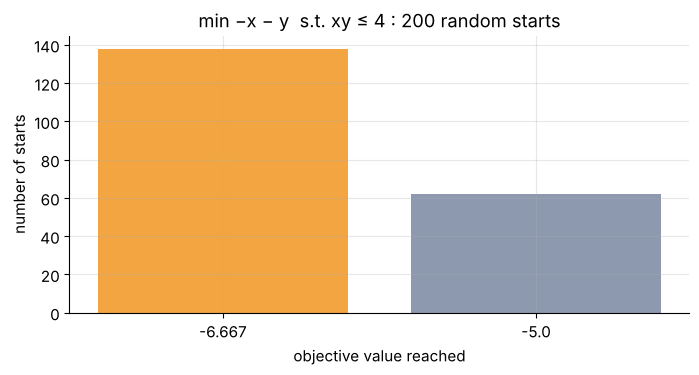

In [ ]:
rng = np.random.default_rng(581)
finals = []
for _ in range(200):
    r = minimize(lambda z: -z[0] - z[1], rng.uniform([0, 0], [6, 4]), method="SLSQP", bounds=[(0, 6), (0, 4)],
                 constraints=[{"type": "ineq", "fun": lambda z: 4 - z[0]*z[1]}])
    finals.append(round(r.fun, 3))
vals, counts = np.unique(finals, return_counts=True)
for v, c in zip(vals, counts):
    print(f"local solver ended at f = {v:7.3f}   in {c:3d} of 200 runs")
plt.bar([str(v) for v in vals], counts, color=[GOLD if v == vals.min() else GRAY for v in vals])
plt.xlabel("objective value reached"); plt.ylabel("number of starts"); plt.title("min −x − y  s.t. xy ≤ 4 : 200 random starts"); plt.show()

Now a real refinery problem: the **Haverly pooling problem** (Haverly, 1978). Crudes A and B are mixed in a **pool** whose sulfur content $p$ is unknown; crude C bypasses the pool. The pool balance $p\,(P_x + P_y) = 3A + B$ and the product specifications contain **bilinear** terms $p \cdot P_x$, $p \cdot P_y$: a classic nonconvex model.

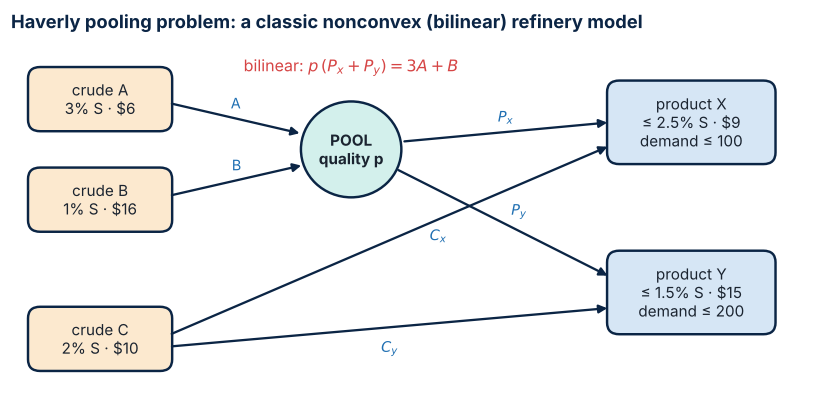

In [ ]:
# variables z = [A, B, C, Px, Py, Cx, Cy, p]   (flows in bbl/day, p = sulfur % in the pool)
LB_H = np.array([0, 0, 0, 0, 0, 0, 0, 1.0]); UB_H = np.array([300, 300, 300, 100, 200, 100, 200, 3.0])

def haverly_cost(z, price_B=16.0):          # minimize (crude cost − product revenue) = −profit
    A, B, C, Px, Py, Cx, Cy, p = z
    return 6*A + price_B*B + 10*C - 9*(Px + Cx) - 15*(Py + Cy)

def haverly_eq(z):                          # pool balance, C split, sulfur balance (BILINEAR: p·(Px+Py))
    A, B, C, Px, Py, Cx, Cy, p = z
    return np.array([A + B - Px - Py, C - Cx - Cy, p*(Px + Py) - 3*A - B])

def haverly_ineq(z):                        # >= 0 : sulfur specs (bilinear p·Px, p·Py) and demands
    A, B, C, Px, Py, Cx, Cy, p = z
    return np.array([2.5*(Px + Cx) - p*Px - 2*Cx, 1.5*(Py + Cy) - p*Py - 2*Cy, 100 - Px - Cx, 200 - Py - Cy])

def haverly_local(z0, lb=LB_H, ub=UB_H, price_B=16.0):
    r = minimize(haverly_cost, z0, args=(price_B,), method="SLSQP", bounds=list(zip(lb, ub)),
                 constraints=[{"type": "eq", "fun": haverly_eq}, {"type": "ineq", "fun": haverly_ineq}],
                 options={"ftol": 1e-10, "maxiter": 500})
    ok = r.success and np.abs(haverly_eq(r.x)).max() < 1e-5 and haverly_ineq(r.x).min() > -1e-5
    return (r.fun if ok else np.inf), r.x

rng = np.random.default_rng(7)
outcomes = []
for _ in range(60):
    v, z = haverly_local(rng.uniform(LB_H, UB_H))
    outcomes.append(np.inf if not np.isfinite(v) else round(-v, 1))      # report PROFIT = −cost
vals, counts = np.unique(outcomes, return_counts=True)
for v, c in zip(vals, counts):
    print(f"profit = {v:8.1f} $/day   reached from {c:2d} of 60 random starts" if np.isfinite(v) else f"failed / infeasible: {c} starts")

profit =    100.0 $/day   reached from  2 of 60 random starts
profit =    400.0 $/day   reached from 58 of 60 random starts


⚠️ A few starts stop at a profit of **100 \$/day**, only a quarter of the best value. Without a *global* method, you could never tell whether 400 is the best possible.

### 9.2 Convexification by the exponential transformation

The lecture exercise: $\min 3x_1^7x_3 + 2x_2^2x_3^2 + 5/x_2 + 2y_1^{0.5} + 3y_2$ s.t. $x_1x_3 \le 4x_2^{0.3}$, $4x_1^2 - 2y_2^2 \le 3$ (we add $0.1 \le x \le 10$ so that the optimum is attained). With $y^{0.5} = y$, $y^2 = y$ and $x_j = e^{u_j}$ every function becomes convex, so **every local optimum is global**: random starts must all agree.

In [ ]:
# Lecture exercise (with bounds 0.1 <= x <= 10 so that the problem has a finite optimum):
#   min 3 x1^7 x3 + 2 x2² x3² + 5/x2 + 2 y1^0.5 + 3 y2   s.t.  x1 x3 <= 4 x2^0.3,  4 x1² − 2 y2² <= 3
# With binaries y^0.5 = y, y² = y, and with x = e^u:
f_u   = lambda u, y: 3*np.exp(7*u[0] + u[2]) + 2*np.exp(2*u[1] + 2*u[2]) + 5*np.exp(-u[1]) + 2*y[0] + 3*y[1]
g_lin = lambda u, y: np.log(4) + 0.3*u[1] - u[0] - u[2]        # >= 0   (LINEAR in u)
g_cvx = lambda u, y: 3 + 2*y[1] - 4*np.exp(2*u[0])             # >= 0   (convex constraint 4e^{2u1} − 2y2 <= 3)
ub = [(np.log(0.1), np.log(10))]*3

def solve_u(y, start):
    return minimize(f_u, start, args=(y,), method="SLSQP", bounds=ub, options={"ftol": 1e-12, "maxiter": 500},
                    constraints=[{"type": "ineq", "fun": g_lin, "args": (y,)}, {"type": "ineq", "fun": g_cvx, "args": (y,)}])

rng = np.random.default_rng(3)
for y in itertools.product([0, 1], repeat=2):
    sols = [solve_u(y, rng.uniform(-2.3, 2.3, 3)) for _ in range(20)]
    objs = np.array([s.fun for s in sols if s.success])
    best = min(sols, key=lambda s: s.fun)
    print(f"y = {y}:  Z = {best.fun:.4f}  at x = {np.round(np.exp(best.x), 3)}   "
          f"(20 random starts: spread of optima = {objs.max() - objs.min():.1e})")

y = (0, 0):  Z = 1.5000  at x = [0.1 5.  0.1]   (20 random starts: spread of optima = 5.0e-14)


y = (0, 1):  Z = 4.5000  at x = [0.1 5.  0.1]   (20 random starts: spread of optima = 6.6e-13)
y = (1, 0):  Z = 3.5000  at x = [0.1 5.  0.1]   (20 random starts: spread of optima = 1.0e-13)


y = (1, 1):  Z = 6.5000  at x = [0.1 5.  0.1]   (20 random starts: spread of optima = 1.5e-08)


### 9.3 McCormick envelopes

`mccormick(...)` returns the four inequalities as LP rows. Check the lecture's LP bound and the $\tfrac14\,\Delta x\,\Delta y$ gap formula:

In [ ]:
def mccormick(ix, iy, iw, xL, xU, yL, yU, nvar):
    """Four rows (A, b) with A·z <= b that relax w = x·y on the box [xL,xU]×[yL,yU]."""
    def row(cx, cy, cw):
        r = np.zeros(nvar); r[ix] += cx; r[iy] += cy; r[iw] += cw; return r
    A = [row(yL, xL, -1), row(yU, xU, -1),           # w >= xL·y + x·yL − xL·yL ,  w >= xU·y + x·yU − xU·yU
         row(-yL, -xU, 1), row(-yU, -xL, 1)]         # w <= xU·y + x·yL − xU·yL ,  w <= xL·y + x·yU − xL·yU
    b = [xL*yL, xU*yU, -xU*yL, -xL*yU]
    return A, b

# the lecture example:  min −x − y  s.t. xy <= 4   →   z = [x, y, w]
A, b = mccormick(0, 1, 2, 0, 6, 0, 4, 3)
lp = linprog([-1, -1, 0], A_ub=A + [[0, 0, 1]], b_ub=b + [4], bounds=[(0, 6), (0, 4), (None, None)], method="highs")
print(f"McCormick LP bound = {lp.fun:.4f} at x = {lp.x[0]:.3f}, y = {lp.x[1]:.3f}   (global optimum = −6.667)")

McCormick LP bound = -6.6667 at x = 6.000, y = 0.667   (global optimum = −6.667)


In [ ]:
def max_gap(xL, xU, yL, yU, parts):
    """Largest gap between xy and the McCormick under-estimator when [xL, xU] is split into `parts` pieces."""
    worst = 0.0
    for a, b_ in zip(np.linspace(xL, xU, parts + 1)[:-1], np.linspace(xL, xU, parts + 1)[1:]):
        X, Y = np.meshgrid(np.linspace(a, b_, 81), np.linspace(yL, yU, 81))
        under = np.maximum(a*Y + X*yL - a*yL, b_*Y + X*yU - b_*yU)
        worst = max(worst, (X*Y - under).max())
    return worst

for parts in [1, 2, 4, 8, 16]:
    print(f"x-range split into {parts:2d} pieces:  max gap = {max_gap(0, 6, 0, 4, parts):.3f}"
          f"   (theory ΔxΔy/4 = {6/parts*4/4:.3f})")

x-range split into  1 pieces:  max gap = 6.000   (theory ΔxΔy/4 = 6.000)
x-range split into  2 pieces:  max gap = 3.000   (theory ΔxΔy/4 = 3.000)
x-range split into  4 pieces:  max gap = 1.500   (theory ΔxΔy/4 = 1.500)
x-range split into  8 pieces:  max gap = 0.750   (theory ΔxΔy/4 = 0.750)
x-range split into 16 pieces:  max gap = 0.375   (theory ΔxΔy/4 = 0.375)


🧠 Every halving of the $x$-range **halves** the worst gap. That is the engine of spatial branch & bound.

### 9.4 Spatial branch & bound in one dimension (αBB)

$\min f(x) = 0.25x + \sin x$ on $[-3, 6]$. Since $f''(x) = -\sin x \ge -1$, the αBB underestimator $L(x) = f(x) + \alpha(x^L - x)(x^U - x)$ is convex for $\alpha \ge 0.5$.

In [ ]:
def spatial_bb_1d(f, lo, hi, alpha, eps=1e-3, verbose=True):
    """Global minimum of f on [lo, hi] with the αBB underestimator  L(x) = f(x) + α (a − x)(b − x)."""
    def lower(a, b):
        r = minimize_scalar(lambda x: f(x) + alpha*(a - x)*(b - x), bounds=(a, b), method="bounded")
        return r.fun, r.x
    def upper(a, b, x0):
        r = minimize(lambda x: f(x[0]), [x0], bounds=[(a, b)]); return float(r.fun), float(r.x[0])
    UB, xbest, regions, log = np.inf, None, [(lo, hi)], []
    while regions:
        regions.sort(key=lambda R: lower(*R)[0]); a, b = regions.pop(0)
        l, xl = lower(a, b)
        if l > UB - eps:
            continue
        u, xu = upper(a, b, xl)
        if u < UB:
            UB, xbest = u, xu
        branch = u - l > eps
        if branch:
            regions += [(a, (a + b)/2), ((a + b)/2, b)]
        regions = [R for R in regions if lower(*R)[0] <= UB - eps]
        log.append((a, b, l, u))
        if verbose:
            print(f"node {len(log):2d}: [{a:6.3f}, {b:6.3f}]  l = {l:8.4f}   u = {u:8.4f}   UB = {UB:8.4f}   {'branch' if branch else 'solved'}")
    return xbest, UB, log

f1 = lambda x: 0.25*x + np.sin(x)
alpha = max(0.0, -0.5*min(-np.sin(np.linspace(-3, 6, 2001))))   # α >= −½·min f''(x),  f'' = −sin x
print(f"α = {alpha:.3f}")
x_star, f_star, log = spatial_bb_1d(f1, -3, 6, alpha)
print(f"\nglobal minimum: x* = {x_star:.4f},  f* = {f_star:.4f}")

α = 0.500
node  1: [-3.000,  6.000]  l =  -9.0345   u =  -1.4241   UB =  -1.4241   branch
node  2: [-3.000,  1.500]  l =  -3.6688   u =  -1.4241   UB =  -1.4241   branch
node  3: [ 1.500,  6.000]  l =  -2.2634   u =   0.1467   UB =  -1.4241   branch
node  4: [-3.000, -0.750]  l =  -2.0563   u =  -1.4241   UB =  -1.4241   branch
node  5: [-1.875, -0.750]  l =  -1.5176   u =  -1.4241   UB =  -1.4241   branch
node  6: [-3.000, -1.875]  l =  -1.4913   u =  -1.4228   UB =  -1.4241   branch
node  7: [-1.875, -1.312]  l =  -1.4506   u =  -1.4241   UB =  -1.4241   branch
node  8: [-2.438, -1.875]  l =  -1.4367   u =  -1.4228   UB =  -1.4241   branch
node  9: [-1.875, -1.594]  l =  -1.4320   u =  -1.4241   UB =  -1.4241   branch
node 10: [-1.875, -1.734]  l =  -1.4265   u =  -1.4241   UB =  -1.4241   branch

global minimum: x* = -1.8235,  f* = -1.4241


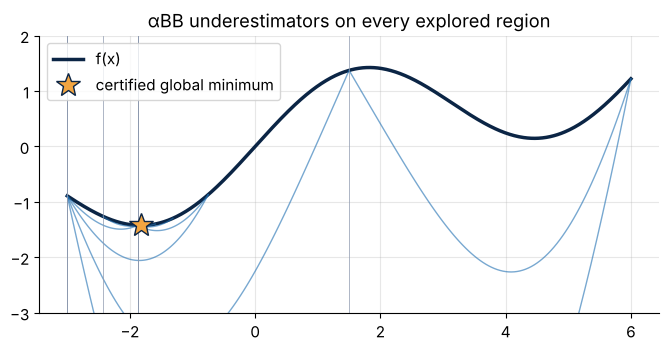

In [ ]:
xs = np.linspace(-3, 6, 600)
plt.plot(xs, f1(xs), color=NAVY, lw=2.5, label="f(x)")
for a, b_, l, u in log:
    xx = np.linspace(a, b_, 100)
    plt.plot(xx, f1(xx) + alpha*(a - xx)*(b_ - xx), color=BLUE, lw=1, alpha=0.6)
    plt.axvline(a, color=GRAY, lw=0.5)
plt.plot(x_star, f_star, "*", ms=18, color=GOLD, mec=NAVY, label="certified global minimum")
plt.ylim(-3, 2); plt.legend(); plt.title("αBB underestimators on every explored region"); plt.show()

### 9.5 Certifying the global optimum of the pooling problem

Spatial B&B on Haverly's problem: the **lower bound** comes from an LP in which $p\,P_x$ and $p\,P_y$ are replaced by McCormick envelopes on the current range of $p$; the **upper bound** comes from a local NLP started at the LP solution; we **branch on $p$**.

In [ ]:
def haverly_relaxation(pL, pU, price_B=16.0):
    """LP: replace w1 = p·Px and w2 = p·Py by McCormick envelopes on p ∈ [pL, pU].  z = [8 originals, w1, w2]."""
    nv = 10
    c = np.r_[6, price_B, 10, -9, -15, -9, -15, 0, 0, 0]
    Aeq = np.zeros((3, nv)); Aeq[0, [0, 1, 3, 4]] = [1, 1, -1, -1]; Aeq[1, [2, 5, 6]] = [1, -1, -1]
    Aeq[2, [8, 9, 0, 1]] = [1, 1, -3, -1]                     # w1 + w2 = 3A + B   (sulfur balance)
    A, b = [], []
    r = np.zeros(nv); r[[8, 3, 5]] = [1, -2.5, -0.5]; A.append(r); b.append(0)    # w1 + 2Cx <= 2.5(Px + Cx)
    r = np.zeros(nv); r[[9, 4, 6]] = [1, -1.5, 0.5]; A.append(r); b.append(0)    # w2 + 2Cy <= 1.5(Py + Cy)
    r = np.zeros(nv); r[[3, 5]] = 1; A.append(r); b.append(100)
    r = np.zeros(nv); r[[4, 6]] = 1; A.append(r); b.append(200)
    for ix, iw in [(3, 8), (4, 9)]:
        Am, bm = mccormick(7, ix, iw, pL, pU, LB_H[ix], UB_H[ix], nv); A += Am; b += bm
    lb = np.r_[LB_H, -1e4, -1e4]; ubd = np.r_[UB_H, 1e4, 1e4]; lb[7], ubd[7] = pL, pU
    res = linprog(c, A_ub=np.array(A), b_ub=b, A_eq=Aeq, b_eq=np.zeros(3), bounds=list(zip(lb, ubd)), method="highs")
    return (res.fun, res.x[:8]) if res.status == 0 else (np.inf, None)

def haverly_spatial_bb(price_B=16.0, eps=1e-3, verbose=True):
    UB, best, regions, k = np.inf, None, [(1.0, 3.0)], 0
    while regions:
        bounds = [haverly_relaxation(a, b, price_B) for a, b in regions]
        i = int(np.argmin([l for l, _ in bounds])); (a, b), (l, zr) = regions.pop(i), bounds[i]
        k += 1
        if l >= UB - eps:
            continue
        lb, ubd = LB_H.copy(), UB_H.copy(); lb[7], ubd[7] = a, b
        u, zu = haverly_local(np.clip(zr, lb, ubd), lb, ubd, price_B)       # local solve started from the LP point
        if u < UB:
            UB, best = u, zu
        if u - l > eps:
            regions += [(a, (a + b)/2), ((a + b)/2, b)]
        regions = [R for R in regions if haverly_relaxation(*R, price_B)[0] < UB - eps]
        if verbose:
            print(f"node {k:2d}: p ∈ [{a:.3f}, {b:.3f}]   LB = {l:9.3f}   local = {u:9.3f}   best = {UB:9.3f}"
                  f"   {'branch' if u - l > eps else 'solved'}")
    return best, UB

z_best, cost_best = haverly_spatial_bb()
names = ["A", "B", "C", "Px", "Py", "Cx", "Cy", "p"]
print(f"\n🏆 certified global optimum: profit = {-cost_best:.1f} $/day")
print("   " + ",  ".join(f"{n} = {v:.1f}" for n, v in zip(names, z_best)))

node  1: p ∈ [1.000, 3.000]   LB =  -500.000   local =  -400.000   best =  -400.000   branch

🏆 certified global optimum: profit = 400.0 $/day
   A = 0.0,  B = 100.0,  C = 100.0,  Px = 0.0,  Py = 100.0,  Cx = 0.0,  Cy = 100.0,  p = 1.0


🧠 **One branching is enough here.** At the root the McCormick LP gives $-500$ (a profit of at most 500) while the local solve finds 400. After splitting $p$ at 2, the LP bound is $-400$ on $[1, 2]$ (equal to the incumbent) and $-100$ on $[2, 3]$, so **both halves are pruned** and 400 \$/day is **proven** globally optimal.

The same comparison with industrial solvers (if installed): `ipopt` is a *local* solver and stops where it starts; `couenne` is *global*.

In [ ]:
def build_haverly():
    m = pyo.ConcreteModel()
    for n, lo, hi in zip(["A", "B", "C", "Px", "Py", "Cx", "Cy", "p"], LB_H, UB_H):
        setattr(m, n, pyo.Var(bounds=(lo, hi)))
    m.profit = pyo.Objective(expr=9*(m.Px + m.Cx) + 15*(m.Py + m.Cy) - 6*m.A - 16*m.B - 10*m.C, sense=pyo.maximize)
    m.pool = pyo.Constraint(expr=m.A + m.B == m.Px + m.Py)
    m.split = pyo.Constraint(expr=m.C == m.Cx + m.Cy)
    m.sulfur = pyo.Constraint(expr=m.p*(m.Px + m.Py) == 3*m.A + m.B)
    m.specX = pyo.Constraint(expr=m.p*m.Px + 2*m.Cx <= 2.5*(m.Px + m.Cx))
    m.specY = pyo.Constraint(expr=m.p*m.Py + 2*m.Cy <= 1.5*(m.Py + m.Cy))
    m.demX = pyo.Constraint(expr=m.Px + m.Cx <= 100)
    m.demY = pyo.Constraint(expr=m.Py + m.Cy <= 200)
    return m

if HAS_PYOMO:
    for solver in ["ipopt", "couenne"]:
        if not available(solver):
            print(f"{solver}: not installed"); continue
        m = build_haverly(); m.p.value = 3.0; m.A.value = 100; m.Px.value = 100      # a "bad" starting point
        pyo.SolverFactory(solver).solve(m)
        kind = "local NLP" if solver == "ipopt" else "global (spatial B&B)"
        print(f"{solver:8s} [{kind:20s}]  profit = {pyo.value(m.profit):7.2f} $/day   p = {pyo.value(m.p):.3f}")

ipopt    [local NLP           ]  profit =  100.00 $/day   p = 3.000


couenne  [global (spatial B&B)]  profit =  400.00 $/day   p = 1.000


### 🧩 Exercise 9 — cheaper low-sulfur crude

Crude B becomes cheaper: **\$13** instead of \$16. Use `haverly_spatial_bb(price_B=13.0)`. What is the new global profit, and how does the pool operate?

<details><summary><b>👉 Show solution</b></summary>

```python
z9, c9 = haverly_spatial_bb(price_B=13.0, verbose=False)
print(-c9, dict(zip(names, np.round(z9, 2))))
```
Profit jumps to **\$750/day**: the pool now blends A = 50 and B = 150 to $p = 1.5\%$, exactly the Y specification, and sends all 200 bbl/day to the high-value product Y (crude C is no longer used).

</details>

In [ ]:
# ✍️ Your answer to Exercise 9

## Part 10 · Fractional objectives: cost per functional unit

A small **biorefinery** superstructure (illustrative data): build any of three technologies $y_i$ and choose their production $x_i$ (M GEG/yr) to minimize the **unit cost**

$$\min\; q = \frac{N(x, y)}{D(x, y)} = \frac{\sum_i F_i\,y_i + \sum_i v_i\,x_i}{\sum_i x_i} \quad [\$/\text{GEG}]
\qquad\text{s.t.}\quad x_i \le \text{cap}_i\,y_i,\;\; \textstyle\sum_i \text{bio}_i\,x_i \le S,\;\; \sum_i x_i \ge D_{min}$$

This is a **mixed-integer linear fractional program (MILFP)**. We solve it three ways and check that they agree.

In [ ]:
# 3 candidate biorefinery technologies (illustrative data)
tech   = ["A (pyrolysis)", "B (gasification-FT)", "C (fermentation)"]
Fix    = np.array([12., 30., 8.])        # fixed cost             (M$/yr)
var    = np.array([1.9, 1.4, 2.6])       # variable cost          ($/GEG)
cap    = np.array([40., 80., 30.])       # capacity               (M GEG/yr)
bio    = np.array([0.012, 0.016, 0.020]) # biomass use            (Mt per M GEG)
emis   = np.array([1.1, 1.9, 0.6])       # life-cycle emission    (kg CO2-eq/GEG)
S, Dmin = 1.0, 20.0                      # biomass available (Mt/yr), minimum production (M GEG/yr)

def bio_constraints(eps=None, S=S):
    """Rows A z <= b for z = [x_A, x_B, x_C, y_A, y_B, y_C]."""
    A = [np.r_[np.eye(3)[i], -cap[i]*np.eye(3)[i]] for i in range(3)]       # x_i <= cap_i y_i
    b = [0, 0, 0]
    A.append(np.r_[bio, 0, 0, 0]); b.append(S)                              # biomass limit
    A.append(np.r_[-1, -1, -1, 0, 0, 0]); b.append(-Dmin)                   # minimum production
    if eps is not None:
        A.append(np.r_[emis - eps, 0, 0, 0]); b.append(0)                   # unit emission <= eps  (linearized ratio)
    return np.array(A), np.array(b, float)

N_c = np.r_[var, Fix]                    # numerator   N(z) = total cost   (M$/yr)
D_c = np.r_[1, 1, 1, 0, 0, 0]            # denominator D(z) = production   (M GEG/yr)
INT = np.r_[0, 0, 0, 1, 1, 1]; LBZ, UBZ = np.zeros(6), np.r_[cap, 1, 1, 1]

**Way 1 · brute force.** For a fixed $y$ the problem is a linear-fractional program, which the **Charnes–Cooper** substitution $t = 1/D$, $s = t\,x$ turns into an **LP**:

In [ ]:
def lfp_for_fixed_y(y, eps=None, S=S):
    """For a fixed y the problem is a linear-fractional program; Charnes–Cooper turns it into an LP:
       t = 1/D, s = t·x:   min (var·s + Fix·y·t)  s.t.  Σs = 1,  s_i <= cap_i y_i t,  bio·s <= S t,  Σs >= Dmin t."""
    c = np.r_[var, Fix @ y]
    A = [np.r_[np.eye(3)[i], -cap[i]*y[i]] for i in range(3)] + [np.r_[bio, -S], np.r_[-1, -1, -1, Dmin]]
    b = [0, 0, 0, 0, 0]
    if eps is not None:
        A.append(np.r_[emis - eps, 0]); b.append(0)
    r = linprog(c, A_ub=A, b_ub=b, A_eq=[[1, 1, 1, 0]], b_eq=[1], bounds=[(0, None)]*4, method="highs")
    return (r.fun, r.x[:3]/r.x[3]) if r.status == 0 else (np.inf, None)

for y in itertools.product([0, 1], repeat=3):
    if sum(y) == 0: continue
    q, x = lfp_for_fixed_y(np.array(y, float))
    print(f"plants {y}:  " + (f"unit cost = {q:.4f} $/GEG,  x = {np.round(x, 1)}" if np.isfinite(q) else "infeasible"))

plants (0, 0, 1):  unit cost = 2.8667 $/GEG,  x = [-0. -0. 30.]
plants (0, 1, 0):  unit cost = 1.8800 $/GEG,  x = [ 0.  62.5  0. ]
plants (0, 1, 1):  unit cost = 2.0080 $/GEG,  x = [ 0.  62.5  0. ]
plants (1, 0, 0):  unit cost = 2.2000 $/GEG,  x = [40. -0.  0.]
plants (1, 0, 1):  unit cost = 2.4000 $/GEG,  x = [40. -0.  0.]
plants (1, 1, 0):  unit cost = 2.0720 $/GEG,  x = [ 0.  62.5  0. ]
plants (1, 1, 1):  unit cost = 2.2000 $/GEG,  x = [ 0.  62.5  0. ]


**Way 2 · Dinkelbach's parametric algorithm.** $F(q) = \min N - q\,D$ is an MILP; Newton's method on $F(q) = 0$ uses $q_{k+1} = N(z_k)/D(z_k)$.

In [ ]:
def dinkelbach(A, b, q0=0.0, tol=1e-9, verbose=True):
    """Parametric (Newton) algorithm:  F(q) = min N(z) − q D(z)   (an MILP);  q_{k+1} = N(z_k)/D(z_k)."""
    q, hist = q0, []
    for k in range(1, 100):
        z = milp(N_c - q*D_c, constraints=LinearConstraint(A, -np.inf, b), integrality=INT, bounds=Bounds(LBZ, UBZ)).x
        Nv, Dv = N_c @ z, D_c @ z; F = Nv - q*Dv
        hist.append((q, F, -Dv))                     # (q_k, F(q_k), slope of F at q_k = −D(z_k))
        if verbose:
            print(f"iter {k}: q = {q:9.5f}   F(q) = {F:10.5f}   plants = {np.round(z[3:]).astype(int)}   → q_new = {Nv/Dv:.5f}")
        if abs(F) <= tol*max(1.0, Dv):
            return z, Nv/Dv, hist
        q = Nv/Dv
    raise RuntimeError("no convergence")

A_bio, b_bio = bio_constraints()
z_dk, q_dk, hist_dk = dinkelbach(A_bio, b_bio)
print(f"\n✅ optimal unit cost q* = {q_dk:.4f} $/GEG,  production = {np.round(z_dk[:3], 2)} M GEG/yr")

iter 1: q =   0.00000   F(q) =   50.00000   plants = [1 0 0]   → q_new = 2.50000
iter 2: q =   2.50000   F(q) =  -38.75000   plants = [0 1 0]   → q_new = 1.88000
iter 3: q =   1.88000   F(q) =    0.00000   plants = [0 1 0]   → q_new = 1.88000

✅ optimal unit cost q* = 1.8800 $/GEG,  production = [ 0.  62.5  0. ] M GEG/yr


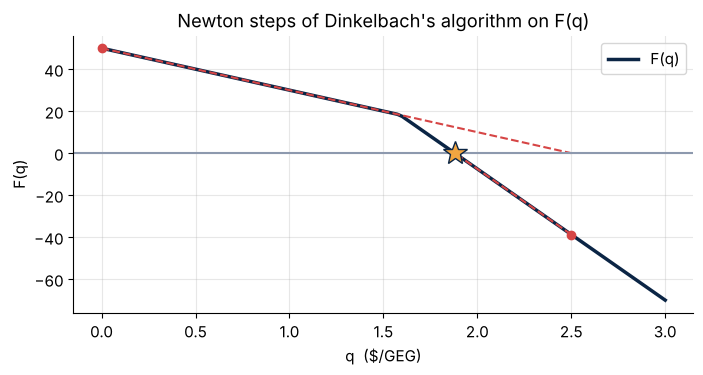

In [ ]:
qs = np.linspace(0, 3, 121)
Fq = [milp(N_c - q*D_c, constraints=LinearConstraint(A_bio, -np.inf, b_bio), integrality=INT, bounds=Bounds(LBZ, UBZ)).fun for q in qs]
plt.plot(qs, Fq, color=NAVY, lw=2.5, label="F(q)")
for q, F, slope in hist_dk:
    qq = np.linspace(q, q - F/slope, 20)
    plt.plot(qq, F + slope*(qq - q), "--", color=RED); plt.plot(q, F, "o", color=RED)
plt.axhline(0, color=GRAY); plt.plot(q_dk, 0, "*", ms=18, color=GOLD, mec=NAVY)
plt.xlabel("q  ($/GEG)"); plt.ylabel("F(q)"); plt.title("Newton steps of Dinkelbach's algorithm on F(q)"); plt.legend(); plt.show()

**Way 3 · reformulation–linearization: ONE MILP.** Charnes–Cooper ($g = 1/D$, $s = g\,x$) makes every row $a_x x + a_y y \le b$ become $a_x s + a_y w - b\,g \le 0$ with $w = g\,y$, and **Glover's** linearization makes $w = g\,y$ exact using $M = 1/D_{min}$:

In [ ]:
def reformulation_linearization(A, b):
    """Charnes–Cooper (g = 1/D, s = g·x) + Glover (w = g·y)  →  ONE MILP.   v = [s(3), y(3), w(3), g]."""
    M = 1.0/Dmin                                       # g = 1/D <= 1/Dmin  is a valid big-M
    nv = 10
    c = np.r_[var, 0, 0, 0, Fix, 0]                    # N·g = var·s + Fix·w
    rows, rhs = [], []
    for i in range(len(b)):                            # every original row  a_x·x + a_y·y <= b_i   becomes
        r = np.zeros(nv); r[0:3] = A[i, :3]; r[6:9] = A[i, 3:]; r[9] = -b[i]   #  a_x·s + a_y·w − b_i·g <= 0
        rows.append(r); rhs.append(0)
    for i in range(3):                                 # Glover:  w_i <= M y_i,  w_i <= g,  w_i >= g − M(1 − y_i)
        r = np.zeros(nv); r[6 + i] = 1; r[3 + i] = -M; rows.append(r); rhs.append(0)
        r = np.zeros(nv); r[6 + i] = 1; r[9] = -1; rows.append(r); rhs.append(0)
        r = np.zeros(nv); r[6 + i] = -1; r[9] = 1; r[3 + i] = M; rows.append(r); rhs.append(M)
    eq = np.r_[1, 1, 1, np.zeros(7)]                   # D·g = Σ s_i = 1
    cons = [LinearConstraint(np.array(rows), -np.inf, rhs), LinearConstraint(eq, 1, 1)]
    res = milp(c, constraints=cons, integrality=np.r_[0, 0, 0, 1, 1, 1, 0, 0, 0, 0],
               bounds=Bounds(np.zeros(nv), np.r_[np.full(3, np.inf), 1, 1, 1, np.full(3, M), M]))
    s, y, g = res.x[:3], np.round(res.x[3:6]), res.x[9]
    return res.fun, np.round(s/g, 6) + 0.0, y

q_rl, x_rl, y_rl = reformulation_linearization(A_bio, b_bio)
print(f"R-L single MILP:  q* = {q_rl:.4f} $/GEG,  plants = {y_rl.astype(int)},  x = {np.round(x_rl, 2)}")

R-L single MILP:  q* = 1.8800 $/GEG,  plants = [0 1 0],  x = [ 0.  62.5  0. ]


🧠 Three methods, one answer: **\$1.88/GEG** with the large plant B running at its biomass limit (62.5 M GEG/yr). Minimizing *total* cost would instead build the small plant A at the minimum production (\$2.50/GEG): economies of scale only show up **per functional unit**.

### ε-constraint: unit cost vs. unit emission

Add $\dfrac{\sum_i e_i x_i}{\sum_i x_i} \le \varepsilon$, which is linear after multiplying by $\sum_i x_i > 0$: $\;\sum_i (e_i - \varepsilon)\,x_i \le 0$. Sweep $\varepsilon$:

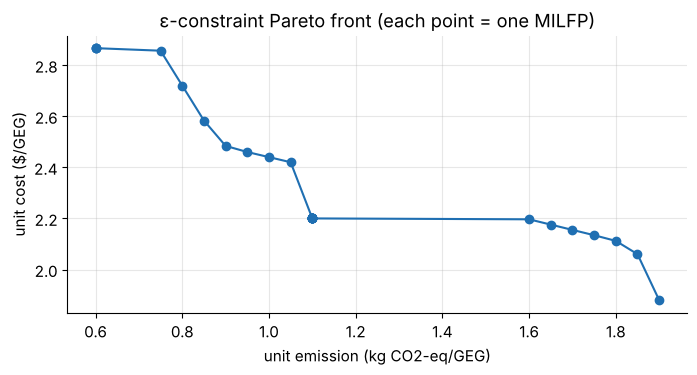

ε = 0.60:  unit emission = 0.60 kg/GEG,  unit cost = 2.867 $/GEG,  plants (A,B,C) = (0, 0, 1)
ε = 0.80:  unit emission = 0.80 kg/GEG,  unit cost = 2.720 $/GEG,  plants (A,B,C) = (1, 0, 1)
ε = 1.00:  unit emission = 1.00 kg/GEG,  unit cost = 2.440 $/GEG,  plants (A,B,C) = (1, 0, 1)
ε = 1.20:  unit emission = 1.10 kg/GEG,  unit cost = 2.200 $/GEG,  plants (A,B,C) = (1, 0, 0)
ε = 1.40:  unit emission = 1.10 kg/GEG,  unit cost = 2.200 $/GEG,  plants (A,B,C) = (1, 0, 0)
ε = 1.60:  unit emission = 1.60 kg/GEG,  unit cost = 2.197 $/GEG,  plants (A,B,C) = (1, 1, 0)
ε = 1.80:  unit emission = 1.80 kg/GEG,  unit cost = 2.112 $/GEG,  plants (A,B,C) = (0, 1, 1)


In [ ]:
front = []
for eps in np.linspace(0.6, 1.9, 27):
    A_e, b_e = bio_constraints(eps)
    try:
        z, q, _ = dinkelbach(A_e, b_e, verbose=False)
        front.append((eps, emis @ z[:3]/z[:3].sum(), q, tuple(int(v) for v in np.round(z[3:]))))
    except Exception:
        pass
_, em, qq, ys_ = zip(*front)
plt.plot(em, qq, "o-", color=BLUE)
plt.xlabel("unit emission (kg CO2-eq/GEG)"); plt.ylabel("unit cost ($/GEG)"); plt.title("ε-constraint Pareto front (each point = one MILFP)")
plt.show()
for eps, e_, q_, y_ in front[::4]:
    print(f"ε = {eps:.2f}:  unit emission = {e_:.2f} kg/GEG,  unit cost = {q_:.3f} $/GEG,  plants (A,B,C) = {y_}")

### 🧩 Exercise 10 — more biomass

Increase the biomass supply to $S = 1.5$ Mt/yr. What is the new optimal unit cost and which plant(s) operate? *Hint:* `bio_constraints(S=1.5)` then `dinkelbach(...)`.

<details><summary><b>👉 Show solution</b></summary>

```python
A15, b15 = bio_constraints(S=1.5)
z, q, _ = dinkelbach(A15, b15)
print(q, np.round(z, 2))
```
$q^* = $ **\$1.775/GEG**: plant B now runs at its **capacity** (80 M GEG/yr) instead of the biomass limit, spreading its \$30 M fixed cost over more fuel.

</details>

In [ ]:
# ✍️ Your answer to Exercise 10

## 🏁 Wrap-up

| You implemented | Function(s) | Remember |
|---|---|---|
| Standard convex MINLP form | `ConvexMINLP` | every $x$-constraint in $g(x) + By \le 0$ |
| Robust NLP subproblems | `solve_nlp_fixed_y`, `solve_feasibility_nlp`, `nlp_relaxation` | never call a problem infeasible just because a local solver failed |
| Branch & bound | `branch_and_bound`, `draw_tree` | relax → bound → prune; best-first saves nodes |
| Outer Approximation | `oa_cuts`, `solve_master`, `integer_cut`, `outer_approximation` | strongest bounds, fewest iterations |
| Generalized Benders | `kkt_multipliers`, `generalized_benders` | small masters, weaker bounds |
| Extended cutting plane | `extended_cutting_plane` | MILPs only, slow near curved boundaries |
| Global optimization | `mccormick`, `spatial_bb_1d`, `haverly_spatial_bb` | relax nonconvex terms, branch on continuous variables |
| Fractional objectives | `dinkelbach`, `reformulation_linearization` | Newton on $F(q)$ or one exact MILP |

**Next:** 📝 Quiz 5 · 🧩 Assignment 5 (formulate and solve a heat-exchanger-network or process-synthesis MINLP with Pyomo).

**References:** Duran & Grossmann, *Math. Prog.* 36 (1986) · Geoffrion, *JOTA* 10 (1972) · Westerlund & Pettersson, *Comput. Chem. Eng.* 19 (1995) · McCormick, *Math. Prog.* 10 (1976) · Haverly, *ACM SIGMAP Bull.* 25 (1978) · Kocis & Grossmann, *Ind. Eng. Chem. Res.* 26 (1987) · Dinkelbach, *Manag. Sci.* 13 (1967) · Charnes & Cooper, *Naval Res. Logist. Q.* 9 (1962) · Glover, *Manag. Sci.* 22 (1975) · Bernal et al., MindtPy, *Comput. Aided Chem. Eng.* 44 (2018).

---
<div align="center">

**© 2026 Abdulelah S. Alshehri. All rights reserved.**<br>
CHE 581: Process Optimization · College of Engineering — King Saud University<br>
<sub>This material may not be reproduced or distributed without written permission of the author.</sub>

</div>